# Data import

In [2]:
import scanpy as sc
import pandas as pd
import tarfile
import os

meta = pd.read_csv("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/human_normal.csv")

base = "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/"
tmp = base + "/tmp"

os.makedirs(tmp, exist_ok=True)

ads = []

for _, r in meta.iterrows():

    sample = r["Sample name"]
    tar_path = f"{base}/{sample}.tar.gz"

    with tarfile.open(tar_path) as tar:
        tar.extractall(tmp)

    path = f"{tmp}/work/{sample}"

    ad = sc.read_10x_mtx(path, var_names="gene_symbols", cache=False)

    ad.obs_names = sample + "_" + ad.obs_names.astype(str)

    for c in meta.columns:
        ad.obs[c] = r[c]

    ad.obs["sample"] = sample

    ads.append(ad)

adata = sc.concat(ads, join="inner")
adata.write("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/raw_total.h5ad")

# Data preprocess

In [5]:
import scanpy as sc
file_path = "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/raw_total.h5ad"
adata = sc.read_h5ad(file_path)

In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS","RPL"))
adata.var["hb"] = adata.var_names.str.startswith(("HBA","HBB"))

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt","ribo","hb"],
    inplace=True,
    log1p=True)

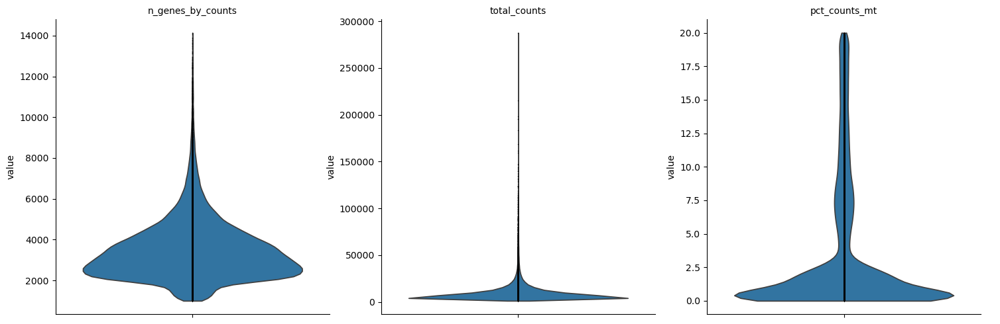

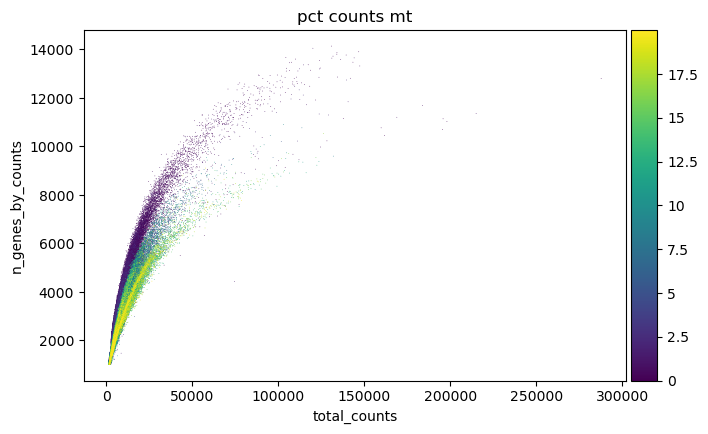

In [7]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.0,
    multi_panel=True,
)
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

Before QC: (109988, 36601)


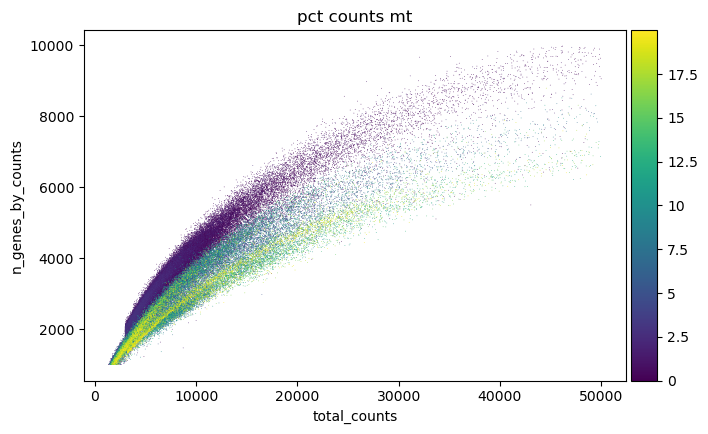

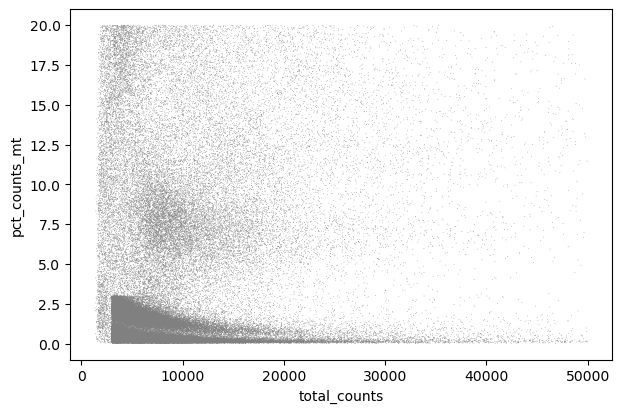

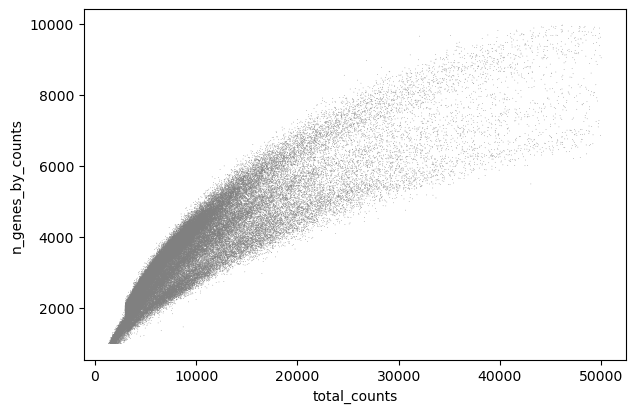

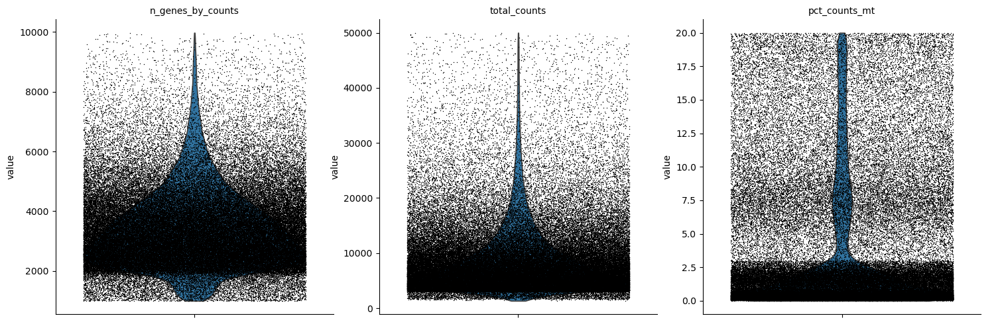

After QC: (109063, 33854)


In [8]:
print("Before QC:", adata.shape)

sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs.n_genes_by_counts <= 10000), :]
adata = adata[adata.obs.pct_counts_mt < 20, :].copy()
adata = adata[(adata.obs.total_counts >= 500) & (adata.obs.total_counts <= 50000), :]

sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts")
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)
print("After QC:", adata.shape)

In [9]:
adata.write("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

In [28]:
import scanpy as sc
file_path = "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad"
adata = sc.read_h5ad(file_path)

In [29]:
adata

AnnData object with n_obs × n_vars = 109063 × 33854
    obs: 'Sample name', 'Organism', 'Individual', 'Developmental stage', 'Sex', 'Organism part', 'Disease', 'Cycle', 'Age', 'Age group', 'Dataset', 'Hormonal treatment', '10x technology', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'

In [6]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

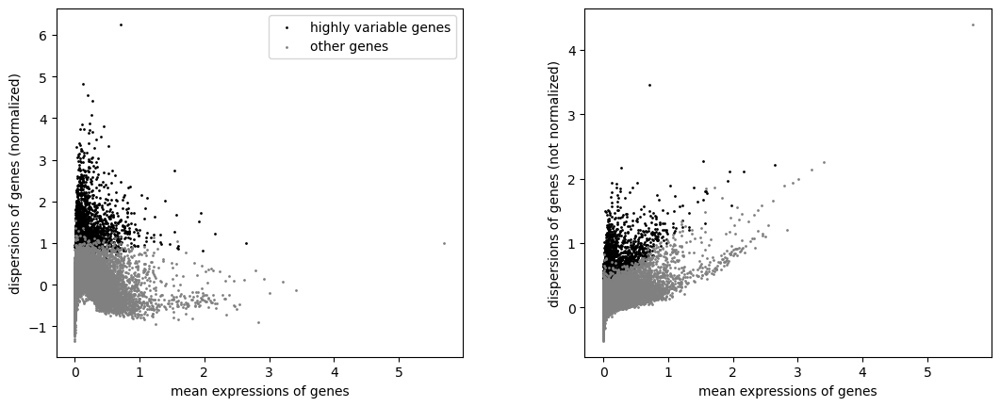

In [7]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="Sample name")
sc.pl.highly_variable_genes(adata)

In [8]:
adata = adata[:, adata.var['highly_variable']].copy()

# Clustering 

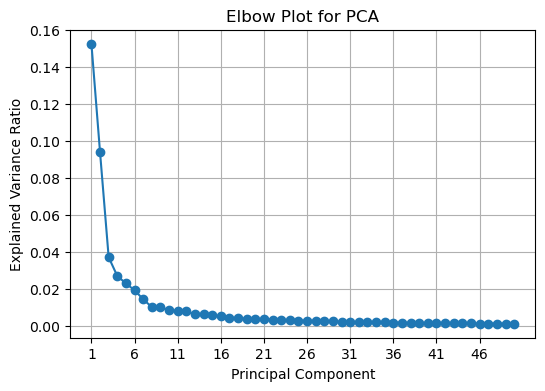

In [9]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

sc.tl.pca(adata)
explained_variance_ratio = adata.uns["pca"]["variance_ratio"]

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker="o", linestyle="-")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Elbow Plot for PCA")
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, step=5))
plt.grid()
plt.show()

In [10]:
sc.tl.pca(adata, n_comps=31)

/home/Data_Drive_8TB/kykim/.conda/envs/kykim/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


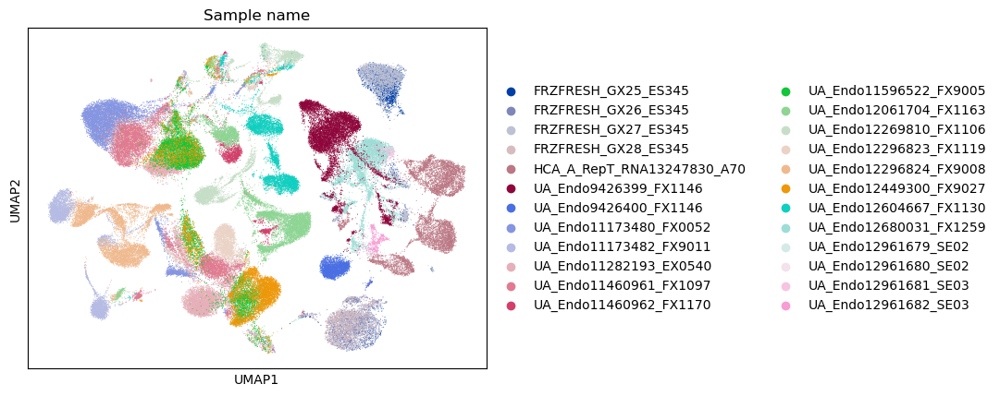

In [11]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color="Sample name",
    # Setting a smaller point size to get prevent overlap
    size=2)

In [12]:
import scvi 

scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="Sample name")
vae = scvi.model.SCVI(adata, n_layers=2, n_latent=30, gene_likelihood="nb")

vae.train(max_epochs=400, early_stopping=True, early_stopping_patience=10)

Trainer will use only 1 of 6 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=6)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX A5000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5]
/

Epoch 297/400:  74%|███████▍  | 297/400 [31:44<11:00,  6.41s/it, v_num=1, train_loss_step=904, train_loss_epoch=882]    
Monitored metric elbo_validation did not improve in the last 10 records. Best score: 870.260. Signaling Trainer to stop.


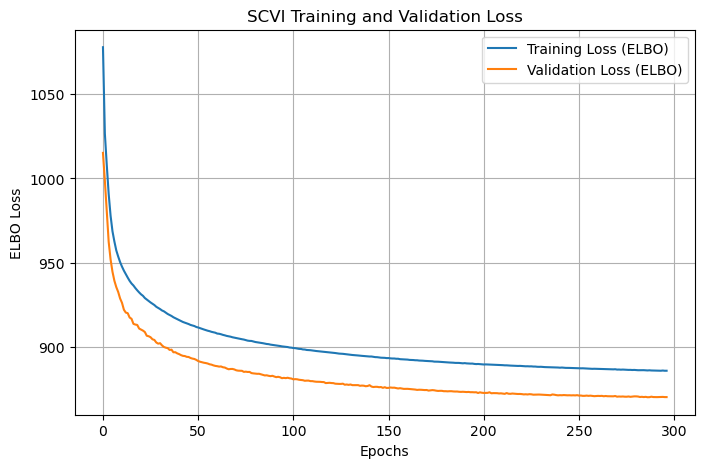

In [13]:
import matplotlib.pyplot as plt

train_loss = vae.history["elbo_train"]
val_loss = vae.history["elbo_validation"]
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss (ELBO)")
plt.plot(val_loss, label="Validation Loss (ELBO)")
plt.xlabel("Epochs")
plt.ylabel("ELBO Loss")
plt.title("SCVI Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

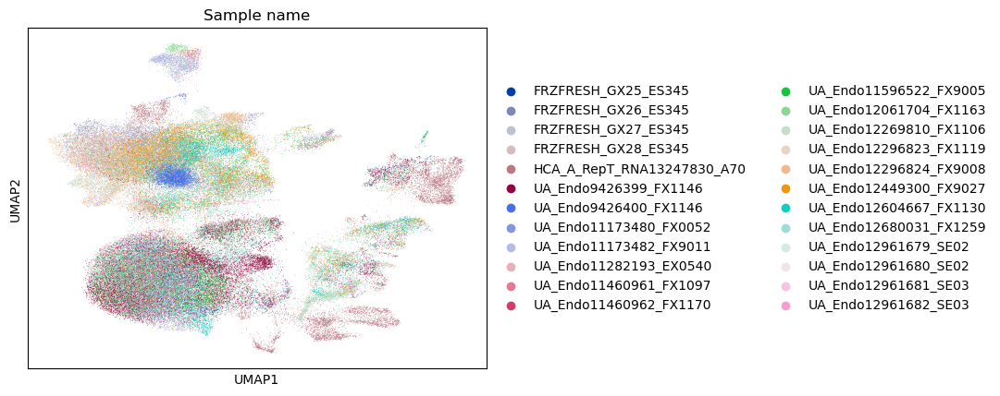

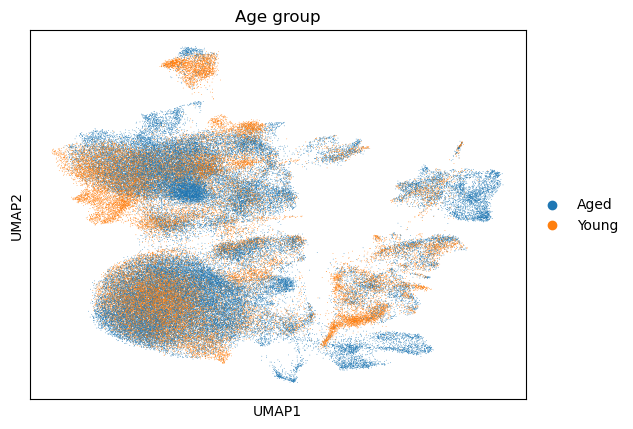

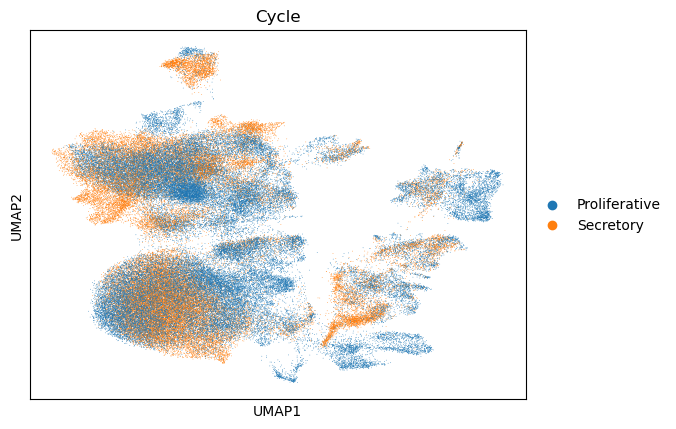

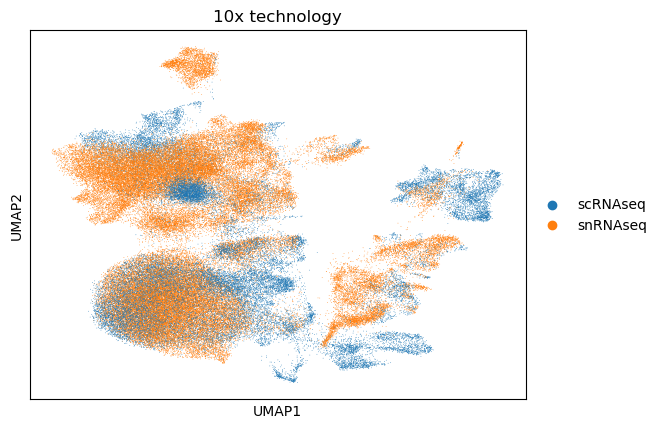

In [14]:
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, use_rep = 'X_scVI')
sc.tl.umap(adata)

sc.pl.umap(adata, color=["Sample name"])
sc.pl.umap(adata, color=["Age group"])
sc.pl.umap(adata, color=["Cycle"])
sc.pl.umap(adata, color=['10x technology'])

In [16]:
import scanpy as sc

for res in [0.25 , 0.5, 0.75, 1]:
    sc.tl.leiden(
        adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

Cluster 0: ['IGFBP7', 'PDGFRB', 'NOTCH3', 'MYL9', 'TAGLN', 'ACTA2', 'C11orf96', 'IGFBP5', 'TIMP3', 'CAV1']
Cluster 1: ['A2M', 'EGFL7', 'VWF', 'PECAM1', 'ENG', 'ADGRL4', 'ARHGAP29', 'PTPRB', 'HLA-B', 'IGFBP7']
Cluster 2: ['TMEM101', 'ASRGL1', 'PAPSS1', 'SAT1', 'LINC01541', 'KIAA1324', 'USP53', 'PPM1H', 'GABRP', 'PLCB1']
Cluster 3: ['COL3A1', 'IGF1', 'COL1A1', 'MEG3', 'CDH11', 'COL5A1', 'PLEKHH2', 'RORB', 'EDNRA', 'NR2F2-AS1']
Cluster 4: ['IGF1', 'APCDD1', 'COL3A1', 'VCAN', 'PDGFRA', 'COL1A1', 'WT1', 'COL6A3', 'CDH11', 'RAMP1']
Cluster 5: ['IGF1', 'CDH11', 'NRP1', 'PTCH1', 'COL3A1', 'CACNA1D', 'ALDH1A2', 'NR2F2-AS1', 'COL5A1', 'TSHZ3']
Cluster 6: ['MECOM', 'TMEM101', 'RHEX', 'UGT2B7', 'DCDC2', 'PTPRM', 'SHROOM3', 'FGFR2', 'LINC01541', 'RNF180']
Cluster 7: ['CPM', 'TMEM101', 'ASRGL1', 'LINC01541', 'SAT1', 'SMAD9', 'LINC01480', 'PAPSS1', 'MSX1', 'KIAA1324']
Cluster 8: ['CDH11', 'COL3A1', 'EDNRA', 'ADAM12', 'NR2F2-AS1', 'MMP11', 'SFRP4', 'COL1A1', 'IGF1', 'LSAMP']
Cluster 9: ['COL3A1', 'SFR

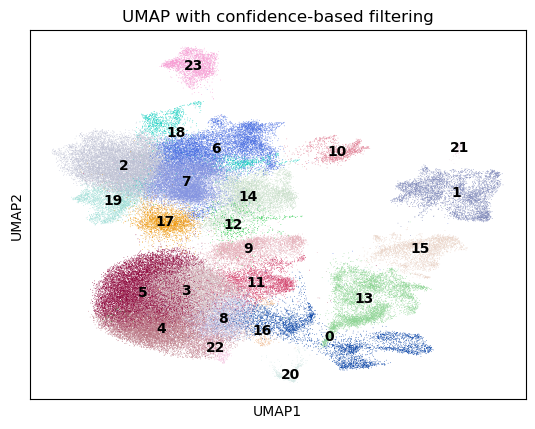

In [18]:
import scanpy as sc
import warnings
warnings.filterwarnings("ignore")

sc.tl.rank_genes_groups(adata, groupby='leiden_res_1.00', method='t-test')  # 또는 'wilcoxon'

top_genes = {}

groups = adata.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들

for group in groups:
    genes = adata.uns['rank_genes_groups']['names'][group][:10]
    top_genes[group] = genes.tolist()

for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")
sc.pl.umap(
    adata,
    color='leiden_res_1.00',
    title='UMAP with confidence-based filtering',
    legend_loc='on data')

In [19]:
import scanpy as sc

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = adata.obs_names.intersection(adata_source.obs_names)

adata = adata[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata._X = adata_source.X.copy()
adata._var = adata_source.var.copy()
adata._n_vars = adata_source.n_vars

In [20]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

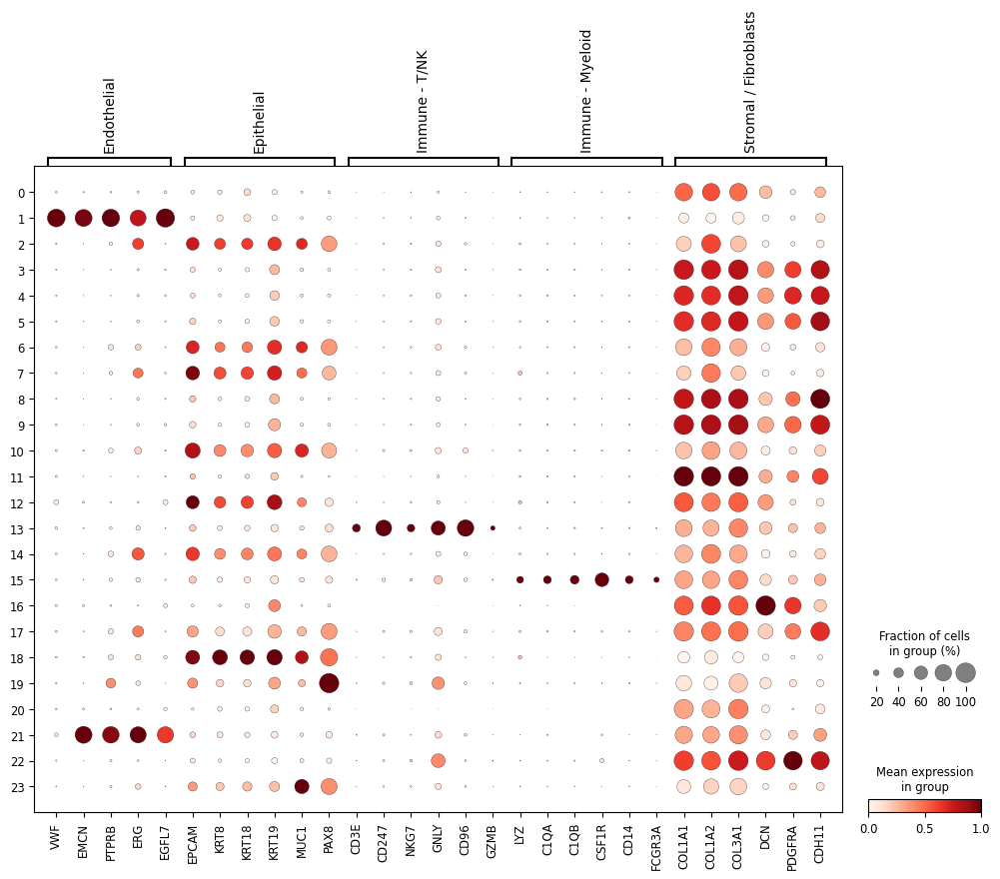

In [21]:
group_markers = {
"Endothelial": ["VWF","EMCN","PTPRB","ERG","EGFL7"],
"Epithelial": ["EPCAM","KRT8","KRT18","KRT19","MUC1","PAX8"],
"Immune - T/NK": ["CD3E","CD247","NKG7","GNLY","CD96","GZMB"],
"Immune - Myeloid": ["LYZ","C1QA","C1QB","CSF1R","CD14","FCGR3A"],
"Stromal / Fibroblasts": ["COL1A1","COL1A2","COL3A1","DCN","PDGFRA","CDH11"]}

existing_genes = {
    cat: [gene for gene in genes if gene in adata.var_names]
    for cat, genes in group_markers.items()
}

existing_genes = {cat: genes for cat, genes in existing_genes.items() if genes}

sc.pl.dotplot(
    adata,
    var_names=existing_genes,
    groupby="leiden_res_1.00",
    standard_scale="var")

Cluster Endothelial cells: ['A2M', 'EGFL7', 'SPTBN1', 'VWF', 'PECAM1', 'ADGRL4', 'ENG', 'APP', 'ARHGAP29', 'HLA-E', 'PTPRB', 'IGFBP7', 'EMCN', 'HLA-B', 'CALCRL', 'FLT1', 'DIPK2B', 'HSPG2', 'HLA-A', 'CLEC14A']
Cluster Epithelial cells: ['TMEM101', 'LINC01541', 'ASRGL1', 'STX18', 'UBE2D2', 'RHEX', 'EYA2', 'MECOM', 'PLCB1', 'SAT1', 'AC024230.1', 'PATJ', 'WWC1', 'KIAA1324', 'SORBS2', 'GABRP', 'L3MBTL4', 'PAPSS1', 'PPP1R9A', 'RBM47']
Cluster Immune - Lymphoid: ['PTPRC', 'CD96', 'CELF2', 'SKAP1', 'IKZF1', 'CD247', 'ANKRD44', 'DOCK10', 'PRKCH', 'FYN', 'DOCK8', 'ARHGAP15', 'MBNL1', 'FYB1', 'SAMD3', 'PARP8', 'LCP2', 'SLFN12L', 'STAT4', 'WIPF1']
Cluster Immune - Myeloid: ['DOCK2', 'DOCK8', 'PTPRC', 'ELMO1', 'ZEB2', 'TBXAS1', 'MS4A6A', 'FAM49B', 'MARCH1', 'FYB1', 'PLXDC2', 'SLC8A1', 'ARHGAP15', 'MEF2C', 'APBB1IP', 'DPYD', 'FCHSD2', 'LRMDA', 'CYBB', 'ADAP2']
Cluster Stromal / Fibroblasts: ['COL3A1', 'IGF1', 'COL1A1', 'CDH11', 'COL6A1', 'COL6A2', 'COL5A1', 'MEG3', 'COL6A3', 'NR2F2', 'NR2F2-AS1', 'C

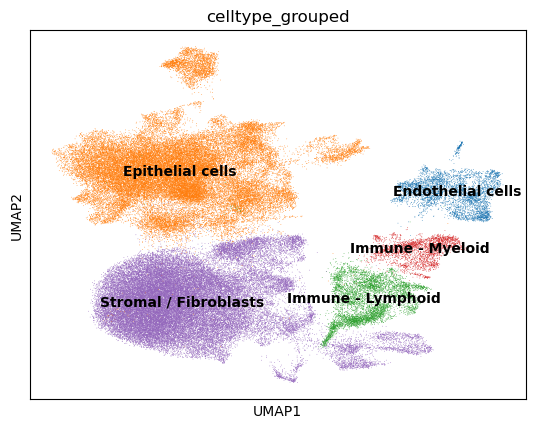

In [29]:
cluster_to_group = {
0: "Stromal / Fibroblasts", 
1: "Endothelial cells",
2: "Epithelial cells", 
3: "Stromal / Fibroblasts", 
4: "Stromal / Fibroblasts", 
5: "Stromal / Fibroblasts", 
6: "Epithelial cells", 
7: "Epithelial cells", 
8: "Stromal / Fibroblasts", 
9: "Stromal / Fibroblasts", 
10: "Epithelial cells", 
11: "Stromal / Fibroblasts", 
12: "Epithelial cells", 
13: "Immune - Lymphoid", #
14: "Epithelial cells", #
15: "Immune - Myeloid", #
16: "Stromal / Fibroblasts", #
17: "Epithelial cells", #
18: "Epithelial cells", #
19: "Epithelial cells", #
20: "Stromal / Fibroblasts", #
21: "Endothelial cells", #
22: "Stromal / Fibroblasts", #
23: "Epithelial cells"}

adata.obs["celltype_grouped"] = adata.obs["leiden_res_1.00"].astype(int).map(cluster_to_group)

sc.tl.rank_genes_groups(adata, groupby='celltype_grouped', method='t-test')  # 또는 'wilcoxon'

top_genes = {}

groups = adata.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들

for group in groups:
    genes = adata.uns['rank_genes_groups']['names'][group][:20]
    top_genes[group] = genes.tolist()

for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")
    
sc.pl.umap(
    adata,
    color='celltype_grouped',
    legend_loc='on data')

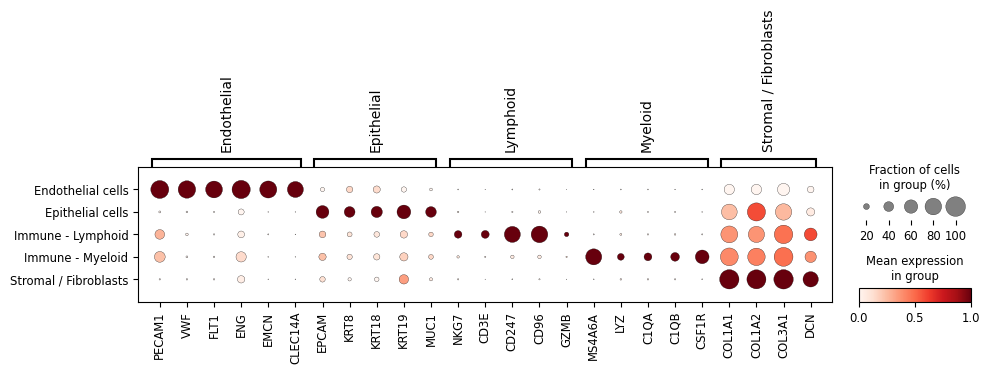

In [31]:
group_markers = {
"Endothelial": ["PECAM1","VWF","FLT1","ENG","EMCN","CLEC14A"],
"Epithelial": ["EPCAM","KRT8","KRT18","KRT19","MUC1"],
"Lymphoid": ["NKG7","CD3E","CD247","CD96","GZMB"],
"Myeloid": ["MS4A6A","LYZ","C1QA","C1QB","CSF1R"],
"Stromal / Fibroblasts": ["COL1A1","COL1A2","COL3A1","DCN"]}
existing_genes = {
    cat: [gene for gene in genes if gene in adata.var_names]
    for cat, genes in group_markers.items()
}

existing_genes = {cat: genes for cat, genes in existing_genes.items() if genes}

sc.pl.dotplot(
    adata,
    var_names=existing_genes,
    groupby="celltype_grouped",
    standard_scale="var")

In [32]:
adata.__dict__['_varm'].clear()
adata.__dict__['_layers'].clear()

In [33]:
adata.write("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/After_Clustering.h5ad")

In [22]:
import scanpy as sc
adata = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/After_Clustering.h5ad")

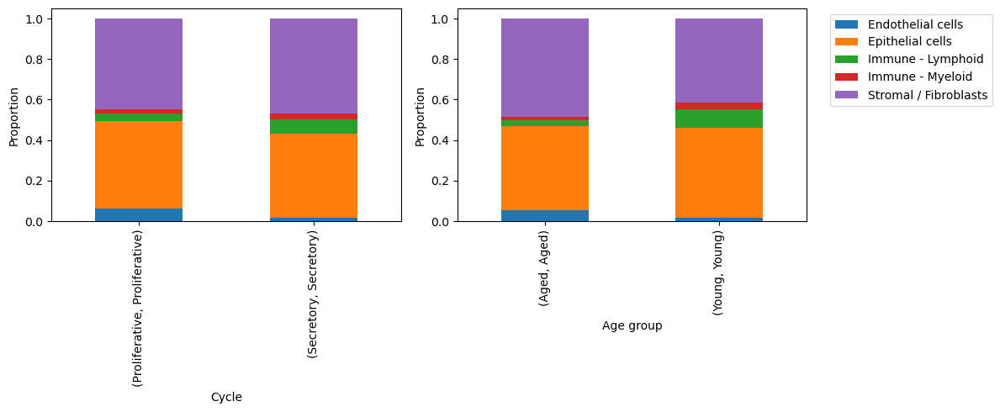

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df1 = adata.obs[['Cycle','celltype_grouped']].copy()
prop1 = (
    df1.groupby(['Cycle','celltype_grouped'])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .unstack(fill_value=0)
)
prop1.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('Cycle')
axes[0].set_ylabel('Proportion')

df2 = adata.obs[['Age group','celltype_grouped']].copy()
prop2 = (
    df2.groupby(['Age group','celltype_grouped'])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .unstack(fill_value=0)
)
prop2.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('Age group')
axes[1].set_ylabel('Proportion')

axes[1].legend(bbox_to_anchor=(1.05,1), loc='upper left')
axes[0].legend().remove()

plt.tight_layout()
plt.show()

Processing genesets:  20%|██        | 1/5 [00:01<00:05,  1.45s/it]

Error processing Immune - Myeloid for CellMarker_2024: Error analyzing gene list
Error processing Stromal / Fibroblasts for CellMarker_Augmented_2021: Error analyzing gene list
Error processing Immune - Lymphoid for CellMarker_Augmented_2021: Error analyzing gene list
Error processing Epithelial cells for PanglaoDB_Augmented_2021: Error analyzing gene list
Error processing Immune - Lymphoid for CellMarker_2024: Error analyzing gene list
Error processing Stromal / Fibroblasts for PanglaoDB_Augmented_2021: Error analyzing gene list
Error processing Endothelial cells for CellMarker_2024: Error analyzing gene list
Error processing Epithelial cells for CellMarker_2024: Error analyzing gene list
Error processing Endothelial cells for CellMarker_Augmented_2021: Error analyzing gene list
Error processing Immune - Lymphoid for PanglaoDB_Augmented_2021: Error analyzing gene list


Processing genesets: 15it [00:02,  5.97it/s]                      


Trying to re-request...
Endothelial cells with CellMarker_2024 completed!
Endothelial cells with CellMarker_Augmented_2021 completed!
Epithelial cells with CellMarker_2024 completed!
Epithelial cells with PanglaoDB_Augmented_2021 completed!
Immune - Lymphoid with CellMarker_2024 completed!
Immune - Lymphoid with CellMarker_Augmented_2021 completed!
Immune - Lymphoid with PanglaoDB_Augmented_2021 completed!
Immune - Myeloid with CellMarker_2024 completed!
Stromal / Fibroblasts with CellMarker_Augmented_2021 completed!
Stromal / Fibroblasts with PanglaoDB_Augmented_2021 completed!


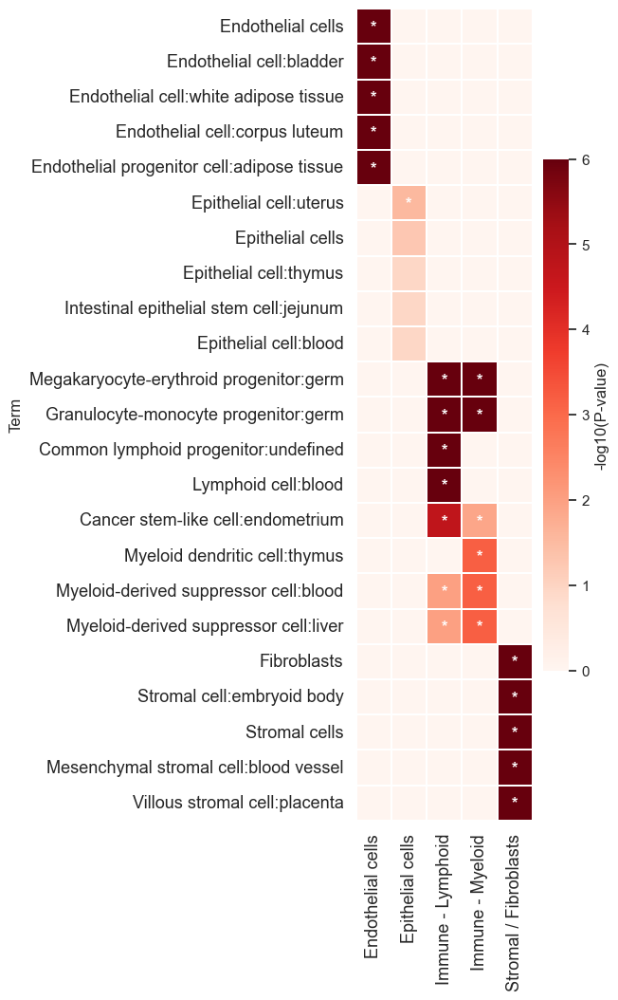

In [23]:
import pandas as pd
import scanpy as sc
import sys
sys.path.append("/home/Data_Drive_8TB/kykim/QED")
from qed.data import readtxt, readseurat, readscanpy
from qed.data import get_enrichment_dataframes
from qed.data import merge_df
from qed.data import query
import inspect
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sc.tl.rank_genes_groups(adata, 'celltype_grouped', method="wilcoxon",use_raw =False)
sc.tl.dendrogram(adata, groupby='celltype_grouped')

result = adata.uns["rank_genes_groups"]
groups = result["names"].dtype.names  # 예: ("Tcells", "Bcells", ...)
result_df = pd.DataFrame(
    {
        f"{group}_{key}": result[key][group]
        for group in groups
        for key in ["names", "pvals_adj", "logfoldchanges", "scores"]
    }
)

up_dict = {}
down_dict = {}

for group in groups:
    n_col = f"{group}_names"
    p_col = f"{group}_pvals_adj"
    l_col = f"{group}_logfoldchanges"
    s_col = f"{group}_scores"

    degs_sig = result_df[result_df[p_col] < 0.05]
    degs_up = degs_sig[degs_sig[l_col] > 1].sort_values(by=s_col, ascending=False)
    degs_dw = degs_sig[degs_sig[l_col] < -1].sort_values(by=s_col, ascending=True)
    up_dict[group] = degs_up[n_col].reset_index(drop=True)
    down_dict[group] = degs_dw[n_col].reset_index(drop=True)

df_merge_up = pd.concat(up_dict.values(), axis=1)
df_merge_up.columns = list(up_dict.keys())  # 각 열 이름을 group 이름으로
df_merge_down = pd.concat(down_dict.values(), axis=1)
df_merge_down.columns = list(down_dict.keys())
sc.tl.dendrogram(adata, groupby='celltype_grouped')

import pandas as pd
import scanpy as sc

result = adata.uns["rank_genes_groups"]
groups = result["names"].dtype.names
result_df = pd.DataFrame(
    {
        f"{group}_{key}": result[key][group]
        for group in groups
        for key in ["names", "pvals_adj", "logfoldchanges", "scores"]
    }
)
up_dict = {}
down_dict = {}
for group in groups:
    n_col = f"{group}_names"
    p_col = f"{group}_pvals_adj"
    l_col = f"{group}_logfoldchanges"
    s_col = f"{group}_scores"
    degs_sig = result_df[result_df[p_col] < 0.05]
    degs_up = degs_sig[degs_sig[l_col] > 1].sort_values(by=s_col, ascending=False)
    degs_dw = degs_sig[degs_sig[l_col] < -1].sort_values(by=s_col, ascending=True)
    up_dict[group] = degs_up[n_col].reset_index(drop=True)
    down_dict[group] = degs_dw[n_col].reset_index(drop=True)
df_merge_up = pd.concat(up_dict.values(), axis=1)
df_merge_up.columns = list(up_dict.keys())  # 각 열 이름을 group 이름으로
df_merge_down = pd.concat(down_dict.values(), axis=1)
df_merge_down.columns = list(down_dict.keys())

import pandas as pd

class GeneSet:
    def __init__(self, genes, name, annot=None):
        self.genes = genes
        self.name = name
        self.params = {}
        self.GO = []
        self.annot = annot or {}

dblist = ['CellMarker_2024','CellMarker_Augmented_2021',"PanglaoDB_Augmented_2021"]

df_merge_up_100 = df_merge_up.head(20)
df_merge_up_100.to_csv('breast_cancer_DEG_up_leiden.csv', index=False, header=True)
alist = pd.read_csv('breast_cancer_DEG_up_leiden.csv')
geneset_list = []
for col in alist.columns:
    genes = alist[col].dropna().tolist()
    gs = GeneSet(genes=genes, name=col, annot={"Leiden": col})
    geneset_list.append(gs)

aalist = get_enrichment_dataframes(
    geneset_list=geneset_list,
    dblist=dblist,
    annot_colname="Leiden",
    n_jobs=None,
    handle_error=True,
    max_iter=1
)

df = merge_df(aalist)
df['Term'] = df['Term'].str.split(r'\(GO:').str[0].str.strip()
df['Term'] = df['Term'].str.split('R-H').str[0].str.strip()
df['Term'] = df['Term'].str.split('WP').str[0].str.strip()


from typing import List, Tuple, Dict
def heatmap_with_groupwise_ordering(df: pd.DataFrame,
                                     n: int,
                                     group_by: str,
                                     order_by: str = "Adjusted p-value",
                                     cmap: str = 'Blues',
                                     xlabel_rotation: int = 90,
                                     xlabel_fontsize: int = 15,
                                     ylabel_fontsize: int = 15,
                                     figsize: Tuple = (15, 10),
                                     vmin: float = None,
                                     vmax: float = None,
                                     cbar_kws: Dict = None,
                                     linewidths: float = 0.1,
                                     title: str = None,
                                     save_to_file: str = None,
                                     enable_column_order: bool = False,
                                     column_order: list = None,
                                     enable_highlight_columns: bool = False,
                                     highlight_column_names: list = None):

    if not isinstance(df, pd.DataFrame):
        raise TypeError("입력 'df'는 pandas DataFrame이어야 합니다.")
    if group_by not in df.columns:
        raise ValueError(f"'{group_by}' 컬럼이 DataFrame에 존재하지 않습니다.")
    if order_by not in df.columns:
        raise ValueError(f"'{order_by}' 컬럼이 DataFrame에 존재하지 않습니다.")
    if 'Term' not in df.columns:
        raise ValueError("'Term' 컬럼이 DataFrame에 존재하지 않습니다.")

    has_overlapping_genes = 'Overlapping genes' in df.columns

    df_copy = df.copy()
    df_copy[order_by] = pd.to_numeric(df_copy[order_by], errors='coerce')
    df = df_copy

    df['Term_lower'] = df['Term'].str.lower()

    # 상위 n개 Term 추출
    df_filtered_by_order = df[df[order_by].notna()]
    df_ranked_per_group = (
        df_filtered_by_order
        .sort_values(order_by)
        .groupby(group_by)
        .head(n)
        .reset_index(drop=True)
    )
    if df_ranked_per_group.empty:
        print(f"⚠️ 각 그룹에서 상위 {n}개의 Term을 선택할 수 없습니다.")
        return None, None

    all_selected_terms_lower = df_ranked_per_group['Term_lower'].unique()

    overlapping_genes_pivot = pd.DataFrame()
    if has_overlapping_genes:
        overlapping_genes_df = df[df['Term_lower'].isin(all_selected_terms_lower)][['Term_lower', group_by, 'Overlapping genes']]
        overlapping_genes_df['Overlapping genes'] = overlapping_genes_df['Overlapping genes'].apply(
            lambda x: ', '.join(map(str, x)) if isinstance(x, list) else str(x)
        )
        overlapping_genes_df = overlapping_genes_df.groupby(['Term_lower', group_by])['Overlapping genes'].apply(', '.join).reset_index()
        overlapping_genes_df.rename(columns={'Term_lower': 'Term'}, inplace=True)
        overlapping_genes_pivot = overlapping_genes_df.pivot(index='Term', columns=group_by, values='Overlapping genes').fillna('')
        overlapping_genes_pivot.index = overlapping_genes_pivot.index.map(lambda x: x.capitalize())

    aggregated_df = df[df['Term_lower'].isin(all_selected_terms_lower)].groupby(['Term_lower', group_by], as_index=False)[order_by].min()
    aggregated_df.rename(columns={'Term_lower': 'Term'}, inplace=True)
    pivot_df = aggregated_df.pivot(index="Term", columns=group_by, values=order_by).fillna(1).rename_axis(None, axis=1)

    is_pvalue_column = order_by.lower() in ['adjusted p-value', 'p-value']
    pivot_df_for_heatmap = -np.log10(np.maximum(pivot_df, np.finfo(float).eps)) if is_pvalue_column else pivot_df.copy()
    pivot_df_for_heatmap.index = pivot_df_for_heatmap.index.map(lambda x: x.capitalize())

    final_pivot_df = pd.concat([pivot_df_for_heatmap, overlapping_genes_pivot], axis=1)

    if save_to_file:
        try:
            final_pivot_df.to_csv(save_to_file, encoding='utf-8-sig')
            print(f"✅ 히트맵 데이터 저장 완료: '{save_to_file}'")
        except Exception as e:
            print(f"❌ 저장 실패: {e}")

    row_order = []
    seen_terms = set()

    if enable_column_order and column_order:
        group_order_for_plot = [group for group in column_order if group in df[group_by].unique()]
    else:
        group_order_for_plot = sorted(df[group_by].unique())

    for group in group_order_for_plot:
        current_group_terms = (
            df_ranked_per_group[df_ranked_per_group[group_by] == group]
            .sort_values(order_by)
        )
        for term_lower_val in current_group_terms['Term_lower']:
            capitalized_term = term_lower_val.capitalize()
            if capitalized_term in pivot_df_for_heatmap.index and capitalized_term not in seen_terms:
                row_order.append(capitalized_term)
                seen_terms.add(capitalized_term)

    clustered_data = final_pivot_df.loc[row_order]
    heatmap_data = clustered_data.select_dtypes(include=[np.number])
    if enable_column_order and column_order:
        valid_cols = [c for c in column_order if c in heatmap_data.columns]
        if valid_cols:
            heatmap_data = heatmap_data[valid_cols]

    else:
        try:
            numeric_col_keys = [float(c) for c in heatmap_data.columns]
            sorted_cols = [col for _, col in sorted(zip(numeric_col_keys, heatmap_data.columns))]
            heatmap_data = heatmap_data[sorted_cols]
        except ValueError:
            pass


    if is_pvalue_column:
        p_values_for_annotation = 10 ** (-np.clip(heatmap_data, None, 300))
        annotations = np.where(p_values_for_annotation <= 0.05, '*', '')
        annotations = annotations.astype(object)
    else:
        annotations = False

    highlight_column_indices = []
    if enable_highlight_columns and highlight_column_names:
        highlight_column_indices = [
            list(heatmap_data.columns).index(col)
            for col in highlight_column_names if col in heatmap_data.columns
        ]

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(heatmap_data, cmap=cmap, vmin=vmin, vmax=vmax,
                linewidths=linewidths, annot=annotations, fmt='',
                linecolor='white', ax=ax, cbar_kws=cbar_kws, square=True,
                annot_kws={"size": 12, "color": "white", "weight": "bold"})

    for x in highlight_column_indices:
        ax.vlines(x + 1, *ax.get_ylim(), colors='black', linewidth=2)

    plt.xticks(rotation=xlabel_rotation, fontsize=xlabel_fontsize)
    plt.yticks(fontsize=ylabel_fontsize)
    if title:
        ax.set_title(title, fontsize=18, pad=20)
    plt.grid(False)

    if 'Term_lower' in df.columns:
        df.drop(columns='Term_lower', inplace=True)

    return fig, ax

df_filtered = df[
    df.apply(
        lambda x: any(t in x['Term'] for t in str(x['Leiden']).split()),
        axis=1)]

df_sorted = df_filtered.sort_values(by='Rank')

fig, ax = heatmap_with_groupwise_ordering(
    df= df_sorted,
    n=5,
    group_by='Leiden',
    order_by="Adjusted p-value",
    cmap='Reds',
    xlabel_rotation=90,
    xlabel_fontsize=13,
    ylabel_fontsize=13,
    figsize=(3, 14),
    vmin=0, vmax=6,
    cbar_kws={'shrink': 0.5, 'label': '-log10(P-value)'},
    enable_column_order=False,
    enable_highlight_columns=False)

In [26]:
mask_lymphoid = (
    (df_sorted["Leiden"] == "Immune - Lymphoid") &
    (df_sorted["Term"].str.contains("Lymphoid", case=False, na=False))
)

mask_myeloid = (
    (df_sorted["Leiden"] == "Immune - Myeloid") &
    (df_sorted["Term"].str.contains("Myeloid", case=False, na=False))
)

mask_other = ~df_sorted["Leiden"].isin([
    "Immune - Lymphoid",
    "Immune - Myeloid"
])

df_filtered = df_sorted[
    mask_lymphoid | mask_myeloid | mask_other
].copy()

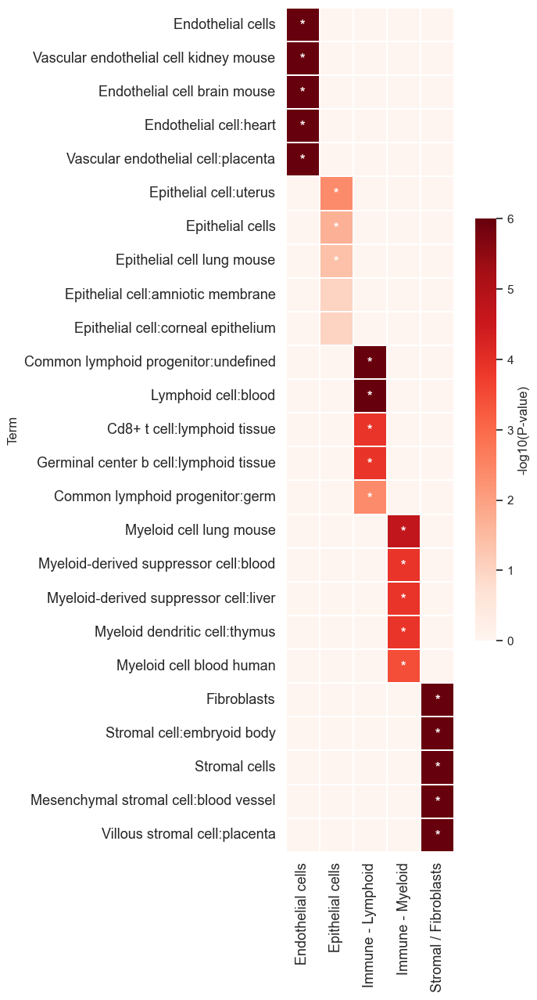

In [28]:
fig, ax = heatmap_with_groupwise_ordering(
    df= df_filtered,
    n=5,
    group_by='Leiden',
    order_by="P-value",
    cmap='Reds',
    xlabel_rotation=90,
    xlabel_fontsize=13,
    ylabel_fontsize=13,
    figsize=(7, 14),
    vmin=0, vmax=6,
    cbar_kws={'shrink': 0.5, 'label': '-log10(P-value)'},
    enable_column_order=False,
    enable_highlight_columns=False)

# Epithelial subtypeing

In [1]:
import scanpy as sc
adata = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/After_Clustering.h5ad")

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = adata.obs_names.intersection(adata_source.obs_names)

adata = adata[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata._X = adata_source.X.copy()
adata._var = adata_source.var.copy()
adata._n_vars = adata_source.n_vars

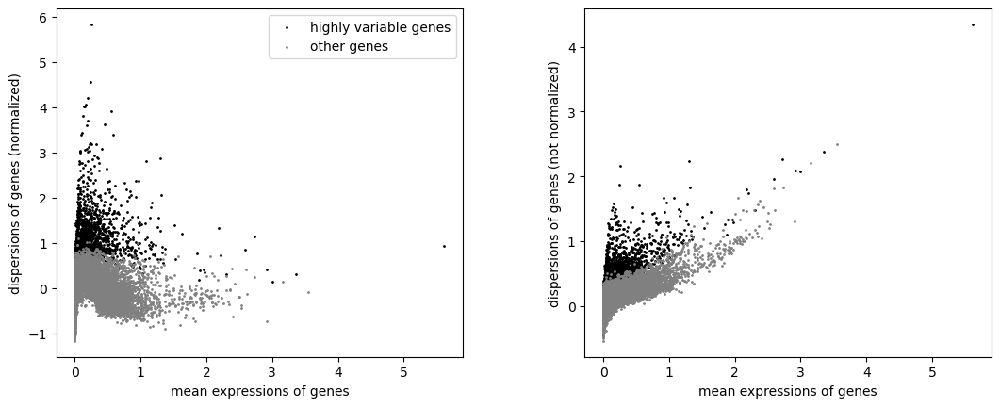

In [2]:
Epithelial = adata[adata.obs['celltype_grouped'] == 'Epithelial cells'].copy()
Epithelial.layers["counts"] = Epithelial.X.copy()
sc.pp.normalize_total(Epithelial)
sc.pp.log1p(Epithelial)

sc.pp.highly_variable_genes(Epithelial, n_top_genes=2000, batch_key="Sample name")
sc.pl.highly_variable_genes(Epithelial)
Epithelial = Epithelial[:, Epithelial.var['highly_variable']].copy()

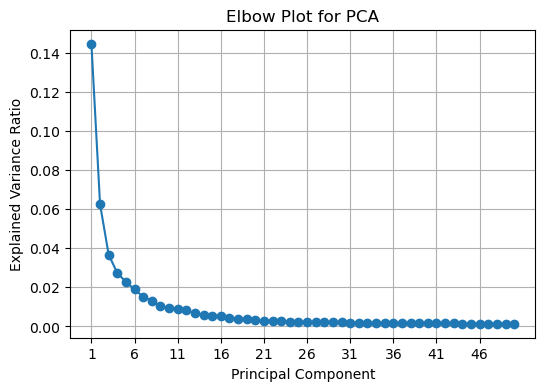

In [3]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

sc.tl.pca(Epithelial)
explained_variance_ratio = Epithelial.uns["pca"]["variance_ratio"]

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker="o", linestyle="-")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Elbow Plot for PCA")
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, step=5))
plt.grid()
plt.show()

In [4]:
sc.tl.pca(Epithelial, n_comps=31)

/home/Data_Drive_8TB/kykim/.conda/envs/kykim/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


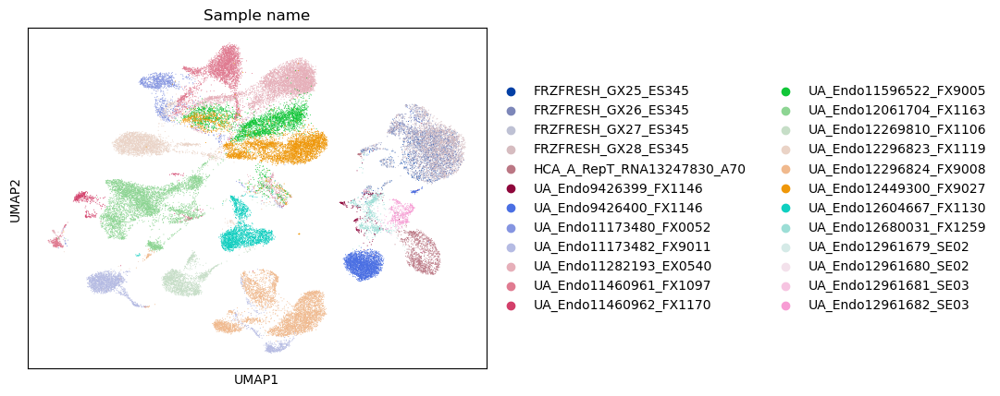

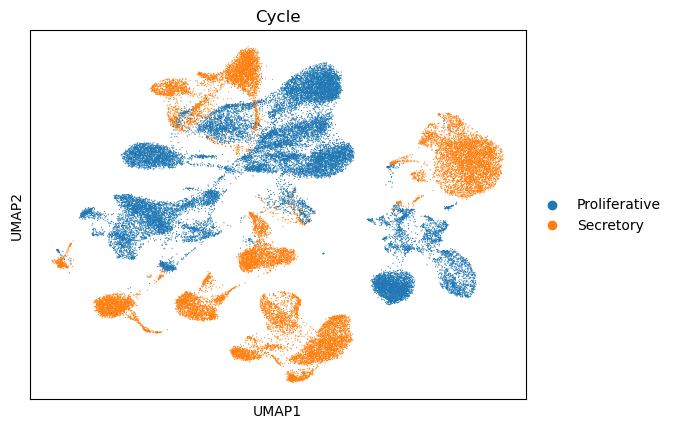

In [5]:
sc.pp.neighbors(Epithelial)
sc.tl.umap(Epithelial)
sc.pl.umap(
    Epithelial,
    color="Sample name",
    # Setting a smaller point size to get prevent overlap
    size=2)
sc.pl.umap(Epithelial, color=["Cycle"])

In [6]:
Epithelial.obs["batch_combined"] = (
    Epithelial.obs["Sample name"].astype(str) + "_" +
    Epithelial.obs["10x technology"].astype(str))

In [7]:
import scvi 
import matplotlib.pyplot as plt

#scvi.model.SCVI.setup_anndata(Epithelial, layer="counts", batch_key="Sample name")
scvi.model.SCVI.setup_anndata(Epithelial, layer="counts", batch_key="batch_combined")
vae = scvi.model.SCVI(Epithelial, n_layers=2, n_latent=30, gene_likelihood="nb")

vae.train(max_epochs=400, early_stopping=False, early_stopping_patience=5)

train_loss = vae.history["elbo_train"]
val_loss = vae.history["elbo_validation"]
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss (ELBO)")
plt.plot(val_loss, label="Validation Loss (ELBO)")
plt.xlabel("Epochs")
plt.ylabel("ELBO Loss")
plt.title("SCVI Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

Trainer will use only 1 of 6 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=6)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX A5000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5]
/

Epoch 400/400: 100%|██████████| 400/400 [16:32<00:00,  2.34s/it, v_num=1, train_loss_step=1.1e+3, train_loss_epoch=1.09e+3] 

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [16:32<00:00,  2.48s/it, v_num=1, train_loss_step=1.1e+3, train_loss_epoch=1.09e+3]


KeyError: 'elbo_validation'

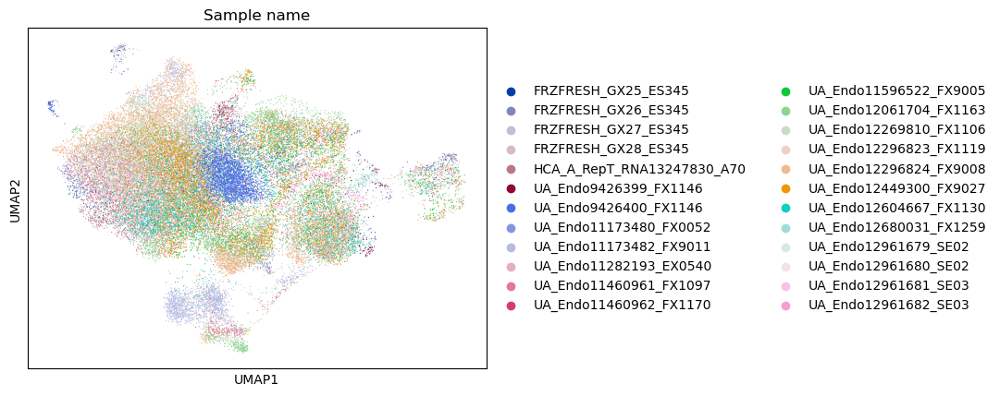

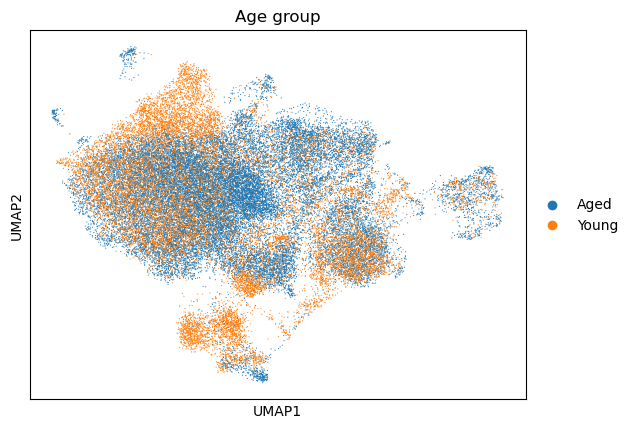

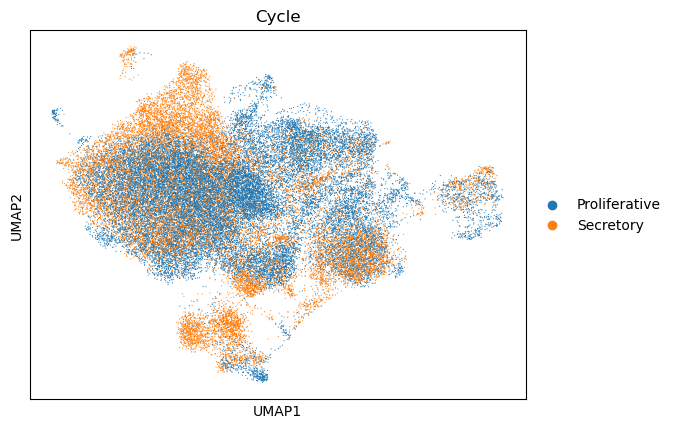

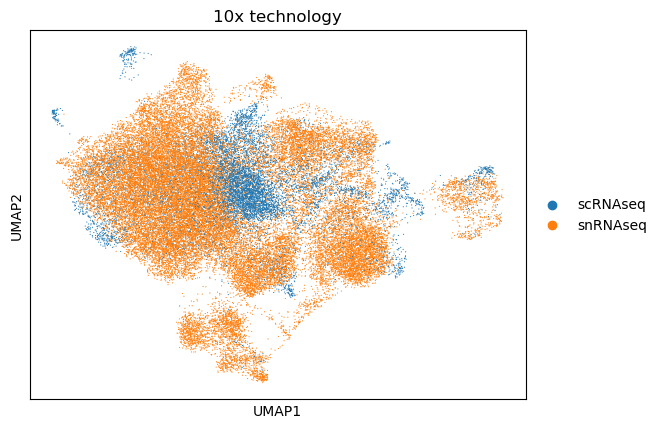

In [8]:
Epithelial.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(Epithelial, use_rep = 'X_scVI')
sc.tl.umap(Epithelial)

sc.pl.umap(Epithelial, color=["Sample name"])
sc.pl.umap(Epithelial, color=["Age group"])
sc.pl.umap(Epithelial, color=["Cycle"])
sc.pl.umap(Epithelial, color=['10x technology'])

In [13]:
Epithelial.__dict__['_varm'].clear()
Epithelial.__dict__['_layers'].clear()

In [14]:
import scanpy as sc

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = Epithelial.obs_names.intersection(adata_source.obs_names)

Epithelial = Epithelial[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata_source = adata_source[Epithelial.obs_names].copy()

Epithelial._X = adata_source.X.copy()
Epithelial._var = adata_source.var.copy()
Epithelial._n_vars = adata_source.n_vars

In [15]:
sc.pp.normalize_total(Epithelial)
sc.pp.log1p(Epithelial)

for res in [0.75,1.00,1.50]:
    sc.tl.leiden(
        Epithelial, key_added=f"leiden_res_{res:4.2f}", resolution=res, 
        flavor="igraph"
    )

Cluster 0: ['TMEM101', 'LINC01541', 'PAPSS1', 'KIAA1324', 'ARHGAP26', 'PRKAG2', 'MTCL1', 'PPM1H', 'MCC', 'SAT1', 'SMAD9', 'PCAT1', 'DNAJC10', 'AC078845.1', 'MAML3', 'USP53', 'RPS6KA5', 'KIF13B', 'IL20RA', 'AC024084.1', 'MAGI1', 'KCNMB2', 'TBC1D8', 'L3MBTL4', 'RANBP17', 'DLG5', 'TLE1', 'LINC02814', 'AC011447.3', 'AC024230.1']
Cluster 1: ['PAPSS1', 'ACSL5', 'ENPP3', 'CREB3L1', 'ASRGL1', 'TPD52L1', 'HGD', 'COL1A2', 'HSD17B2', 'SAT1', 'TMEM101', 'MAP2K6', 'USP53', 'DUOXA1', 'DLG5', 'SGK1', 'IL20RA', 'CBR3', 'MMP26', 'BNIP3L', 'ELP3', 'GABRP', 'LRRC1', 'DUOX1', 'PRKX', 'MPZL2', 'ABCG1', 'ADAMTS8', 'CYB5A', 'GSN']
Cluster 2: ['GDA', 'LGR5', 'PTPRM', 'DST', 'ERBB4', 'KCNMA1', 'CD47', 'PAPOLA', 'NLGN4X', 'VTCN1', 'FGFR2', 'DCDC2', 'KCTD1', 'CCDC6', 'NRXN3', 'BX890604.2', 'IGF2BP2', 'UGT2B7', 'SVIL', 'LIMCH1', 'CERT1', 'PTGS1', 'ITGB8', 'WWTR1', 'MIR31HG', 'LRRC41', 'MET', 'LINC00472', 'HMGCR', 'GPR137C']
Cluster 3: ['ESR1', 'PGR', 'PALLD', 'NPAS3', 'GREM2', 'VWA8', 'EYA2', 'PLCB1', 'CTNNA2', '

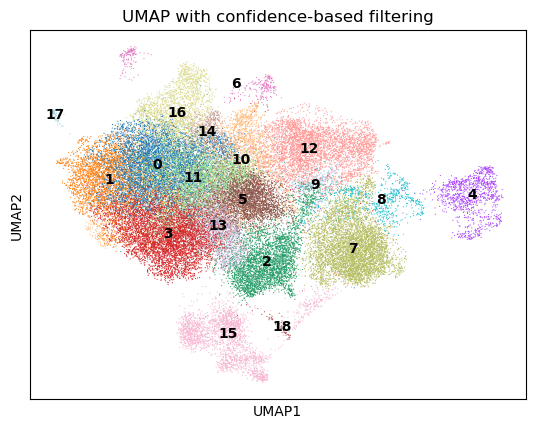

In [16]:
import scanpy as sc
sc.tl.rank_genes_groups(Epithelial, groupby='leiden_res_1.00', method='t-test')  # 또는 'wilcoxon'
top_genes = {}
groups = Epithelial.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들
for group in groups:
    genes = Epithelial.uns['rank_genes_groups']['names'][group][:30]
    top_genes[group] = genes.tolist()


for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")
sc.pl.umap(
    Epithelial,
    color='leiden_res_1.00',
    title='UMAP with confidence-based filtering',
    legend_loc='on data')

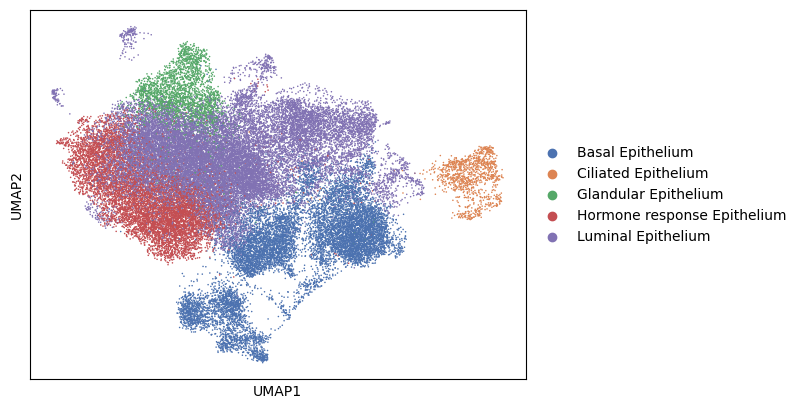

In [2]:
import scanpy as sc

cluster_to_group = {
    0: "Luminal Epithelium",
    1: "Hormone response Epithelium", #
    2: "Basal Epithelium",
    3: "Hormone response Epithelium", # Mesenchymal-Transitioned Epithelium
    4: "Ciliated Epithelium",
    5: "Luminal Epithelium",
    6: "Luminal Epithelium",
    7: "Basal Epithelium",
    8: "Luminal Epithelium",
    9: "Luminal Epithelium",
    10: "Luminal Epithelium",
    11: "Luminal Epithelium",
    12: "Luminal Epithelium",
    13: "Luminal Epithelium",
    14: "Glandular Epithelium",
    15: "Basal Epithelium",
    16: "Glandular Epithelium",
    17: "Luminal Epithelium",
    18: "Basal Epithelium"
}


Epithelial.obs["subtype"] = Epithelial.obs["leiden_res_1.00"].astype(int).map(cluster_to_group)
sc.pl.umap(
    Epithelial,
    color='subtype',
    title='',
    s = 5
)

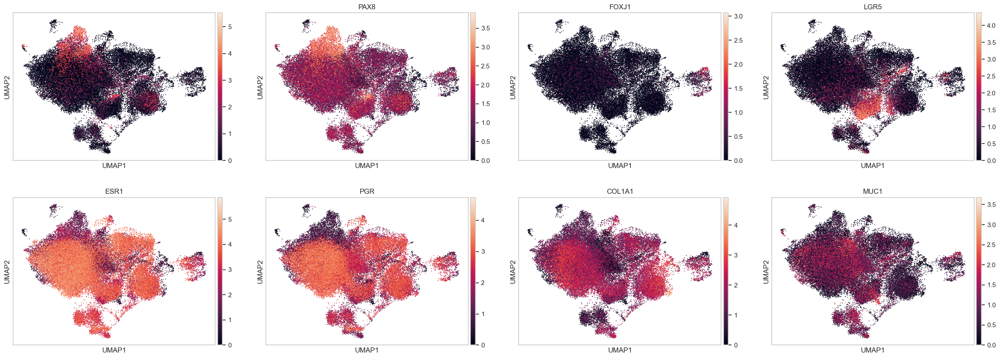

In [116]:
sc.pl.umap(
    Epithelial,
    color=["PAEP","PAX8","FOXJ1","LGR5","ESR1","PGR","COL1A1","MUC1"],
    title='',
    s = 7
)

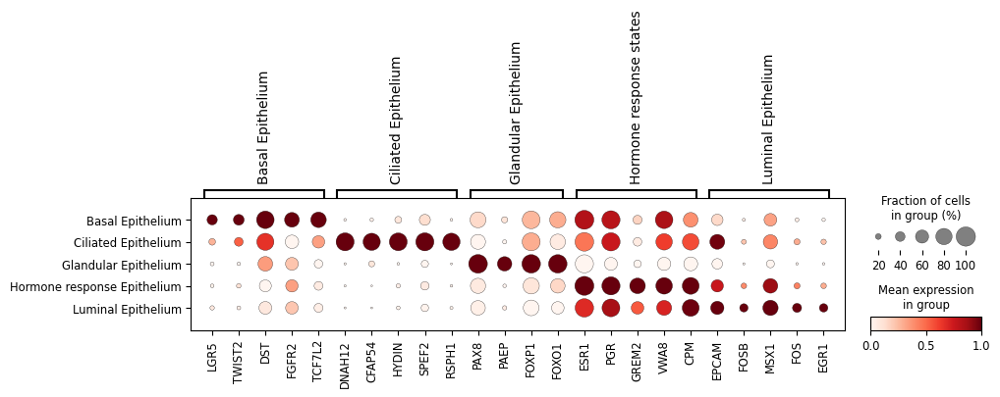

In [2]:
Epithelial_subtype_markers_human = {
    "Basal Epithelium": [
        "LGR5", "TWIST2", "DST", "FGFR2", "TCF7L2"
    ],
    "Ciliated Epithelium": [
        "DNAH12", "CFAP54", "HYDIN", "SPEF2", "RSPH1"
    ],
    "Glandular Epithelium": [
        "PAX8", "PAEP", "FOXP1", "FOXO1"
    ],
    "Hormone response states" : [
        'ESR1', 'PGR', 'GREM2', 'VWA8', 'CPM'],
    "Luminal Epithelium": [
        "EPCAM", "FOSB", "MSX1", "FOS", "EGR1"
    ]}
existing_subtype_markers = {
    subtype: [gene for gene in genes if gene in Epithelial.var_names]
    for subtype, genes in Epithelial_subtype_markers_human.items()}

sc.pl.dotplot(
    Epithelial,
    var_names=existing_subtype_markers,
    groupby="subtype",
    standard_scale="var",
    dendrogram=False)

In [72]:
import scanpy as sc
sc.tl.rank_genes_groups(Epithelial, groupby='subtype', method='t-test')  # 또는 'wilcoxon'
top_genes = {}
groups = Epithelial.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들
for group in groups:
    genes = Epithelial.uns['rank_genes_groups']['names'][group][:50]
    top_genes[group] = genes.tolist()


for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")

Cluster Basal Epithelium: ['ATXN1', 'DST', 'THSD4', 'SLC24A3', 'EFNA5', 'TCF7L2', 'NR2F2-AS1', 'MIR99AHG', 'MEIS1', 'ERBB4', 'AUTS2', 'NLGN4X', 'MAML2', 'RAI14', 'ITPR2', 'ZEB1', 'NRP1', 'PDZRN3', 'INPP4B', 'MBNL2', 'CTTNBP2', 'JMJD1C', 'PTPRM', 'RORA', 'STARD13', 'DIP2C', 'NLGN1', 'STK3', 'HPSE2', 'IGF2BP2', 'PBX1', 'WWTR1', 'FAM20A', 'EXT1', 'CHSY3', 'RORB', 'KCNMA1', 'TWIST2', 'CDH11', 'PSD3', 'CDK14', 'UST', 'PTPN13', 'SVIL', 'SSBP2', 'TPST1', 'RBMS3', 'TLE4', 'LDB2', 'FLRT2']
Cluster Ciliated Epithelium: ['ARMC3', 'LRRIQ1', 'DNAH12', 'DNAAF1', 'CFAP43', 'HYDIN', 'DNAH9', 'CDHR3', 'SPAG17', 'CFAP54', 'DNAH7', 'DNAH11', 'RSPH1', 'STK33', 'SPEF2', 'CFAP299', 'FHAD1', 'CFAP157', 'CEP126', 'TEKT1', 'WDR49', 'DNAH5', 'ZBBX', 'CCDC146', 'DNAH6', 'TMEM232', 'CCDC30', 'CFAP47', 'CFAP70', 'DTHD1', 'DCDC1', 'PPIL6', 'WDR78', 'SPATA17', 'WDR66', 'AGBL4', 'ADGB', 'RFX2', 'MOK', 'FANK1', 'LRRC23', 'EFHC1', 'VWA3A', 'CFAP46', 'CSPP1', 'DNAI1', 'DRC3', 'NEK10', 'SPAG16', 'CASC1']
Cluster Glandula

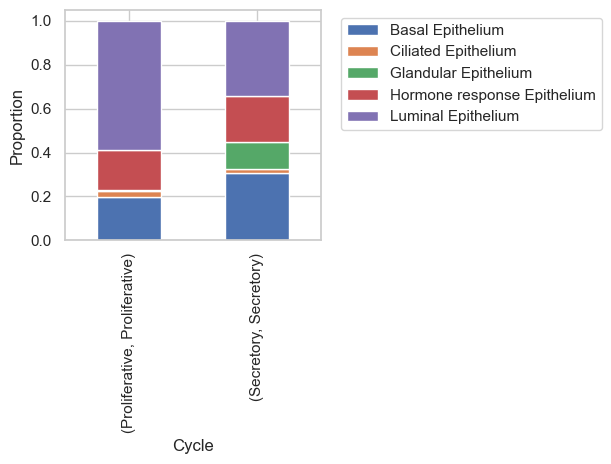

In [71]:
import pandas as pd
import matplotlib.pyplot as plt

df = Epithelial.obs[['Cycle','subtype']].copy()

prop = (
    df.groupby(['Cycle','subtype'])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .unstack(fill_value=0)
)

prop.plot(kind='bar', stacked=True)

plt.xlabel('Cycle')
plt.ylabel('Proportion')
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

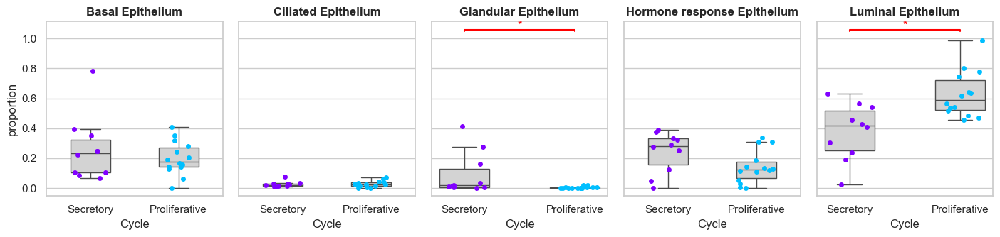

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings
import scanpy as sc

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

clin_palette = {
    'Secretory': '#8000ff',
    'Proliferative': '#00bfff',
}

Epithelial.obs['Each mouse'] = Epithelial.obs['Sample name']

adata_filtered = Epithelial[Epithelial.obs['Organism part'] != 'spleen'].copy()
adata_filtered = adata_filtered[
    adata_filtered.obs['Cycle'].isin(['Secretory', 'Proliferative'])
]

group_order = ['Secretory', 'Proliferative']

subtypes = sorted(adata_filtered.obs['subtype'].dropna().unique())

def normalize_mouse(df):
    total = df['count'].sum()
    df['proportion'] = df['count'] / total if total > 0 else 0
    return df

mouse_props_list = []

for (mouse, cycle), grp_df in adata_filtered.obs.groupby(['Each mouse', 'Cycle']):
    count_df = grp_df.groupby('subtype').size().reset_index(name='count')
    count_df['Each mouse'] = mouse
    count_df['Cycle'] = cycle
    mouse_props_list.append(normalize_mouse(count_df))

mouse_props = pd.concat(mouse_props_list, ignore_index=True)

n_rows, n_cols = 1, 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.85 * n_cols, 3.5 * n_rows), sharey=True)

axes = axes.flatten()

for i, subtype in enumerate(subtypes):
    ax = axes[i]

    data_sub = mouse_props[mouse_props['subtype'] == subtype]

    sns.boxplot(
        x='Cycle',
        y='proportion',
        data=data_sub,
        ax=ax,
        order=group_order,
        boxprops={'facecolor': 'lightgray'},
        fliersize=0,
        width=0.45
    )

    for cond in data_sub['Cycle'].unique():
        sub_df = data_sub[data_sub['Cycle'] == cond]
        sns.stripplot(
            x='Cycle',
            y='proportion',
            data=sub_df,
            color=clin_palette.get(cond, 'black'),
            jitter=0.2,
            size=5,
            ax=ax,
            order=group_order
        )

    v1 = data_sub[data_sub['Cycle'] == 'Secretory']['proportion']
    v2 = data_sub[data_sub['Cycle'] == 'Proliferative']['proportion']

    if len(v1) > 0 and len(v2) > 0:
        _, p = ranksums(v1, v2)

        if subtype == "Luminal Epithelium":
            sig = p < 0.05
        else:
            sig = p < 0.05

        if sig:
            x1, x2 = 0, 1
            y = 1.05
            ax.plot([x1, x1, x2, x2], [y, y + 0.01, y + 0.01, y], c='red')
            ax.text((x1 + x2) / 2, y + 0.015, "*", ha='center', color='red')

    ax.set_title(subtype, fontweight='bold', fontsize=12)

for j in range(len(subtypes), n_rows * n_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [52]:
import pandas as pd
import numpy as np
from scipy.stats import ranksums

luminal_clusters = [
    k for k, v in cluster_to_group.items()
    if v == "Luminal Epithelium"
]

results = []

for remove_cluster in luminal_clusters:

    keep_clusters = [c for c in luminal_clusters if c != remove_cluster]

    temp = Epithelial.copy()

    temp.obs["temp_subtype"] = np.where(
        temp.obs["leiden_res_1.00"].astype(int).isin(keep_clusters),
        "Luminal Epithelium",
        "Other"
    )

    adata_filtered = temp[
        (temp.obs["Organism part"] != "spleen") &
        (temp.obs["Cycle"].isin(["Secretory", "Proliferative"])) &
        (temp.obs["temp_subtype"] == "Luminal Epithelium")
    ].copy()

    mouse_props_list = []

    for (mouse, cycle), grp_df in adata_filtered.obs.groupby(['Individual', 'Cycle']):

        count = len(grp_df)

        total = len(
            temp.obs[
                (temp.obs['Individual'] == mouse) &
                (temp.obs['Cycle'] == cycle) &
                (temp.obs['Organism part'] != 'spleen')
            ]
        )

        prop = count / total if total > 0 else 0

        mouse_props_list.append({
            "mouse": mouse,
            "Cycle": cycle,
            "proportion": prop
        })

    mouse_props = pd.DataFrame(mouse_props_list)

    v1 = mouse_props[
        mouse_props["Cycle"] == "Secretory"
    ]["proportion"]

    v2 = mouse_props[
        mouse_props["Cycle"] == "Proliferative"
    ]["proportion"]

    if len(v1) > 0 and len(v2) > 0:

        stat, p = ranksums(v1, v2)

        results.append({
            "removed_cluster": remove_cluster,
            "p_value": p,
            "secretory_mean": v1.mean(),
            "proliferative_mean": v2.mean(),
            "n_clusters_remaining": len(keep_clusters)
        })

results_df = pd.DataFrame(results).sort_values("p_value")

print(results_df)

    removed_cluster   p_value  secretory_mean  proliferative_mean  \
2                 3  0.017235        0.397111            0.660057   
1                 1  0.039008        0.434872            0.708596   
6                 9  0.050201        0.510951            0.754912   
8                11  0.050201        0.466193            0.703132   
11               17  0.080716        0.518130            0.762372   
4                 6  0.080716        0.514341            0.743597   
3                 5  0.124822        0.480410            0.681119   
0                 0  0.124822        0.421217            0.668176   
10               13  0.124822        0.489682            0.727204   
5                 8  0.124822        0.513535            0.697719   
9                12  0.185789        0.480623            0.657303   
7                10  0.223494        0.474609            0.632347   

    n_clusters_remaining  
2                     11  
1                     11  
6                    

In [73]:
Epithelial.write("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad")

In [1]:
import scanpy as sc
Epithelial = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad")

In [245]:
import scanpy as sc

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = Epithelial.obs_names.intersection(adata_source.obs_names)

Epithelial = Epithelial[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata_source = adata_source[Epithelial.obs_names].copy()

Epithelial._X = adata_source.X.copy()
Epithelial._var = adata_source.var.copy()
Epithelial._n_vars = adata_source.n_vars

In [246]:
target_subtypes = ['Luminal Epithelium']
Epithelial = Epithelial[Epithelial.obs['subtype'].isin(target_subtypes)].copy()

In [35]:
import pandas as pd
import os

outdir = "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/DESeq2/"
os.makedirs(outdir, exist_ok=True)
counts = Epithelial.X
genes = Epithelial.var_names
for mc in Epithelial.obs["subtype"].unique():
    ad = Epithelial[Epithelial.obs["subtype"] == mc]
    
    mat = ad.X
    df = pd.DataFrame(
        mat.T.toarray() if hasattr(mat, "toarray") else mat.T,
        index=genes, columns=ad.obs_names)
    
    pb = df.groupby(ad.obs["Sample name"], axis=1).sum()
    pb.to_csv(f"{outdir}/pseudobulk_module_cluster_{mc}.csv")


os.makedirs(outdir, exist_ok=True)

df = (
    Epithelial.obs[["Sample name", "Cycle","Age group", "Disease","Age","Dataset","10x technology"]]
    .drop_duplicates()
    .sort_values("Sample name"))
df.to_csv(f"{outdir}/sample_id_age_group.csv", index=False)

/tmp/ipykernel_2504220/226256067.py:16: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  pb = df.groupby(ad.obs["Sample name"], axis=1).sum()
/tmp/ipykernel_2504220/226256067.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pb = df.groupby(ad.obs["Sample name"], axis=1).sum()


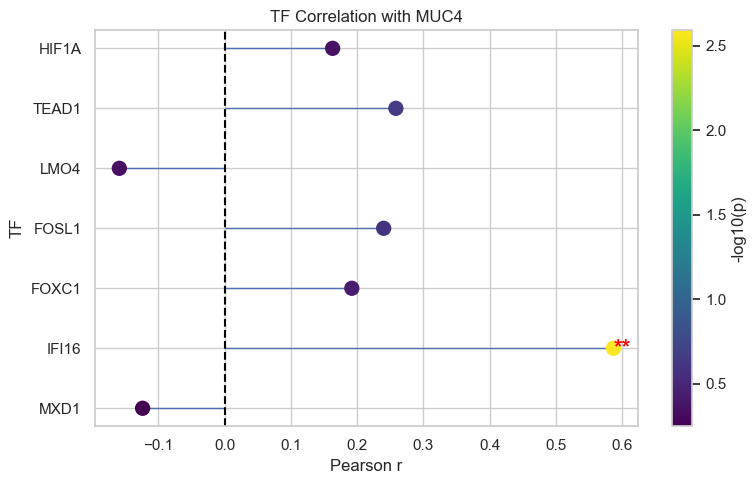

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

epi_path = "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/DESeq2/Luminal_bulk_rna_vsd_preprocess.csv"

exclude_samples = {}

epi = pd.read_csv(epi_path, index_col=0)
epi = epi[[s for s in epi.columns if s not in exclude_samples]]

target = "MUC4"
genes = ["MXD1", "IFI16", "FOXC1", "FOSL1", "LMO4", "TEAD1", "HIF1A"]

results = []

for g in genes:
    if g not in epi.index or target not in epi.index:
        continue
    x = epi.loc[g]
    y = epi.loc[target]
    df = pd.DataFrame({"x": x, "y": y}).fillna(0)
    r, p = pearsonr(df["x"], df["y"])
    results.append([g, r, p, -np.log10(p)])

res = pd.DataFrame(results, columns=["gene", "pearson_r", "p", "logp"])

def star(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

plt.figure(figsize=(8,5))

y_pos = np.arange(len(res))

for i in range(len(res)):
    plt.hlines(
        y=y_pos[i],
        xmin=0,
        xmax=res["pearson_r"][i],
        linewidth=1
    )

sc = plt.scatter(
    res["pearson_r"],
    y_pos,
    s=100,
    c=res["logp"],
    cmap="viridis",
    zorder=3
)

for i in range(len(res)):
    plt.text(
        res["pearson_r"][i],
        y_pos[i],
        star(res["p"][i]),
        va="center",
        ha="left",
        fontsize=16,
        color="red",
        fontweight="bold"
    )

plt.yticks(y_pos, res["gene"])
plt.axvline(0, linestyle='--', color='black')
plt.xlabel("Pearson r")
plt.ylabel("TF")
plt.title("TF Correlation with MUC4")
plt.colorbar(sc, label="-log10(p)")
plt.tight_layout()
plt.show()

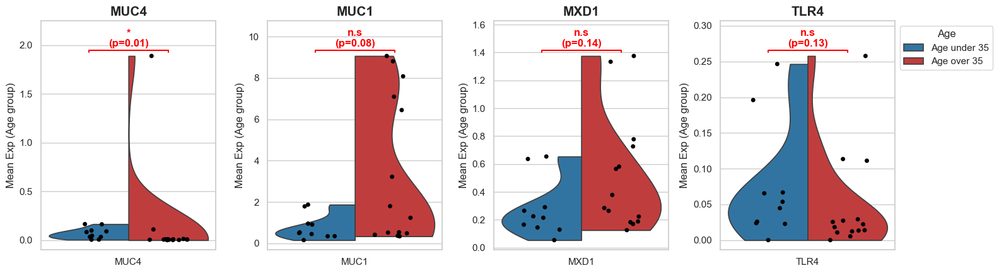

In [247]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import numpy as np
import scanpy as sc
import math

adata = Epithelial

genes = ["MUC4", "MUC1", "MXD1", "TLR4"]

target_col = "Age group"

group_order = ["Young", "Aged"]

custom_palette = {
    group_order[0]: '#1f77b4',
    group_order[1]: '#d62728'
}

legend_labels = {
    "Young": "Age under 35",
    "Aged": "Age over 35"
}

genes = [g for g in genes if g in adata.var_names]

plot_list = []

expr_df = adata.to_df()
obs_df = adata.obs

for gene in genes:

    df_gene = expr_df[gene]

    unique_samples = obs_df["Sample name"].unique()

    for sample in unique_samples:

        idx = obs_df.index[
            obs_df["Sample name"] == sample
        ]

        if len(idx) == 0:
            continue

        mean_exp = df_gene.loc[idx].mean()

        target_val = obs_df.loc[
            idx,
            target_col
        ].iloc[0]

        plot_list.append({
            "Gene": gene,
            "Sample": sample,
            target_col: target_val,
            "MeanExpression": mean_exp
        })

plot_df = pd.DataFrame(plot_list)

fig, axes = plt.subplots(
    1,
    len(genes),
    figsize=(4 * len(genes), 4.5)
)

if len(genes) == 1:
    axes = [axes]

for i, gene in enumerate(genes):

    ax = axes[i]

    sub_df = plot_df[
        plot_df["Gene"] == gene
    ].copy()

    sub_df[target_col] = pd.Categorical(
        sub_df[target_col],
        categories=group_order,
        ordered=True
    )

    sub_df = sub_df.sort_values(
        target_col
    ).reset_index(drop=True)

    sns.violinplot(
        data=sub_df,
        x=np.array([gene] * len(sub_df)),
        y="MeanExpression",
        hue=target_col,
        hue_order=group_order,
        palette=custom_palette,
        split=True,
        inner=None,
        ax=ax,
        cut=0
    )

    sns.stripplot(
        data=sub_df,
        x=np.array([gene] * len(sub_df)),
        y="MeanExpression",
        hue=target_col,
        hue_order=group_order,
        palette={
            group_order[0]: 'black',
            group_order[1]: 'black'
        },
        dodge=True,
        ax=ax,
        size=5,
        jitter=0.2
    )

    y_max = sub_df["MeanExpression"].max()
    y_min = sub_df["MeanExpression"].min()

    y_range = (
        y_max - y_min
        if y_max != y_min
        else y_max
    )

    g1 = sub_df[
        sub_df[target_col] == group_order[0]
    ]["MeanExpression"]

    g2 = sub_df[
        sub_df[target_col] == group_order[1]
    ]["MeanExpression"]

    stat, p = ranksums(g1, g2)

    p_trunc = math.floor(p * 100) / 100

    sig = (
        "***" if p < 0.001 else
        "**" if p < 0.01 else
        "*" if p < 0.05 else
        "n.s"
    )

    y_line = y_max + (y_range * 0.02)

    y_text = y_line + (y_range * 0.02)

    ax.plot(
        [-0.2, -0.2, 0.2, 0.2],
        [
            y_line,
            y_line + (y_range * 0.01),
            y_line + (y_range * 0.01),
            y_line
        ],
        lw=1.5,
        c='red'
    )

    ax.text(
        0,
        y_text,
        f"{sig}\n(p={p_trunc:.2f})",
        ha='center',
        va='bottom',
        fontsize=12,
        color='red',
        fontweight='bold'
    )

    ax.set_ylim(
        top=y_text + (y_range * 0.15)
    )

    ax.set_title(
        f"{gene}",
        fontsize=15,
        fontweight='bold'
    )

    ax.set_xlabel("")

    ax.set_ylabel(
        f"Mean Exp ({target_col})"
    )

    if i == len(genes) - 1:

        handles, labels = ax.get_legend_handles_labels()

        new_labels = [
            legend_labels.get(l, l)
            for l in labels[:2]
        ]

        ax.legend(
            handles[:2],
            new_labels,
            title="Age",
            loc='upper left',
            bbox_to_anchor=(1, 1)
        )

    else:

        if ax.get_legend():
            ax.get_legend().remove()

plt.tight_layout()

plt.show()

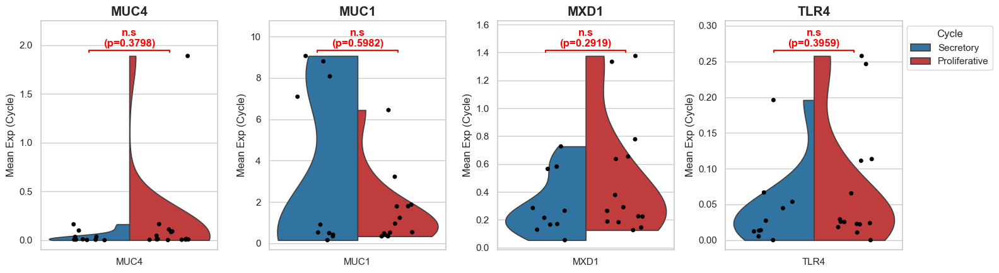

In [248]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import numpy as np
import scanpy as sc

adata = Epithelial
genes = ["MUC4", "MUC1", "MXD1", "TLR4"]
target_col = "Cycle"
group_order = ["Secretory", "Proliferative"]
custom_palette = {group_order[0]: '#1f77b4', group_order[1]: '#d62728'}

genes = [g for g in genes if g in adata.var_names]
plot_list = []
expr_df = adata.to_df()
obs_df = adata.obs

for gene in genes:
    df_gene = expr_df[gene]
    unique_samples = obs_df["Sample name"].unique()
    
    for sample in unique_samples:
        idx = obs_df.index[obs_df["Sample name"] == sample]
        if len(idx) == 0: continue
            
        mean_exp = df_gene.loc[idx].mean()
        target_val = obs_df.loc[idx, target_col].iloc[0]
        
        plot_list.append({
            "Gene": gene,
            "Sample": sample,
            target_col: target_val,
            "MeanExpression": mean_exp
        })

plot_df = pd.DataFrame(plot_list)

fig, axes = plt.subplots(1, len(genes), figsize=(4 * len(genes), 4.5))
if len(genes) == 1: axes = [axes]

for i, gene in enumerate(genes):
    ax = axes[i]
    
    sub_df = plot_df[plot_df["Gene"] == gene].copy()
    sub_df[target_col] = pd.Categorical(sub_df[target_col], categories=group_order, ordered=True)
    sub_df = sub_df.sort_values(target_col).reset_index(drop=True)

    sns.violinplot(
        data=sub_df, 
        x=np.array([gene] * len(sub_df)), 
        y="MeanExpression", 
        hue=target_col, 
        hue_order=group_order,
        palette=custom_palette, 
        split=True,
        inner=None,
        ax=ax,
        cut=0
    )

    sns.stripplot(
        data=sub_df, 
        x=np.array([gene] * len(sub_df)), 
        y="MeanExpression", 
        hue=target_col, 
        hue_order=group_order,
        palette={group_order[0]: 'black', group_order[1]: 'black'},
        dodge=True,
        ax=ax, 
        size=5,
        jitter=0.2
    )

    y_max = sub_df["MeanExpression"].max()
    y_min = sub_df["MeanExpression"].min()
    y_range = y_max - y_min if y_max != y_min else y_max

    g1 = sub_df[sub_df[target_col] == group_order[0]]["MeanExpression"]
    g2 = sub_df[sub_df[target_col] == group_order[1]]["MeanExpression"]
    stat, p = ranksums(g1, g2)
    
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s"
    
    y_line = y_max + (y_range * 0.02)
    y_text = y_line + (y_range * 0.02)
    
    ax.plot([-0.2, -0.2, 0.2, 0.2], [y_line, y_line + (y_range * 0.01), y_line + (y_range * 0.01), y_line], lw=1.5, c='red')
    ax.text(0, y_text, f"{sig}\n(p={p:.4f})", ha='center', va='bottom', fontsize=12, color='red', fontweight='bold')

    # y축 상단 10% 여유 공간 추가
    ax.set_ylim(top=y_text + (y_range * 0.15))

    ax.set_title(f"{gene}", fontsize=15, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel(f"Mean Exp ({target_col})")
    
    if i == len(genes) - 1:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[:2], labels[:2], title=target_col, loc='upper left', bbox_to_anchor=(1, 1))
    else:
        if ax.get_legend(): ax.get_legend().remove()

plt.tight_layout()
plt.show()

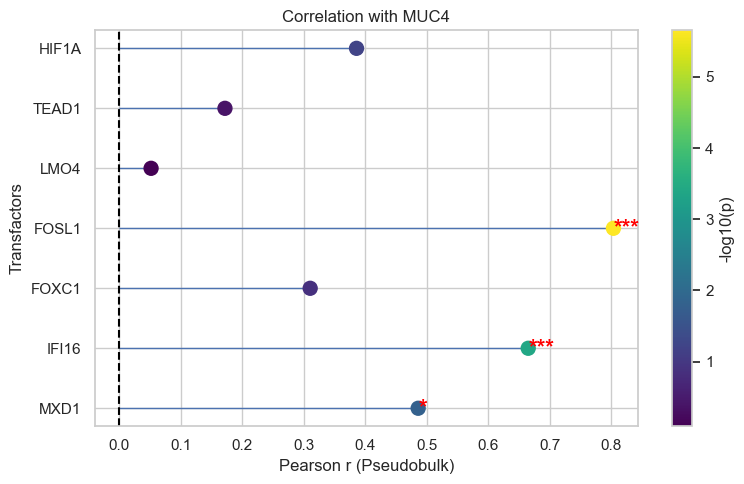

In [249]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

adata = Epithelial

target = "MUC4"
genes = ["MXD1", "IFI16", "FOXC1", "FOSL1", "LMO4", "TEAD1", "HIF1A"]

all_genes = [target] + genes
all_genes = [g for g in all_genes if g in adata.var_names]

expr = pd.DataFrame(
    adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X,
    index=adata.obs_names,
    columns=adata.var_names
)

expr = expr[all_genes]
expr["Sample"] = adata.obs["Sample name"].values

pseudo = expr.groupby("Sample").mean()

pseudo = np.log1p(pseudo)

results = []

for g in genes:
    if g not in pseudo.columns or target not in pseudo.columns:
        continue

    df = pseudo[[g, target]].dropna()

    if len(df) < 3:
        continue

    r, p = pearsonr(df[g], df[target])

    results.append([g, r, p, -np.log10(p)])

res = pd.DataFrame(
    results,
    columns=["gene", "pearson_r", "p", "logp"]
)

def star(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

plt.figure(figsize=(8,5))

y_pos = np.arange(len(res))

for i in range(len(res)):
    plt.hlines(
        y=y_pos[i],
        xmin=0,
        xmax=res["pearson_r"][i],
        linewidth=1
    )

sc = plt.scatter(
    res["pearson_r"],
    y_pos,
    s=100,
    c=res["logp"],
    cmap="viridis",
    zorder=3
)

for i in range(len(res)):
    plt.text(
        res["pearson_r"][i],
        y_pos[i],
        star(res["p"][i]),
        va="center",
        ha="left",
        fontsize=16,
        color="red",
        fontweight="bold"
    )

plt.yticks(y_pos, res["gene"])

plt.axvline(
    0,
    linestyle='--',
    color='black'
)

plt.xlabel("Pearson r (Pseudobulk)")
plt.ylabel("Transfactors")

plt.title(f"Correlation with {target}")

plt.colorbar(
    sc,
    label="-log10(p)"
)

plt.tight_layout()
plt.show()

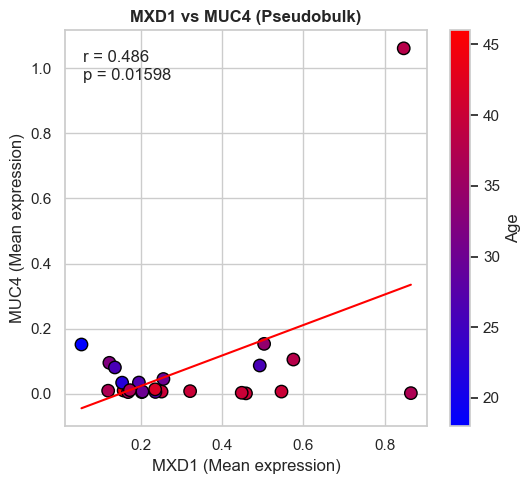

In [250]:
import scipy.stats as stats
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

g1 = "MXD1"
g2 = "MUC4"

df1 = plot_df[
    plot_df["Gene"] == g1
][["Sample", "MeanExpression"]].rename(
    columns={"MeanExpression": g1}
)

df2 = plot_df[
    plot_df["Gene"] == g2
][["Sample", "MeanExpression"]].rename(
    columns={"MeanExpression": g2}
)

age_df = (
    Epithelial.obs[["Sample name", "Age"]]
    .drop_duplicates()
    .rename(columns={"Sample name": "Sample"})
)

merged = pd.merge(df1, df2, on="Sample")
merged = pd.merge(merged, age_df, on="Sample")

merged[g1] = np.log1p(merged[g1])
merged[g2] = np.log1p(merged[g2])

r, p = stats.pearsonr(
    merged[g1],
    merged[g2]
)

cmap = LinearSegmentedColormap.from_list(
    "blue_red",
    ["blue", "red"]
)

plt.figure(figsize=(5.5, 5))

sns.regplot(
    data=merged,
    x=g1,
    y=g2,
    scatter=False,
    ci=None,
    line_kws={
        "color": "red",
        "linewidth": 1.5
    }
)

sc = plt.scatter(
    merged[g1],
    merged[g2],
    c=merged["Age"],
    cmap=cmap,
    s=80,
    edgecolor="black"
)

plt.title(
    f"{g1} vs {g2} (Pseudobulk)",
    fontweight="bold"
)

plt.xlabel(f"{g1} (Mean expression)")
plt.ylabel(f"{g2} (Mean expression)")

plt.text(
    0.05,
    0.95,
    f"r = {r:.3f}\np = {p:.4g}",
    transform=plt.gca().transAxes,
    verticalalignment='top'
)

cbar = plt.colorbar(sc)
cbar.set_label("Age")

plt.tight_layout()
plt.show()

# Lymphoid subtypeing

In [1]:
import scanpy as sc
adata = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/After_Clustering.h5ad")

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = adata.obs_names.intersection(adata_source.obs_names)

adata = adata[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata._X = adata_source.X.copy()
adata._var = adata_source.var.copy()
adata._n_vars = adata_source.n_vars

/home/Data_Drive_8TB/kykim/.conda/envs/kykim/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:336: RuntimeWarning: invalid value encountered in log
  dispersion = np.log(dispersion)
/home/Data_Drive_8TB/kykim/.conda/envs/kykim/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:494: UserWarning: `n_top_genes` > number of normalized dispersions, returning all genes with normalized dispersions.
  func(


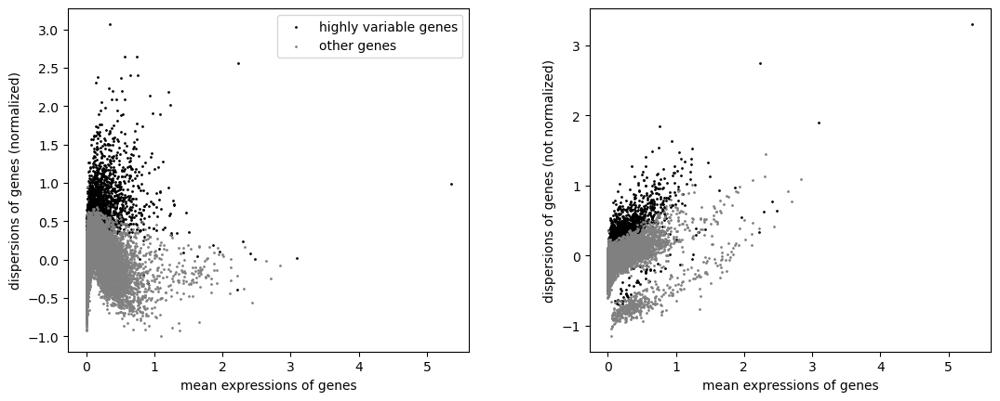

In [2]:
Epithelial = adata[adata.obs['celltype_grouped'] == 'Immune - Lymphoid'].copy()
Epithelial.layers["counts"] = Epithelial.X.copy()
sc.pp.normalize_total(Epithelial)
sc.pp.log1p(Epithelial)

sc.pp.highly_variable_genes(Epithelial, n_top_genes=2000, batch_key="Sample name")
sc.pl.highly_variable_genes(Epithelial)
Epithelial = Epithelial[:, Epithelial.var['highly_variable']].copy()

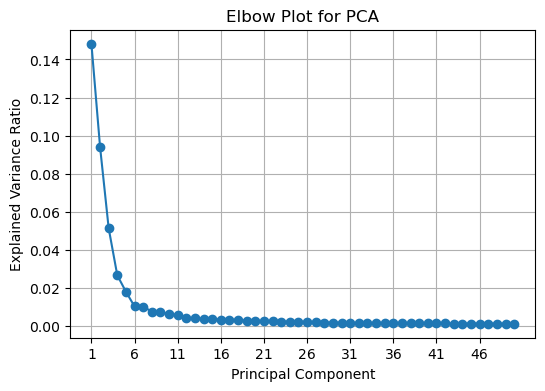

In [3]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

sc.tl.pca(Epithelial)
explained_variance_ratio = Epithelial.uns["pca"]["variance_ratio"]

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker="o", linestyle="-")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Elbow Plot for PCA")
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, step=5))
plt.grid()
plt.show()

In [4]:
sc.tl.pca(Epithelial, n_comps=31)

/home/Data_Drive_8TB/kykim/.conda/envs/kykim/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


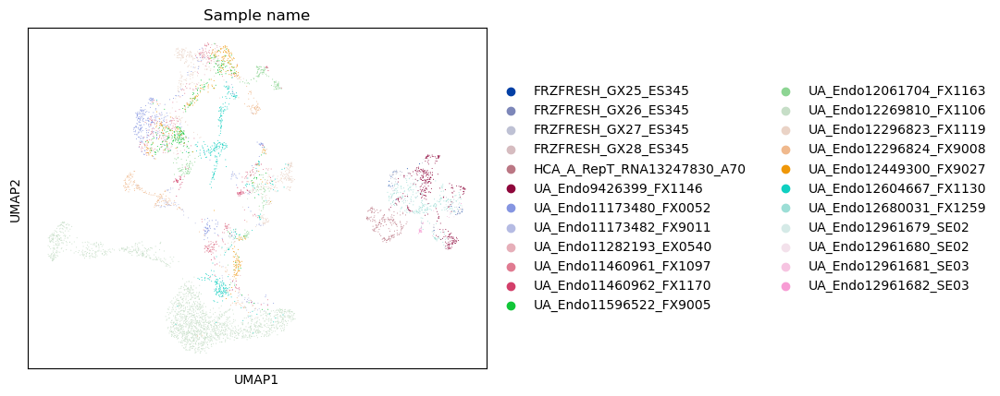

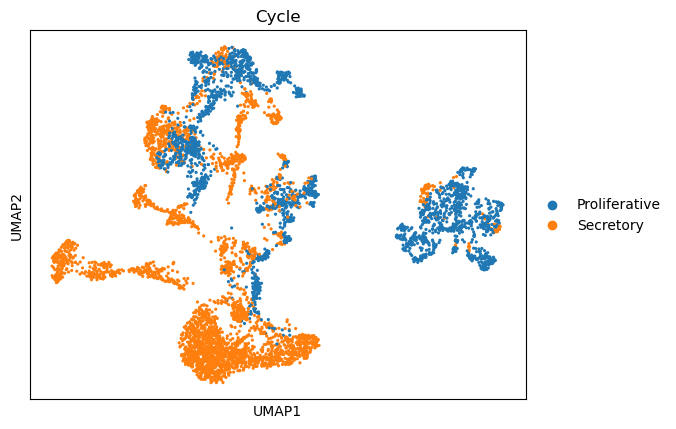

In [5]:
sc.pp.neighbors(Epithelial)
sc.tl.umap(Epithelial)
sc.pl.umap(
    Epithelial,
    color="Sample name",
    # Setting a smaller point size to get prevent overlap
    size=2)
sc.pl.umap(Epithelial, color=["Cycle"])

In [6]:
Epithelial.obs["batch_combined"] = (
    Epithelial.obs["Sample name"].astype(str) + "_" +
    Epithelial.obs["10x technology"].astype(str))

In [7]:
import scvi 
import matplotlib.pyplot as plt

#scvi.model.SCVI.setup_anndata(Epithelial, layer="counts", batch_key="Sample name")
scvi.model.SCVI.setup_anndata(Epithelial, layer="counts", batch_key="batch_combined")
vae = scvi.model.SCVI(Epithelial, n_layers=2, n_latent=30, gene_likelihood="nb")

vae.train(max_epochs=400, early_stopping=False, early_stopping_patience=5)

train_loss = vae.history["elbo_train"]
val_loss = vae.history["elbo_validation"]
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss (ELBO)")
plt.plot(val_loss, label="Validation Loss (ELBO)")
plt.xlabel("Epochs")
plt.ylabel("ELBO Loss")
plt.title("SCVI Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

/home/Data_Drive_8TB/kykim/.conda/envs/kykim/lib/python3.10/site-packages/scvi/data/fields/_dataframe_field.py:187: UserWarning: Category 1 in adata.obs['_scvi_batch'] has fewer than 3 cells. Models may not train properly.
  categorical_mapping = _make_column_categorical(
Trainer will use only 1 of 6 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=6)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX A5000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmu

Epoch 400/400: 100%|██████████| 400/400 [02:04<00:00,  3.32it/s, v_num=1, train_loss_step=1.31e+3, train_loss_epoch=1.34e+3]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [02:04<00:00,  3.21it/s, v_num=1, train_loss_step=1.31e+3, train_loss_epoch=1.34e+3]


KeyError: 'elbo_validation'

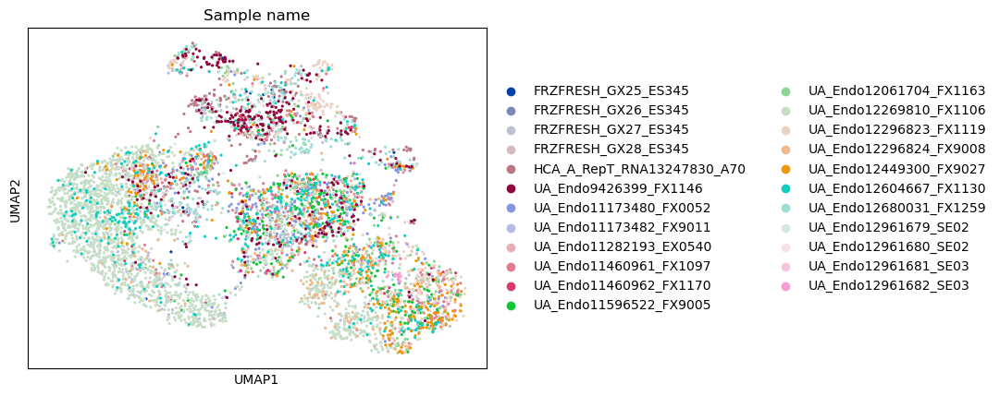

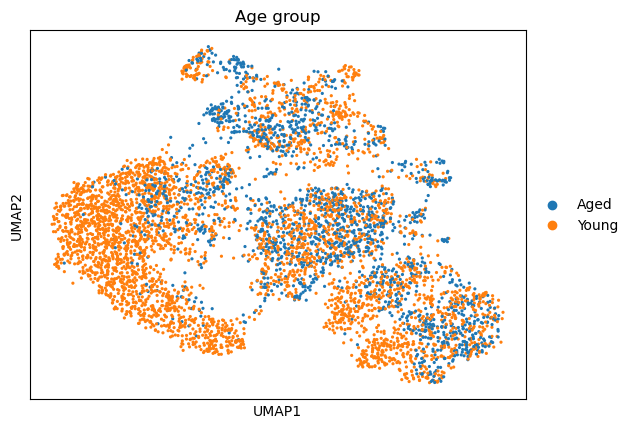

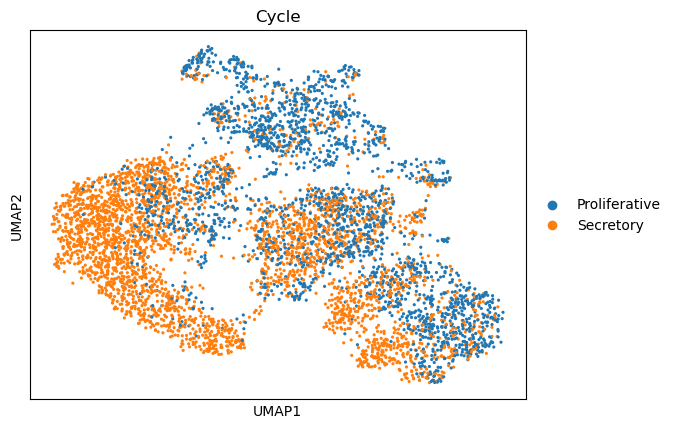

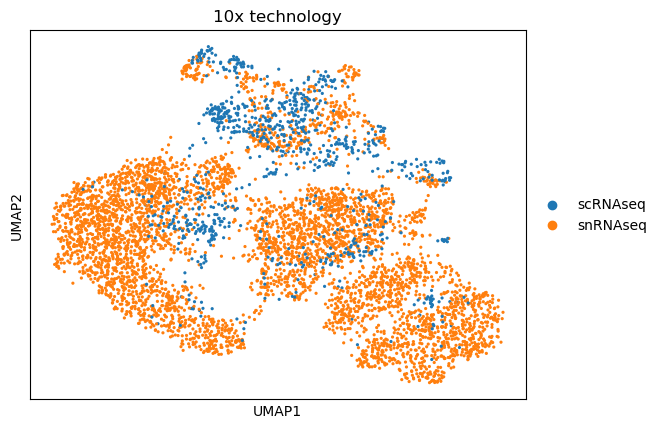

In [8]:
Epithelial.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(Epithelial, use_rep = 'X_scVI')
sc.tl.umap(Epithelial)

sc.pl.umap(Epithelial, color=["Sample name"])
sc.pl.umap(Epithelial, color=["Age group"])
sc.pl.umap(Epithelial, color=["Cycle"])
sc.pl.umap(Epithelial, color=['10x technology'])

In [9]:
Epithelial.__dict__['_varm'].clear()
Epithelial.__dict__['_layers'].clear()

In [10]:
import scanpy as sc

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = Epithelial.obs_names.intersection(adata_source.obs_names)

Epithelial = Epithelial[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata_source = adata_source[Epithelial.obs_names].copy()

Epithelial._X = adata_source.X.copy()
Epithelial._var = adata_source.var.copy()
Epithelial._n_vars = adata_source.n_vars

In [11]:
sc.pp.normalize_total(Epithelial)
sc.pp.log1p(Epithelial)

for res in [0.75,1.00,1.50]:
    sc.tl.leiden(
        Epithelial, key_added=f"leiden_res_{res:4.2f}", resolution=res, 
        flavor="igraph"
    )

Cluster 0: ['TPT1', 'JUND', 'HLA-B', 'BTG1', 'FOS', 'RPL26', 'CCL5', 'MT-CO2', 'EIF1', 'MT-ATP6', 'RPS8', 'RPL30', 'RPS23', 'MT-CYB', 'RPLP1', 'CD69', 'MT-CO3', 'RPS27A', 'B2M', 'RPS7', 'MT-ND3', 'RPS19', 'HLA-A', 'MT-CO1', 'UBC', 'RPLP2', 'PTMA', 'RPS4X', 'TMSB4X', 'RPL35A']
Cluster 1: ['IL7R', 'MT-CO1', 'B2M', 'RPL13', 'RPLP1', 'RPS18', 'TXNIP', 'MT-CO3', 'RPS2', 'RPS15', 'RPL34', 'BCL11B', 'RPS28', 'EEF1A1', 'RPL41', 'RPL10', 'RPS4X', 'RPL18', 'VIM', 'RPS27', 'LTB', 'RPS14', 'RPS23', 'RPL26', 'MT-CYB', 'RPS8', 'RPS12', 'RPL28', 'MT-CO2', 'BTG1']
Cluster 2: ['RIPOR2', 'PTPRC', 'MT-CO1', 'LINC00861', 'PLAC8', 'TXNIP', 'ARL4C', 'NKG7', 'SYNE1', 'B2M', 'GNG2', 'KLF2', 'MT-CO3', 'MYO1F', 'ZEB2', 'CYBA', 'PFN1', 'ACTB', 'PRF1', 'TGFBR3', 'CCND3', 'CLEC2D', 'RPL28', 'HLA-E', 'RPS12', 'EFHD2', 'RPS8', 'RAP1GAP2', 'BIN2', 'CX3CR1']
Cluster 3: ['MT-CO1', 'CD2', 'B2M', 'MT-CO3', 'MT-CO2', 'MT-CYB', 'CCL5', 'PTPRC', 'MT-ATP6', 'HLA-B', 'EEF1A1', 'MT-ND5', 'MT-ND4', 'HLA-A', 'TMSB4X', 'RPL13', '

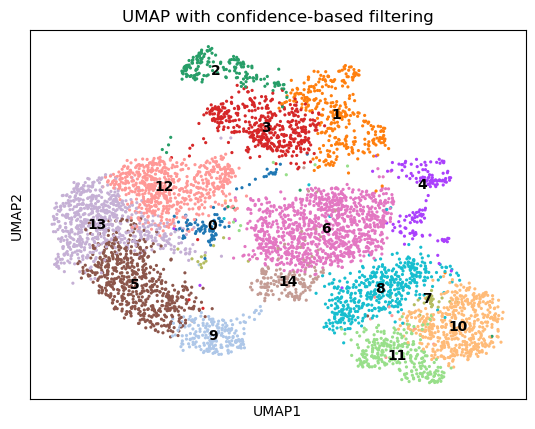

In [12]:
import scanpy as sc
sc.tl.rank_genes_groups(Epithelial, groupby='leiden_res_1.00', method='t-test')  # 또는 'wilcoxon'
top_genes = {}
groups = Epithelial.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들
for group in groups:
    genes = Epithelial.uns['rank_genes_groups']['names'][group][:30]
    top_genes[group] = genes.tolist()


for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")
sc.pl.umap(
    Epithelial,
    color='leiden_res_1.00',
    title='UMAP with confidence-based filtering',
    legend_loc='on data')

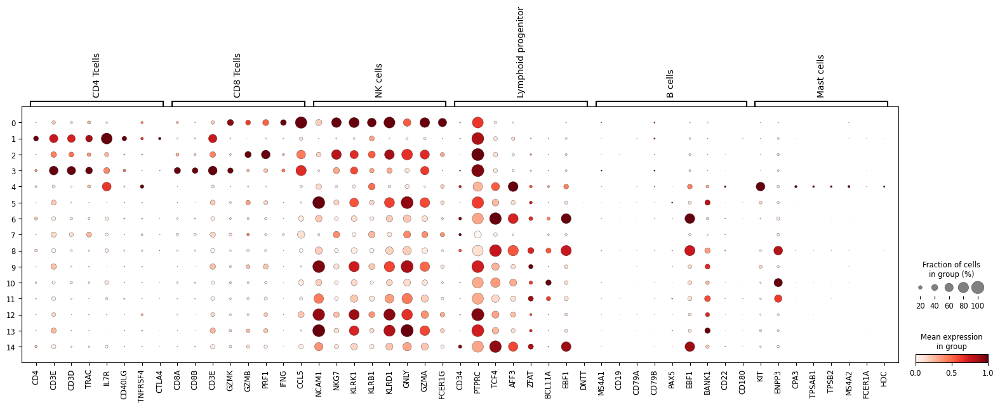

In [14]:
Epithelial_subtype_markers_human={
"CD4 Tcells":["CD4","CD3E","CD3D","TRAC","IL7R","CD40LG","TNFRSF4","CTLA4"],
"CD8 Tcells":["CD8A","CD8B","CD3E","GZMK","GZMB","PRF1","IFNG","CCL5"],
"NK cells":["NCAM1","NKG7","KLRK1","KLRB1","KLRD1","GNLY","GZMA","FCER1G"],
"Lymphoid progenitor":["CD34","PTPRC","TCF4","AFF3","ZFAT","BCL11A","EBF1","DNTT"],
"B cells":["MS4A1","CD19","CD79A","CD79B","PAX5","EBF1","BANK1","CD22","CD180"],
"Mast cells":["KIT","ENPP3","CPA3","TPSAB1","TPSB2","MS4A2","FCER1A","HDC"]
}

existing_subtype_markers = {
    subtype: [gene for gene in genes if gene in Epithelial.var_names]
    for subtype, genes in Epithelial_subtype_markers_human.items()}

sc.pl.dotplot(
    Epithelial,
    var_names=existing_subtype_markers,
    groupby="leiden_res_1.00",
    standard_scale="var",
    dendrogram=False)

Cluster Atypical lymphoid: ['PARD3', 'FAM155A', 'PBX1', 'SDK1', 'DOCK1', 'ESR1', 'TEAD1', 'SOX5', 'TTC28', 'AGAP1', 'ZNF516', 'MEIS1', 'PALLD', 'FARP1', 'DANT2', 'RBPMS', 'PTK2', 'PLEKHA5', 'RBFOX2', 'PRICKLE2', 'ROR2', 'IGF1R', 'ZNF704', 'AOPEP', 'MAGI1', 'PGR', 'FBXL7', 'UGGT2', 'MITF', 'KCNQ1OT1']
Cluster CD4 T cells: ['IL7R', 'MT-CO1', 'B2M', 'RPL13', 'RPLP1', 'RPS18', 'TXNIP', 'MT-CO3', 'RPS2', 'RPS15', 'RPL34', 'BCL11B', 'RPS28', 'EEF1A1', 'RPL41', 'RPL10', 'RPS4X', 'RPL18', 'VIM', 'RPS27', 'LTB', 'RPS14', 'RPS23', 'RPL26', 'MT-CYB', 'RPS8', 'RPS12', 'RPL28', 'MT-CO2', 'BTG1']
Cluster CD8 T cells: ['MT-CO1', 'B2M', 'PTPRC', 'MT-CO3', 'MT-CO2', 'MT-CYB', 'CCL5', 'HLA-B', 'MT-ATP6', 'EEF1A1', 'CD2', 'HLA-A', 'ACTB', 'RPL28', 'TMSB4X', 'MT-ND5', 'RPLP1', 'RPL13', 'MT-ND4', 'RPS12', 'HLA-E', 'RPL39', 'RPS24', 'HLA-C', 'RPS14', 'RPS27A', 'RPL11', 'TPT1', 'RPL41', 'RPL32']
Cluster ILC cells: ['KIT', 'AHR', 'AFF3', 'PCDH9', 'TOX2', 'IL7R', 'IL18R1', 'LST1', 'MT-CO1', 'IL23R', 'MT-ND2', 

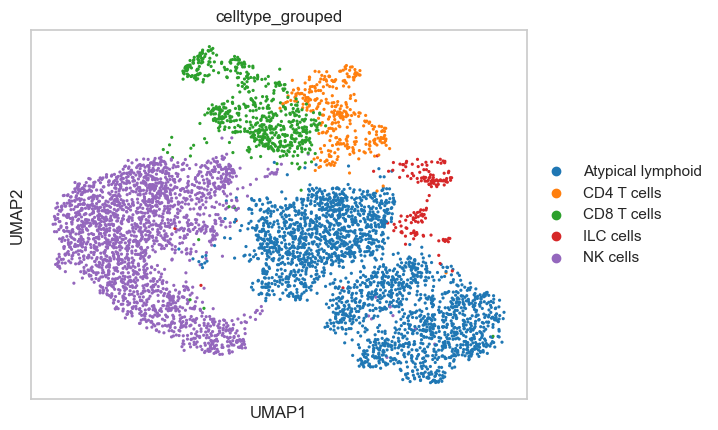

In [217]:
cluster_to_group = {
    0: "NK cells", #
    1: "CD4 T cells",
    2: "CD8 T cells", #
    3: "CD8 T cells",
    4: "ILC cells",
    5: "NK cells",
    6: "Atypical lymphoid",
    7: "Atypical lymphoid",
    8: "Atypical lymphoid",
    9: "NK cells",
    10: "Atypical lymphoid",
    11: "Atypical lymphoid",
    12: "NK cells",
    13: "NK cells",
    14: "Atypical lymphoid"
}

Epithelial.obs["celltype_grouped"] = Epithelial.obs["leiden_res_1.00"].astype(int).map(cluster_to_group)

sc.tl.rank_genes_groups(Epithelial, groupby='celltype_grouped', method='t-test')  # 또는 'wilcoxon'

top_genes = {}

groups = Epithelial.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들

for group in groups:
    genes = Epithelial.uns['rank_genes_groups']['names'][group][:30]
    top_genes[group] = genes.tolist()

for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")
    
sc.pl.umap(
    Epithelial,
    color='celltype_grouped')

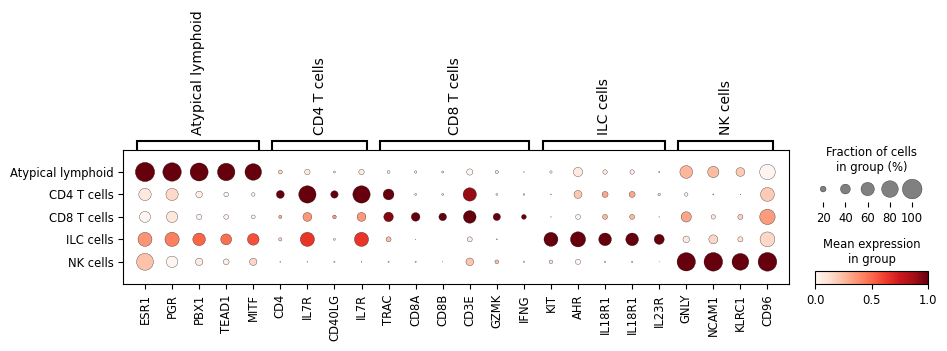

In [3]:
group_markers = {
"Atypical lymphoid": ["ESR1", "PGR", "PBX1", "TEAD1", "MITF"],
"CD4 T cells": ["CD4","IL7R","CD40LG","IL7R"],
"CD8 T cells": ["TRAC","CD8A","CD8B","CD3E","GZMK","IFNG"],
"ILC cells": ["KIT", "AHR", "IL18R1", "IL18R1", "IL23R"],
"NK cells": ["GNLY", "NCAM1", "KLRC1", "NKG", "CD96"]
}

existing_genes = {
cat: [gene for gene in genes if gene in Epithelial.var_names]
for cat, genes in group_markers.items()
}

existing_genes = {
cat: genes
for cat, genes in existing_genes.items()
if genes
}

sc.pl.dotplot(
Epithelial,
var_names = existing_genes,
groupby = "celltype_grouped",
standard_scale = "var"
)

In [218]:
Epithelial.write("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad")

In [19]:
import scanpy as sc

Epithelial = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad")

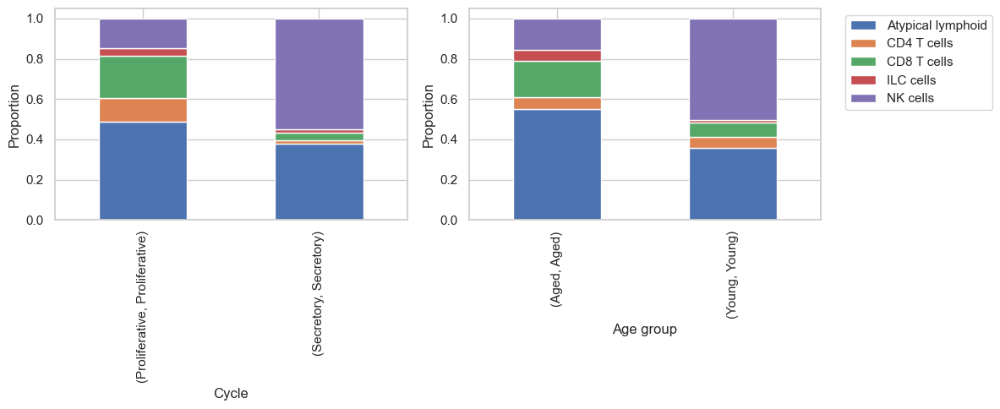

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df1 = Epithelial.obs[['Cycle','celltype_grouped']].copy()
prop1 = (
    df1.groupby(['Cycle','celltype_grouped'])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .unstack(fill_value=0)
)
prop1.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('Cycle')
axes[0].set_ylabel('Proportion')

df2 = Epithelial.obs[['Age group','celltype_grouped']].copy()
prop2 = (
    df2.groupby(['Age group','celltype_grouped'])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .unstack(fill_value=0)
)
prop2.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('Age group')
axes[1].set_ylabel('Proportion')

axes[1].legend(bbox_to_anchor=(1.05,1), loc='upper left')
axes[0].legend().remove()

plt.tight_layout()
plt.show()

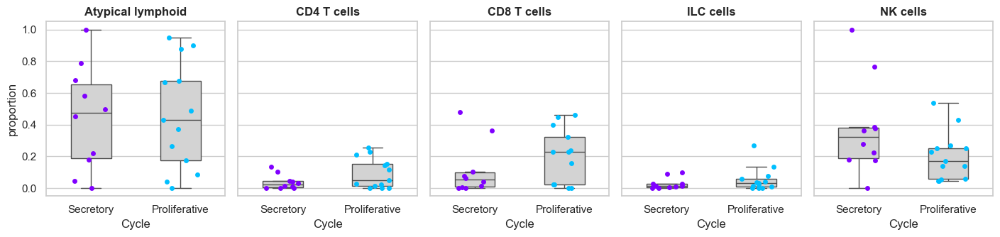

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings
import scanpy as sc

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

clin_palette = {
    'Secretory': '#8000ff',
    'Proliferative': '#00bfff',
}

Epithelial.obs['Each mouse'] = Epithelial.obs['Sample name']

adata_filtered = Epithelial[Epithelial.obs['Organism part'] != 'spleen'].copy()
adata_filtered = adata_filtered[
    adata_filtered.obs['Cycle'].isin(['Secretory', 'Proliferative'])
]

group_order = ['Secretory', 'Proliferative']

celltype_grouped = sorted(adata_filtered.obs['celltype_grouped'].dropna().unique())

def normalize_mouse(df):
    total = df['count'].sum()
    df['proportion'] = df['count'] / total if total > 0 else 0
    return df

mouse_props_list = []

for (mouse, cycle), grp_df in adata_filtered.obs.groupby(['Each mouse', 'Cycle']):
    count_df = grp_df.groupby('celltype_grouped').size().reset_index(name='count')
    count_df['Each mouse'] = mouse
    count_df['Cycle'] = cycle
    mouse_props_list.append(normalize_mouse(count_df))

mouse_props = pd.concat(mouse_props_list, ignore_index=True)

n_rows, n_cols = 1, 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.85 * n_cols, 3.5 * n_rows), sharey=True)

axes = axes.flatten()

for i, celltype_grouped in enumerate(celltype_grouped):
    ax = axes[i]

    data_sub = mouse_props[mouse_props['celltype_grouped'] == celltype_grouped]

    sns.boxplot(
        x='Cycle',
        y='proportion',
        data=data_sub,
        ax=ax,
        order=group_order,
        boxprops={'facecolor': 'lightgray'},
        fliersize=0,
        width=0.45
    )

    for cond in data_sub['Cycle'].unique():
        sub_df = data_sub[data_sub['Cycle'] == cond]
        sns.stripplot(
            x='Cycle',
            y='proportion',
            data=sub_df,
            color=clin_palette.get(cond, 'black'),
            jitter=0.2,
            size=5,
            ax=ax,
            order=group_order
        )

    v1 = data_sub[data_sub['Cycle'] == 'Secretory']['proportion']
    v2 = data_sub[data_sub['Cycle'] == 'Proliferative']['proportion']

    if len(v1) > 0 and len(v2) > 0:
        _, p = ranksums(v1, v2)

        if celltype_grouped == "Luminal Epithelium":
            sig = p < 0.05
        else:
            sig = p < 0.05

        if sig:
            x1, x2 = 0, 1
            y = 1.05
            ax.plot([x1, x1, x2, x2], [y, y + 0.01, y + 0.01, y], c='red')
            ax.text((x1 + x2) / 2, y + 0.015, "*", ha='center', color='red')

    ax.set_title(celltype_grouped, fontweight='bold', fontsize=12)

for j in range(len(celltype_grouped), n_rows * n_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

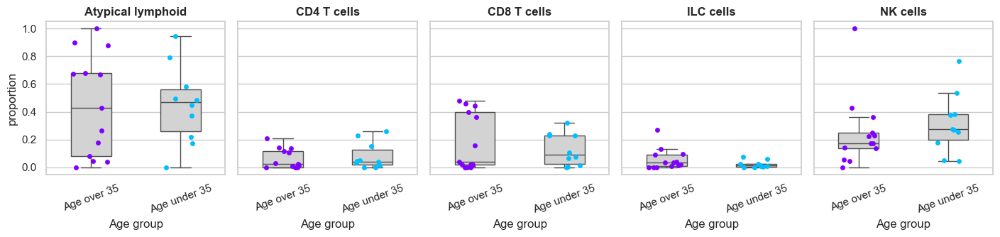

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings
import scanpy as sc

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

clin_palette = {
    'Aged': '#8000ff',
    'Young': '#00bfff',
}

label_map = {
    'Aged': 'Age over 35',
    'Young': 'Age under 35'
}

Epithelial.obs['Each mouse'] = Epithelial.obs['Sample name']

adata_filtered = Epithelial[
    Epithelial.obs['Organism part'] != 'spleen'
].copy()

adata_filtered = adata_filtered[
    adata_filtered.obs['Age group'].isin(['Aged', 'Young'])
]

group_order = ['Aged', 'Young']

celltype_groups = sorted(
    adata_filtered.obs['celltype_grouped'].dropna().unique()
)

def normalize_mouse(df):
    total = df['count'].sum()
    df['proportion'] = df['count'] / total if total > 0 else 0
    return df

mouse_props_list = []

for (mouse, age_group), grp_df in adata_filtered.obs.groupby(
    ['Each mouse', 'Age group']
):

    count_df = grp_df.groupby(
        'celltype_grouped'
    ).size().reset_index(name='count')

    count_df['Each mouse'] = mouse
    count_df['Age group'] = age_group

    mouse_props_list.append(
        normalize_mouse(count_df)
    )

mouse_props = pd.concat(
    mouse_props_list,
    ignore_index=True
)

n_rows, n_cols = 1, 5

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(2.85 * n_cols, 3.5 * n_rows),
    sharey=True
)

axes = axes.flatten()

for i, ct in enumerate(celltype_groups):

    ax = axes[i]

    data_sub = mouse_props[
        mouse_props['celltype_grouped'] == ct
    ]

    sns.boxplot(
        x='Age group',
        y='proportion',
        data=data_sub,
        ax=ax,
        order=group_order,
        boxprops={'facecolor': 'lightgray'},
        fliersize=0,
        width=0.45
    )

    for cond in data_sub['Age group'].unique():

        sub_df = data_sub[
            data_sub['Age group'] == cond
        ]

        sns.stripplot(
            x='Age group',
            y='proportion',
            data=sub_df,
            color=clin_palette.get(cond, 'black'),
            jitter=0.2,
            size=5,
            ax=ax,
            order=group_order
        )

    v1 = data_sub[
        data_sub['Age group'] == 'Aged'
    ]['proportion']

    v2 = data_sub[
        data_sub['Age group'] == 'Young'
    ]['proportion']

    if len(v1) > 0 and len(v2) > 0:

        _, p = ranksums(v1, v2)

        if p < 0.06:

            x1, x2 = 0, 1
            y = 1.05

            ax.plot(
                [x1, x1, x2, x2],
                [y, y + 0.01, y + 0.01, y],
                c='red'
            )

            ax.text(
                (x1 + x2) / 2,
                y + 0.015,
                "*",
                ha='center',
                color='red'
            )

    ax.set_xticklabels(
        [
            label_map[x]
            for x in group_order
        ],
        rotation=20
    )

    ax.set_title(
        ct,
        fontweight='bold',
        fontsize=12
    )

for j in range(
    len(celltype_groups),
    n_rows * n_cols
):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [16]:
import scanpy as sc
import pandas as pd
import os

adata_source = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad"
)

common_barcodes = Epithelial.obs_names.intersection(
    adata_source.obs_names
)

Epithelial = Epithelial[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata_source = adata_source[Epithelial.obs_names].copy()

Epithelial._X = adata_source.X.copy()
Epithelial._var = adata_source.var.copy()
Epithelial._n_vars = adata_source.n_vars

Epithelial = Epithelial[Epithelial.obs['celltype_grouped'] == 'CD8 T cells'].copy()

outdir = "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/DESeq2/"
os.makedirs(outdir, exist_ok=True)

counts = Epithelial.X
genes = Epithelial.var_names
ad = Epithelial.copy()

mat = ad.X

df = pd.DataFrame(
    mat.T.toarray() if hasattr(mat, "toarray") else mat.T,
    index=genes,
    columns=ad.obs_names
)

pb = df.groupby(ad.obs["Sample name"], axis=1).sum()

pb.to_csv(
    f"{outdir}/pseudobulk_module_cluster_lymphoid.csv"
)

df = (
    Epithelial.obs[
        ["Sample name", "Cycle", "Age group", "Disease", "Age", "Dataset", "10x technology"]
    ]
    .drop_duplicates()
    .sort_values("Sample name")
)

df.to_csv(
    f"{outdir}/sample_id_age_group_lymphoid.csv",
    index=False
)

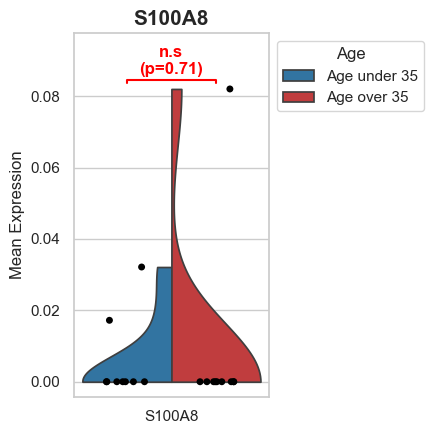

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings
import scanpy as sc
import math

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

adata = Epithelial[
    Epithelial.obs['celltype_grouped'] == 'CD8 T cells'
].copy()

# adata = Epithelial.copy()

genes = ["S100A8"]

target_col = "Age group"

group_order = ["Young", "Aged"]

custom_palette = {
    "Young": "#1f77b4",
    "Aged": "#d62728"
}

legend_labels = {
    "Young": "Age under 35",
    "Aged": "Age over 35"
}

genes = [
    g for g in genes
    if g in adata.var_names
]

expr_df = adata.to_df()
obs_df = adata.obs

plot_list = []

for gene in genes:

    tmp = pd.DataFrame({
        "Expression": expr_df[gene].values,
        "Sample": obs_df["Sample name"].values,
        target_col: obs_df[target_col].values
    })

    tmp = (
        tmp.groupby(
            "Sample",
            as_index=False
        )
        .agg({
            "Expression": "mean",
            target_col: "first"
        })
    )

    tmp["Gene"] = gene

    tmp = tmp.rename(
        columns={
            "Expression": "MeanExpression"
        }
    )

    plot_list.append(tmp)

plot_df = pd.concat(
    plot_list,
    ignore_index=True
)

fig, axes = plt.subplots(
    1,
    len(genes),
    figsize=(4.5 * len(genes), 4.5)
)

if len(genes) == 1:
    axes = [axes]

for i, gene in enumerate(genes):

    ax = axes[i]

    sub_df = plot_df[
        plot_df["Gene"] == gene
    ].copy()

    sub_df = sub_df.dropna(
        subset=[
            "MeanExpression",
            target_col
        ]
    )

    sub_df[target_col] = pd.Categorical(
        sub_df[target_col],
        categories=group_order,
        ordered=True
    )

    sub_df = sub_df.sort_values(
        target_col
    ).reset_index(drop=True)

    sns.violinplot(
        data=sub_df,
        x=np.array(
            [gene] * len(sub_df)
        ),
        y="MeanExpression",
        hue=target_col,
        hue_order=group_order,
        palette=custom_palette,
        split=True,
        inner=None,
        ax=ax,
        cut=0
    )

    sns.stripplot(
        data=sub_df,
        x=np.array(
            [gene] * len(sub_df)
        ),
        y="MeanExpression",
        hue=target_col,
        hue_order=group_order,
        palette={
            "Young": "black",
            "Aged": "black"
        },
        dodge=True,
        ax=ax,
        size=5,
        jitter=0.2
    )

    g1 = sub_df[
        sub_df[target_col] == "Young"
    ]["MeanExpression"]

    g2 = sub_df[
        sub_df[target_col] == "Aged"
    ]["MeanExpression"]

    _, p = ranksums(g1, g2)

    p_trunc = math.floor(p * 100) / 100

    sig = (
        "***" if p < 0.001 else
        "**" if p < 0.01 else
        "*" if p < 0.05 else
        "n.s"
    )

    y_max = sub_df[
        "MeanExpression"
    ].max()

    y_min = sub_df[
        "MeanExpression"
    ].min()

    y_range = (
        y_max - y_min
        if y_max != y_min
        else 1
    )

    y_line = y_max + (
        y_range * 0.02
    )

    y_text = y_line + (
        y_range * 0.02
    )

    ax.plot(
        [-0.2, -0.2, 0.2, 0.2],
        [
            y_line,
            y_line + (
                y_range * 0.01
            ),
            y_line + (
                y_range * 0.01
            ),
            y_line
        ],
        lw=1.5,
        c='red'
    )

    ax.text(
        0,
        y_text,
        f"{sig}\n(p={p_trunc:.2f})",
        ha='center',
        va='bottom',
        fontsize=12,
        color='red',
        fontweight='bold'
    )

    ax.set_ylim(
        top=y_text + (
            y_range * 0.15
        )
    )

    ax.set_title(
        gene,
        fontsize=15,
        fontweight='bold'
    )

    ax.set_xlabel("")

    ax.set_ylabel(
        "Mean Expression"
    )

    if i == len(genes) - 1:

        handles, labels = (
            ax.get_legend_handles_labels()
        )

        new_labels = [
            legend_labels.get(l, l)
            for l in labels[:2]
        ]

        ax.legend(
            handles[:2],
            new_labels,
            title="Age",
            loc='upper left',
            bbox_to_anchor=(1, 1)
        )

    else:

        if ax.get_legend():
            ax.get_legend().remove()

plt.tight_layout()
plt.show()

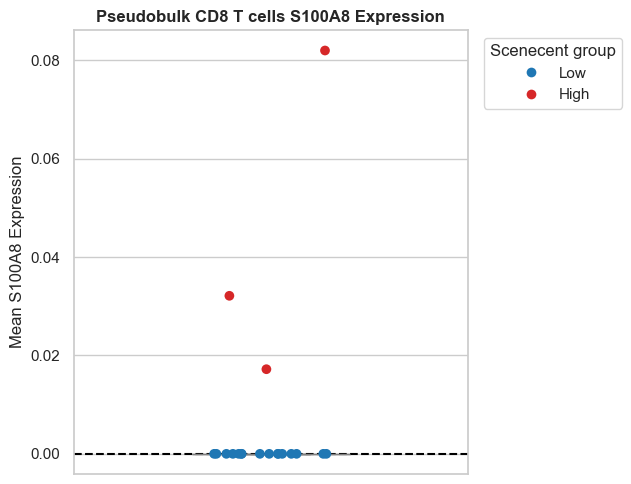

0.50 quantile cutoff = 0.0
High : ['UA_Endo11460962_FX1170', 'UA_Endo12296823_FX1119', 'UA_Endo12961679_SE02']
Low : ['FRZFRESH_GX25_ES345', 'FRZFRESH_GX27_ES345', 'HCA_A_RepT_RNA13247830_A70', 'UA_Endo9426399_FX1146', 'UA_Endo11173480_FX0052', 'UA_Endo11173482_FX9011', 'UA_Endo11282193_EX0540', 'UA_Endo11460961_FX1097', 'UA_Endo11596522_FX9005', 'UA_Endo12061704_FX1163', 'UA_Endo12269810_FX1106', 'UA_Endo12296824_FX9008', 'UA_Endo12449300_FX9027', 'UA_Endo12604667_FX1130', 'UA_Endo12680031_FX1259', 'UA_Endo12961681_SE03']


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

gene = "S100A8"

expr = adata[:, gene].X

if hasattr(expr, "toarray"):
    expr = expr.toarray().flatten()
else:
    expr = expr.flatten()

plot_df = pd.DataFrame({
    "Sample": adata.obs["Sample name"].values,
    "Expression": expr
})

plot_df = (
    plot_df.groupby("Sample", as_index=False)
    .agg({
        "Expression": "mean"
    })
)

plot_df = plot_df.rename(
    columns={"Expression": "MeanExpression"}
)

cutoff = plot_df["MeanExpression"].quantile(0.50)

plot_df["Scenecent_group"] = np.where(
    plot_df["MeanExpression"] > cutoff,
    "High",
    "Low"
)

plt.figure(figsize=(6.5, 5))

ax = sns.boxplot(
    data=plot_df,
    y="MeanExpression",
    width=0.4,
    fliersize=0,
    color="lightgray"
)

sns.stripplot(
    data=plot_df,
    y="MeanExpression",
    hue="Scenecent_group",
    palette={
        "Low": "#1f77b4",
        "High": "#d62728"
    },
    size=7,
    jitter=0.15,
    ax=ax
)

plt.axhline(
    cutoff,
    linestyle="--",
    linewidth=1.5,
    color="black"
)

plt.ylabel("Mean S100A8 Expression")

plt.title(
    "Pseudobulk CD8 T cells S100A8 Expression",
    fontweight="bold"
)

handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles[:2],
    labels[:2],
    title="Scenecent group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

high_samples = plot_df[
    plot_df["Scenecent_group"] == "High"
]["Sample"].tolist()

low_samples = plot_df[
    plot_df["Scenecent_group"] == "Low"
]["Sample"].tolist()

print(f"0.50 quantile cutoff = {cutoff}")

print(f"High : {high_samples}")
print(f"Low : {low_samples}")

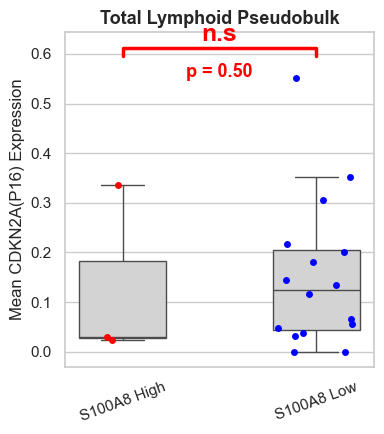

In [28]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

high_samples = ['UA_Endo11460962_FX1170', 'UA_Endo12296823_FX1119', 'UA_Endo12961679_SE02']

low_samples = ['FRZFRESH_GX25_ES345', 'FRZFRESH_GX27_ES345', 'HCA_A_RepT_RNA13247830_A70', 
               'UA_Endo9426399_FX1146', 'UA_Endo11173480_FX0052', 'UA_Endo11173482_FX9011', 
               'UA_Endo11282193_EX0540', 'UA_Endo11460961_FX1097', 'UA_Endo11596522_FX9005', 
               'UA_Endo12061704_FX1163', 'UA_Endo12269810_FX1106', 'UA_Endo12296824_FX9008', 
               'UA_Endo12449300_FX9027', 'UA_Endo12604667_FX1130', 'UA_Endo12680031_FX1259', 
               'UA_Endo12961681_SE03']

clin_palette = {
    'High': '#ff0000',
    'Low': '#0000ff',
}

label_map = {
    'High': 'S100A8 High',
    'Low': 'S100A8 Low'
}

group_order = ['High', 'Low']

gene = "CDKN2A"
sample_col = "Sample name"

expr = adata[:, gene].X

if hasattr(expr, "toarray"):
    expr = expr.toarray().flatten()
else:
    expr = np.array(expr).flatten()

df = pd.DataFrame({
    "Sample": adata.obs[sample_col].values,
    "Expression": expr
})

pseudobulk = (
    df.groupby("Sample")["Expression"]
    .mean()
    .reset_index()
)

pseudobulk["Group"] = "Other"

pseudobulk.loc[
    pseudobulk["Sample"].isin(high_samples),
    "Group"
] = "High"

pseudobulk.loc[
    pseudobulk["Sample"].isin(low_samples),
    "Group"
] = "Low"

pseudobulk = pseudobulk[
    pseudobulk["Group"].isin(["High", "Low"])
]

high_vals = pseudobulk.loc[
    pseudobulk["Group"] == "High",
    "Expression"
]

low_vals = pseudobulk.loc[
    pseudobulk["Group"] == "Low",
    "Expression"
]

stat, pval = ranksums(high_vals, low_vals)

fig, ax = plt.subplots(figsize=(4, 4.5))

sns.boxplot(
    x='Group',
    y='Expression',
    data=pseudobulk,
    ax=ax,
    order=group_order,
    boxprops={'facecolor': 'lightgray'},
    fliersize=0,
    width=0.45
)

for cond in pseudobulk['Group'].unique():

    sub_df = pseudobulk[
        pseudobulk['Group'] == cond
    ]

    sns.stripplot(
        x='Group',
        y='Expression',
        data=sub_df,
        color=clin_palette.get(cond, 'black'),
        jitter=0.2,
        size=5,
        ax=ax,
        order=group_order
    )

x1, x2 = 0, 1

y = pseudobulk["Expression"].max() * 1.08
h = pseudobulk["Expression"].max() * 0.03

ax.plot(
    [x1, x1, x2, x2],
    [y, y + h, y + h, y],
    c='red',
    linewidth=2.5
)

ax.text(
    (x1 + x2) / 2,
    y + h * 1.15,
    "n.s",
    ha='center',
    va='bottom',
    color='red',
    fontsize=18,
    fontweight='bold'
)

ax.text(
    (x1 + x2) / 2,
    y - h * 0.9,
    f"p = {pval:.2f}",
    ha='center',
    va='top',
    color='red',
    fontsize=13,
    fontweight='bold'
)

ax.set_xticklabels(
    [label_map[x] for x in group_order],
    rotation=20
)

ax.set_ylabel(f"Mean {gene}(P16) Expression")
ax.set_xlabel("")

ax.set_title(
    "Total Lymphoid Pseudobulk",
    fontweight='bold',
    fontsize=13
)

plt.tight_layout()
plt.show()

Pearson r = 0.405, p = 0.08
Spearman rho = 0.488, p = 0.03


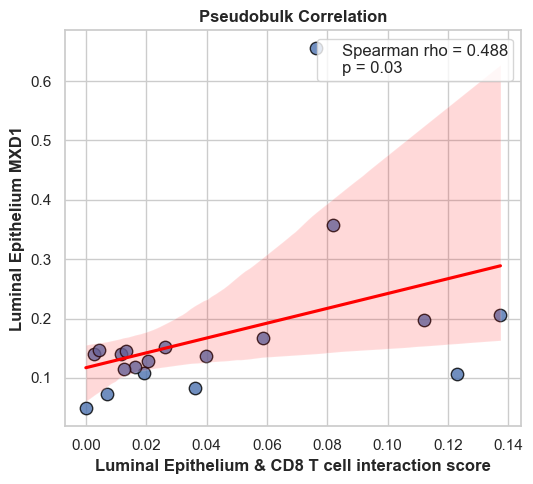

In [253]:
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from matplotlib.lines import Line2D
import math

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad"
)

Lymphoid = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

epi = Epithelial[
    Epithelial.obs["subtype"] == "Luminal Epithelium"
].copy()

# epi = Epithelial.copy()

lym = Lymphoid[
    Lymphoid.obs["celltype_grouped"] == "CD8 T cells"
].copy()

# lym = Lymphoid.copy()

epi_tlr4 = epi[:, "TLR4"].X
epi_mxd1 = epi[:, "MXD1"].X
lym_s100a8 = lym[:, "S100A8"].X

if hasattr(epi_tlr4, "toarray"):
    epi_tlr4 = epi_tlr4.toarray().flatten()
else:
    epi_tlr4 = epi_tlr4.flatten()

if hasattr(epi_mxd1, "toarray"):
    epi_mxd1 = epi_mxd1.toarray().flatten()
else:
    epi_mxd1 = epi_mxd1.flatten()

if hasattr(lym_s100a8, "toarray"):
    lym_s100a8 = lym_s100a8.toarray().flatten()
else:
    lym_s100a8 = lym_s100a8.flatten()

epi_tlr4_df = pd.DataFrame({
    "Sample": epi.obs["Sample name"].values,
    "TLR4": epi_tlr4
})

epi_mxd1_df = pd.DataFrame({
    "Sample": epi.obs["Sample name"].values,
    "MXD1": epi_mxd1
})

lym_s100a8_df = pd.DataFrame({
    "Sample": lym.obs["Sample name"].values,
    "S100A8": lym_s100a8
})

epi_tlr4_df = (
    epi_tlr4_df
    .groupby("Sample", as_index=False)
    .mean()
)

epi_mxd1_df = (
    epi_mxd1_df
    .groupby("Sample", as_index=False)
    .mean()
)

lym_s100a8_df = (
    lym_s100a8_df
    .groupby("Sample", as_index=False)
    .mean()
)

merged = pd.merge(
    epi_tlr4_df,
    lym_s100a8_df,
    on="Sample"
)

merged = pd.merge(
    merged,
    epi_mxd1_df,
    on="Sample"
)

merged["TLR4xS100A8"] = (
    merged["TLR4"] +
    merged["S100A8"]
)

pearson_r, pearson_p = pearsonr(
    merged["TLR4xS100A8"],
    merged["MXD1"]
)

spearman_r, spearman_p = spearmanr(
    merged["TLR4xS100A8"],
    merged["MXD1"]
)

pearson_p_trunc = (
    math.floor(pearson_p * 100) / 100
)

spearman_p_trunc = (
    math.floor(spearman_p * 100) / 100
)

print(
    f"Pearson r = {pearson_r:.3f}, "
    f"p = {pearson_p_trunc:.2f}"
)

print(
    f"Spearman rho = {spearman_r:.3f}, "
    f"p = {spearman_p_trunc:.2f}"
)

plt.figure(figsize=(5.5, 5))

sns.regplot(
    data=merged,
    x="TLR4xS100A8",
    y="MXD1",
    scatter_kws={
        "s": 80,
        "edgecolor": "black"
    },
    line_kws={
        "color": "red"
    }
)

plt.xlabel(
    "Luminal Epithelium & CD8 T cell interaction score",
    fontweight="bold"
)

plt.ylabel(
    "Luminal Epithelium MXD1",
    fontweight="bold"
)

plt.title(
    "Pseudobulk Correlation",
    fontweight="bold"
)

legend_text = Line2D(
    [],
    [],
    color="none",
    label=(
        f"Spearman rho = "
        f"{spearman_r:.3f}\n"
        f"p = {spearman_p_trunc:.2f}"
    )
)

plt.legend(
    handles=[legend_text],
    loc="upper right",
    frameon=True,
    fontsize=12,
    handlelength=0.8,
    handletextpad=0.4,
    borderpad=0.3,
    labelspacing=0.3
)

plt.tight_layout()
plt.show()

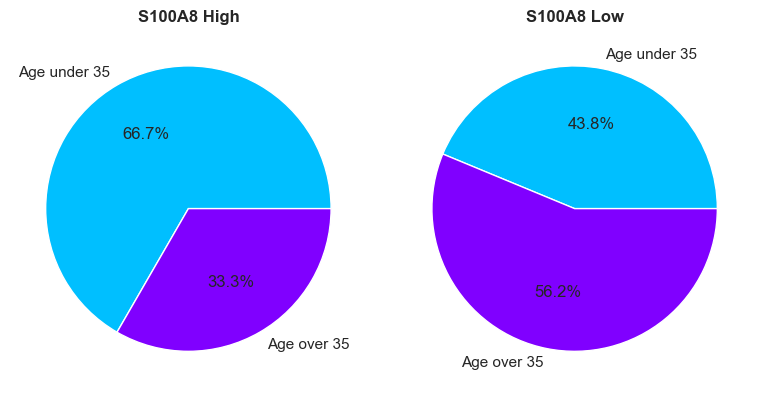

In [212]:
import pandas as pd
import matplotlib.pyplot as plt

high_samples = ['UA_Endo11460962_FX1170', 'UA_Endo12296823_FX1119', 'UA_Endo12961679_SE02']


low_samples = ['FRZFRESH_GX25_ES345', 'FRZFRESH_GX27_ES345', 'HCA_A_RepT_RNA13247830_A70', 'UA_Endo9426399_FX1146', 'UA_Endo11173480_FX0052', 
               'UA_Endo11173482_FX9011', 'UA_Endo11282193_EX0540', 'UA_Endo11460961_FX1097', 'UA_Endo11596522_FX9005', 'UA_Endo12061704_FX1163', 
               'UA_Endo12269810_FX1106', 'UA_Endo12296824_FX9008', 'UA_Endo12449300_FX9027', 'UA_Endo12604667_FX1130', 'UA_Endo12680031_FX1259', 
               'UA_Endo12961681_SE03']

sample_age = (
    Epithelial.obs[
        ["Sample name", "Age group"]
    ]
    .drop_duplicates()
)

high_age = sample_age[
    sample_age["Sample name"].isin(high_samples)
]

low_age = sample_age[
    sample_age["Sample name"].isin(low_samples)
]

high_counts = (
    high_age["Age group"]
    .value_counts()
    .reindex(["Young", "Aged"], fill_value=0)
)

low_counts = (
    low_age["Age group"]
    .value_counts()
    .reindex(["Young", "Aged"], fill_value=0)
)

label_map = {
    "Young": "Age under 35",
    "Aged": "Age over 35"
}

colors = {
    "Young": "#00bfff",
    "Aged": "#8000ff"
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 4)
)

axes[0].pie(
    high_counts.values,
    labels=[
        label_map[x]
        for x in high_counts.index
    ],
    colors=[
        colors[x]
        for x in high_counts.index
    ],
    autopct="%1.1f%%"
)

axes[0].set_title(
    "S100A8 High",
    fontweight="bold"
)

axes[1].pie(
    low_counts.values,
    labels=[
        label_map[x]
        for x in low_counts.index
    ],
    colors=[
        colors[x]
        for x in low_counts.index
    ],
    autopct="%1.1f%%"
)

axes[1].set_title(
    "S100A8 Low",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Interaction

Pearson r = 0.405, p = 0.08
Spearman rho = 0.488, p = 0.03


/tmp/ipykernel_2340048/986493886.py:63: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  epi_tlr4_df
/tmp/ipykernel_2340048/986493886.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  epi_mxd1_df
/tmp/ipykernel_2340048/986493886.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lym_s100a8_df


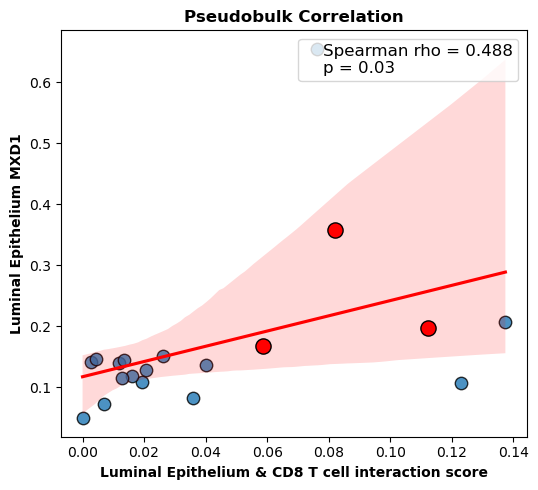

In [27]:
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from matplotlib.lines import Line2D
import math

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad"
)

Lymphoid = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

epi = Epithelial[
    Epithelial.obs["subtype"] == "Luminal Epithelium"
].copy()

# lym = Lymphoid.copy()

lym = Lymphoid[
    Lymphoid.obs["celltype_grouped"] == "CD8 T cells"
].copy()

epi_tlr4 = epi[:, "TLR4"].X
epi_mxd1 = epi[:, "MXD1"].X
lym_s100a8 = lym[:, "S100A8"].X

if hasattr(epi_tlr4, "toarray"):
    epi_tlr4 = epi_tlr4.toarray().flatten()
else:
    epi_tlr4 = epi_tlr4.flatten()

if hasattr(epi_mxd1, "toarray"):
    epi_mxd1 = epi_mxd1.toarray().flatten()
else:
    epi_mxd1 = epi_mxd1.flatten()

if hasattr(lym_s100a8, "toarray"):
    lym_s100a8 = lym_s100a8.toarray().flatten()
else:
    lym_s100a8 = lym_s100a8.flatten()

epi_tlr4_df = pd.DataFrame({
    "Sample": epi.obs["Sample name"].values,
    "TLR4": epi_tlr4
})

epi_mxd1_df = pd.DataFrame({
    "Sample": epi.obs["Sample name"].values,
    "MXD1": epi_mxd1
})

lym_s100a8_df = pd.DataFrame({
    "Sample": lym.obs["Sample name"].values,
    "S100A8": lym_s100a8
})

epi_tlr4_df = (
    epi_tlr4_df
    .groupby("Sample", as_index=False)
    .mean()
)

epi_mxd1_df = (
    epi_mxd1_df
    .groupby("Sample", as_index=False)
    .mean()
)

lym_s100a8_df = (
    lym_s100a8_df
    .groupby("Sample", as_index=False)
    .mean()
)

merged = pd.merge(
    epi_tlr4_df,
    lym_s100a8_df,
    on="Sample"
)

merged = pd.merge(
    merged,
    epi_mxd1_df,
    on="Sample"
)

merged["TLR4xS100A8"] = (
    merged["TLR4"] +
    merged["S100A8"]
)

pearson_r, pearson_p = pearsonr(
    merged["TLR4xS100A8"],
    merged["MXD1"]
)

spearman_r, spearman_p = spearmanr(
    merged["TLR4xS100A8"],
    merged["MXD1"]
)

pearson_p_trunc = (
    math.floor(pearson_p * 100) / 100
)

spearman_p_trunc = (
    math.floor(spearman_p * 100) / 100
)

print(
    f"Pearson r = {pearson_r:.3f}, "
    f"p = {pearson_p_trunc:.2f}"
)

print(
    f"Spearman rho = {spearman_r:.3f}, "
    f"p = {spearman_p_trunc:.2f}"
)

highlight_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

highlight_mask = merged[
    "Sample"
].isin(highlight_samples)

plt.figure(figsize=(5.5, 5))

sns.regplot(
    data=merged,
    x="TLR4xS100A8",
    y="MXD1",
    scatter_kws={
        "s": 80,
        "edgecolor": "black"
    },
    line_kws={
        "color": "red"
    }
)

plt.scatter(
    merged.loc[
        highlight_mask,
        "TLR4xS100A8"
    ],
    merged.loc[
        highlight_mask,
        "MXD1"
    ],
    color="red",
    s=120,
    edgecolor="black",
    zorder=5
)

plt.xlabel(
    "Luminal Epithelium & CD8 T cell interaction score",
    fontweight="bold"
)

plt.ylabel(
    "Luminal Epithelium MXD1",
    fontweight="bold"
)

plt.title(
    "Pseudobulk Correlation",
    fontweight="bold"
)

legend_text = Line2D(
    [],
    [],
    color="none",
    label=(
        f"Spearman rho = "
        f"{spearman_r:.3f}\n"
        f"p = {spearman_p_trunc:.2f}"
    )
)

plt.legend(
    handles=[legend_text],
    loc="upper right",
    frameon=True,
    fontsize=12,
    handlelength=0.8,
    handletextpad=0.4,
    borderpad=0.3,
    labelspacing=0.3
)

plt.tight_layout()
plt.show()

Pearson r = 0.239, p = 0.32
Spearman rho = 0.330, p = 0.16


/tmp/ipykernel_2340048/3595421966.py:63: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  epi_tlr4_df
/tmp/ipykernel_2340048/3595421966.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  epi_mxd1_df
/tmp/ipykernel_2340048/3595421966.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lym_s100a8_df


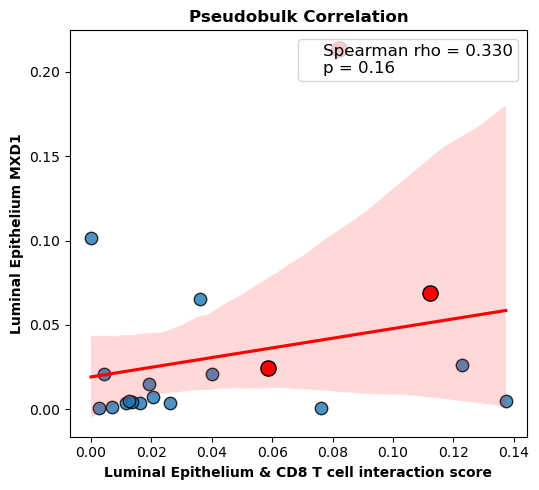

In [26]:
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from matplotlib.lines import Line2D
import math

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad"
)

Lymphoid = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

epi = Epithelial[
    Epithelial.obs["subtype"] == "Luminal Epithelium"
].copy()

# lym = Lymphoid.copy()

lym = Lymphoid[
    Lymphoid.obs["celltype_grouped"] == "CD8 T cells"
].copy()

epi_tlr4 = epi[:, "TLR4"].X
epi_mxd1 = epi[:, "MUC4"].X
lym_s100a8 = lym[:, "S100A8"].X

if hasattr(epi_tlr4, "toarray"):
    epi_tlr4 = epi_tlr4.toarray().flatten()
else:
    epi_tlr4 = epi_tlr4.flatten()

if hasattr(epi_mxd1, "toarray"):
    epi_mxd1 = epi_mxd1.toarray().flatten()
else:
    epi_mxd1 = epi_mxd1.flatten()

if hasattr(lym_s100a8, "toarray"):
    lym_s100a8 = lym_s100a8.toarray().flatten()
else:
    lym_s100a8 = lym_s100a8.flatten()

epi_tlr4_df = pd.DataFrame({
    "Sample": epi.obs["Sample name"].values,
    "TLR4": epi_tlr4
})

epi_mxd1_df = pd.DataFrame({
    "Sample": epi.obs["Sample name"].values,
    "MXD1": epi_mxd1
})

lym_s100a8_df = pd.DataFrame({
    "Sample": lym.obs["Sample name"].values,
    "S100A8": lym_s100a8
})

epi_tlr4_df = (
    epi_tlr4_df
    .groupby("Sample", as_index=False)
    .mean()
)

epi_mxd1_df = (
    epi_mxd1_df
    .groupby("Sample", as_index=False)
    .mean()
)

lym_s100a8_df = (
    lym_s100a8_df
    .groupby("Sample", as_index=False)
    .mean()
)

merged = pd.merge(
    epi_tlr4_df,
    lym_s100a8_df,
    on="Sample"
)

merged = pd.merge(
    merged,
    epi_mxd1_df,
    on="Sample"
)

merged["TLR4xS100A8"] = (
    merged["TLR4"] +
    merged["S100A8"]
)

pearson_r, pearson_p = pearsonr(
    merged["TLR4xS100A8"],
    merged["MXD1"]
)

spearman_r, spearman_p = spearmanr(
    merged["TLR4xS100A8"],
    merged["MXD1"]
)

pearson_p_trunc = (
    math.floor(pearson_p * 100) / 100
)

spearman_p_trunc = (
    math.floor(spearman_p * 100) / 100
)

print(
    f"Pearson r = {pearson_r:.3f}, "
    f"p = {pearson_p_trunc:.2f}"
)

print(
    f"Spearman rho = {spearman_r:.3f}, "
    f"p = {spearman_p_trunc:.2f}"
)

highlight_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

highlight_mask = merged[
    "Sample"
].isin(highlight_samples)

plt.figure(figsize=(5.5, 5))

sns.regplot(
    data=merged,
    x="TLR4xS100A8",
    y="MXD1",
    scatter_kws={
        "s": 80,
        "edgecolor": "black"
    },
    line_kws={
        "color": "red"
    }
)

plt.scatter(
    merged.loc[
        highlight_mask,
        "TLR4xS100A8"
    ],
    merged.loc[
        highlight_mask,
        "MXD1"
    ],
    color="red",
    s=120,
    edgecolor="black",
    zorder=5
)

plt.xlabel(
    "Luminal Epithelium & CD8 T cell interaction score",
    fontweight="bold"
)

plt.ylabel(
    "Luminal Epithelium MXD1",
    fontweight="bold"
)

plt.title(
    "Pseudobulk Correlation",
    fontweight="bold"
)

legend_text = Line2D(
    [],
    [],
    color="none",
    label=(
        f"Spearman rho = "
        f"{spearman_r:.3f}\n"
        f"p = {spearman_p_trunc:.2f}"
    )
)

plt.legend(
    handles=[legend_text],
    loc="upper right",
    frameon=True,
    fontsize=12,
    handlelength=0.8,
    handletextpad=0.4,
    borderpad=0.3,
    labelspacing=0.3
)

plt.tight_layout()
plt.show()

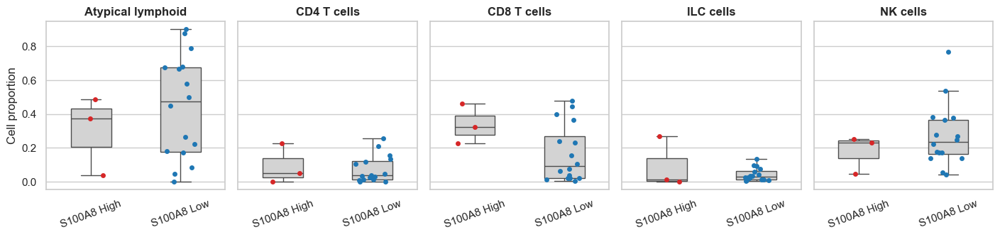

In [227]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

high_samples = ['UA_Endo11460962_FX1170', 'UA_Endo12296823_FX1119', 'UA_Endo12961679_SE02']


low_samples = ['FRZFRESH_GX25_ES345', 'FRZFRESH_GX27_ES345', 'HCA_A_RepT_RNA13247830_A70', 'UA_Endo9426399_FX1146', 'UA_Endo11173480_FX0052', 
               'UA_Endo11173482_FX9011', 'UA_Endo11282193_EX0540', 'UA_Endo11460961_FX1097', 'UA_Endo11596522_FX9005', 'UA_Endo12061704_FX1163', 
               'UA_Endo12269810_FX1106', 'UA_Endo12296824_FX9008', 'UA_Endo12449300_FX9027', 'UA_Endo12604667_FX1130', 'UA_Endo12680031_FX1259', 
               'UA_Endo12961681_SE03']

clin_palette = {
    'High': '#d62728',
    'Low': '#1f77b4'
}

label_map = {
    'High': 'S100A8 High',
    'Low': 'S100A8 Low'
}

Epithelial.obs['Each mouse'] = Epithelial.obs['Sample name']

adata_filtered = Epithelial[
    Epithelial.obs['Organism part'] != 'spleen'
].copy()

adata_filtered.obs['S100A8_group'] = 'NA'

adata_filtered.obs.loc[
    adata_filtered.obs['Sample name'].isin(high_samples),
    'S100A8_group'
] = 'High'

adata_filtered.obs.loc[
    adata_filtered.obs['Sample name'].isin(low_samples),
    'S100A8_group'
] = 'Low'

adata_filtered = adata_filtered[
    adata_filtered.obs['S100A8_group'].isin(['High', 'Low'])
].copy()

group_order = ['High', 'Low']

celltype_groups = sorted(
    adata_filtered.obs['celltype_grouped'].dropna().unique()
)

def normalize_mouse(df):
    total = df['count'].sum()

    if total > 0:
        df['proportion'] = df['count'] / total
    else:
        df['proportion'] = 0

    return df

mouse_props_list = []

for (mouse, s100_group), grp_df in adata_filtered.obs.groupby(
    ['Each mouse', 'S100A8_group']
):

    count_df = (
        grp_df.groupby('celltype_grouped')
        .size()
        .reset_index(name='count')
    )

    count_df['Each mouse'] = mouse
    count_df['S100A8_group'] = s100_group

    count_df = normalize_mouse(count_df)

    mouse_props_list.append(count_df)

mouse_props = pd.concat(
    mouse_props_list,
    ignore_index=True
)

n_celltypes = len(celltype_groups)

n_cols = 5
n_rows = int(np.ceil(n_celltypes / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(2.85 * n_cols, 3.5 * n_rows),
    sharey=True
)

axes = np.array(axes).flatten()

for i, ct in enumerate(celltype_groups):

    ax = axes[i]

    data_sub = mouse_props[
        mouse_props['celltype_grouped'] == ct
    ]

    sns.boxplot(
        x='S100A8_group',
        y='proportion',
        data=data_sub,
        order=group_order,
        ax=ax,
        boxprops={'facecolor': 'lightgray'},
        width=0.45,
        fliersize=0
    )

    for cond in group_order:

        sub_df = data_sub[
            data_sub['S100A8_group'] == cond
        ]

        sns.stripplot(
            x='S100A8_group',
            y='proportion',
            data=sub_df,
            order=group_order,
            color=clin_palette[cond],
            jitter=0.2,
            size=5,
            ax=ax
        )

    v1 = data_sub[
        data_sub['S100A8_group'] == 'High'
    ]['proportion']

    v2 = data_sub[
        data_sub['S100A8_group'] == 'Low'
    ]['proportion']

    if len(v1) > 0 and len(v2) > 0:

        _, p = ranksums(v1, v2)

        if p < 0.06:

            x1, x2 = 0, 1

            ymax = data_sub['proportion'].max()

            y = ymax * 1.08 if ymax > 0 else 0.05

            ax.plot(
                [x1, x1, x2, x2],
                [y, y + 0.01, y + 0.01, y],
                c='red'
            )

            ax.text(
                (x1 + x2) / 2,
                y + 0.015,
                f"* p={p:.3f}",
                ha='center',
                color='red',
                fontsize=9
            )

    ax.set_xticklabels(
        [label_map[x] for x in group_order],
        rotation=20
    )

    ax.set_title(
        ct,
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel("")
    ax.set_ylabel("Cell proportion")

for j in range(len(celltype_groups), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

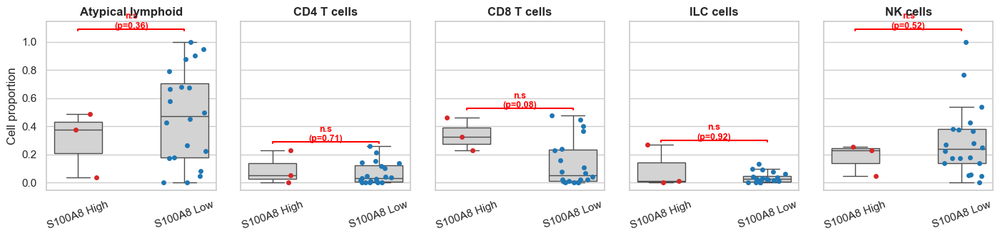

In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings
import math

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

high_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

clin_palette = {
    'High': '#d62728',
    'Low': '#1f77b4'
}

label_map = {
    'High': 'S100A8 High',
    'Low': 'S100A8 Low'
}

Epithelial.obs['Each mouse'] = Epithelial.obs['Sample name']

adata_filtered = Epithelial[
    Epithelial.obs['Organism part'] != 'spleen'
].copy()

adata_filtered.obs['S100A8_group'] = np.where(
    adata_filtered.obs['Sample name'].isin(high_samples),
    'High',
    'Low'
)

group_order = ['High', 'Low']

celltype_groups = sorted(
    adata_filtered.obs['celltype_grouped']
    .dropna()
    .unique()
)

def normalize_mouse(df):

    total = df['count'].sum()

    if total > 0:
        df['proportion'] = df['count'] / total
    else:
        df['proportion'] = 0

    return df

mouse_props_list = []

for (mouse, s100_group), grp_df in adata_filtered.obs.groupby(
    ['Each mouse', 'S100A8_group']
):

    count_df = (
        grp_df.groupby('celltype_grouped')
        .size()
        .reset_index(name='count')
    )

    count_df['Each mouse'] = mouse
    count_df['S100A8_group'] = s100_group

    count_df = normalize_mouse(count_df)

    mouse_props_list.append(count_df)

mouse_props = pd.concat(
    mouse_props_list,
    ignore_index=True
)

n_celltypes = len(celltype_groups)

n_cols = 5
n_rows = int(np.ceil(n_celltypes / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(2.85 * n_cols, 3.5 * n_rows),
    sharey=True
)

axes = np.array(axes).flatten()

for i, ct in enumerate(celltype_groups):

    ax = axes[i]

    data_sub = mouse_props[
        mouse_props['celltype_grouped'] == ct
    ]

    sns.boxplot(
        x='S100A8_group',
        y='proportion',
        data=data_sub,
        order=group_order,
        ax=ax,
        boxprops={'facecolor': 'lightgray'},
        width=0.45,
        fliersize=0
    )

    for cond in group_order:

        sub_df = data_sub[
            data_sub['S100A8_group'] == cond
        ]

        sns.stripplot(
            x='S100A8_group',
            y='proportion',
            data=sub_df,
            order=group_order,
            color=clin_palette[cond],
            jitter=0.2,
            size=5,
            ax=ax
        )

    v1 = data_sub[
        data_sub['S100A8_group'] == 'High'
    ]['proportion']

    v2 = data_sub[
        data_sub['S100A8_group'] == 'Low'
    ]['proportion']

    if len(v1) > 0 and len(v2) > 0:

        _, p = ranksums(v1, v2)

        p_trunc = (
            math.floor(p * 100) / 100
        )

        sig = (
            "***" if p < 0.001 else
            "**" if p < 0.01 else
            "*" if p < 0.06 else
            "n.s"
        )

        x1, x2 = 0, 1

        ymax = data_sub['proportion'].max()

        y = ymax * 1.08 if ymax > 0 else 0.05

        ax.plot(
            [x1, x1, x2, x2],
            [y, y + 0.01, y + 0.01, y],
            c='red'
        )

        ax.text(
            (x1 + x2) / 2,
            y + 0.015,
            f"{sig}\n(p={p_trunc:.2f})",
            ha='center',
            color='red',
            fontsize=9,
            fontweight='bold'
        )

    ax.set_xticklabels(
        [label_map[x] for x in group_order],
        rotation=20
    )

    ax.set_title(
        ct,
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel("")
    ax.set_ylabel("Cell proportion")

for j in range(len(celltype_groups), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [260]:
from scipy.stats import ranksums

cd8_df = mouse_props[
    mouse_props['celltype_grouped'] == 'CD8 T cells'
]

high_vals = cd8_df[
    cd8_df['S100A8_group'] == 'High'
]['proportion']

low_vals = cd8_df[
    cd8_df['S100A8_group'] == 'Low'
]['proportion']

stat, p = ranksums(high_vals, low_vals)

print("=== CD8 T cells ===")
print(f"High mean proportion : {high_vals.mean():.6f}")
print(f"Low mean proportion  : {low_vals.mean():.6f}")
print(f"Statistic            : {stat:.6f}")
print(f"P-value              : {p:.6f}")

print("\nHigh values")
print(high_vals.tolist())

print("\nLow values")
print(low_vals.tolist())

=== CD8 T cells ===
High mean proportion : 0.337669
Low mean proportion  : 0.134085
Statistic            : 1.734455
P-value              : 0.082837

High values
[0.32323232323232326, 0.22823529411764706, 0.46153846153846156]

Low values
[0.36363636363636365, 0.0, 0.47761194029850745, 0.0, 0.4, 0.4458204334365325, 0.038922155688622756, 0.10526315789473684, 0.02197802197802198, 0.07741935483870968, 0.02112676056338028, 0.15637860082304528, 0.005771248688352571, 0.012396694214876033, 0.020761245674740483, 0.06521739130434782, 0.23863636363636365, 0.0, 0.23076923076923078, 0.0]


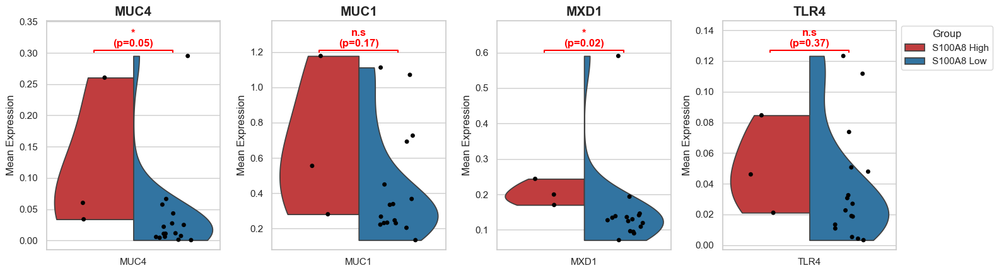

In [258]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import numpy as np
import math

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad"
)

adata = Epithelial.copy()

high_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

low_samples = [
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX27_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11282193_EX0540',
    'UA_Endo11460961_FX1097',
    'UA_Endo11596522_FX9005',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961681_SE03'
]

genes = ["MUC4", "MUC1", "MXD1", "TLR4"]

group_order = ["High", "Low"]

custom_palette = {
    "High": "#d62728",
    "Low": "#1f77b4"
}

legend_labels = {
    "High": "S100A8 High",
    "Low": "S100A8 Low"
}

genes = [
    g for g in genes
    if g in adata.var_names
]

adata.obs["S100A8_group"] = "NA"

adata.obs.loc[
    adata.obs["Sample name"].isin(high_samples),
    "S100A8_group"
] = "High"

adata.obs.loc[
    adata.obs["Sample name"].isin(low_samples),
    "S100A8_group"
] = "Low"

adata = adata[
    adata.obs["S100A8_group"].isin(
        ["High", "Low"]
    )
].copy()

plot_list = []

expr_df = adata.to_df()
obs_df = adata.obs

for gene in genes:

    df_gene = expr_df[gene]

    unique_samples = obs_df[
        "Sample name"
    ].unique()

    for sample in unique_samples:

        idx = obs_df.index[
            obs_df["Sample name"] == sample
        ]

        mean_exp = df_gene.loc[idx].mean()

        group_val = obs_df.loc[
            idx,
            "S100A8_group"
        ].iloc[0]

        plot_list.append({
            "Gene": gene,
            "Sample": sample,
            "Group": group_val,
            "MeanExpression": mean_exp
        })

plot_df = pd.DataFrame(plot_list)

fig, axes = plt.subplots(
    1,
    len(genes),
    figsize=(4 * len(genes), 4.5)
)

if len(genes) == 1:
    axes = [axes]

for i, gene in enumerate(genes):

    ax = axes[i]

    sub_df = plot_df[
        plot_df["Gene"] == gene
    ].copy()

    sub_df["Group"] = pd.Categorical(
        sub_df["Group"],
        categories=group_order,
        ordered=True
    )

    sub_df = sub_df.sort_values(
        "Group"
    )

    sns.violinplot(
        data=sub_df,
        x=np.array(
            [gene] * len(sub_df)
        ),
        y="MeanExpression",
        hue="Group",
        hue_order=group_order,
        palette=custom_palette,
        split=True,
        inner=None,
        cut=0,
        ax=ax
    )

    sns.stripplot(
        data=sub_df,
        x=np.array(
            [gene] * len(sub_df)
        ),
        y="MeanExpression",
        hue="Group",
        hue_order=group_order,
        palette={
            "High": "black",
            "Low": "black"
        },
        dodge=True,
        jitter=0.2,
        size=5,
        ax=ax
    )

    g1 = sub_df[
        sub_df["Group"] == "High"
    ]["MeanExpression"]

    g2 = sub_df[
        sub_df["Group"] == "Low"
    ]["MeanExpression"]

    stat, p = ranksums(g1, g2)

    p_trunc = (
        math.floor(p * 100) / 100
    )

    sig = (
        "***" if p < 0.001 else
        "**" if p < 0.01 else
        "*" if p < 0.06 else
        "n.s"
    )

    y_max = sub_df[
        "MeanExpression"
    ].max()

    y_min = sub_df[
        "MeanExpression"
    ].min()

    y_range = (
        y_max - y_min
        if y_max != y_min
        else y_max
    )

    y_line = y_max + (
        y_range * 0.02
    )

    y_text = y_line + (
        y_range * 0.02
    )

    ax.plot(
        [-0.2, -0.2, 0.2, 0.2],
        [
            y_line,
            y_line + (
                y_range * 0.01
            ),
            y_line + (
                y_range * 0.01
            ),
            y_line
        ],
        lw=1.5,
        c="red"
    )

    ax.text(
        0,
        y_text,
        f"{sig}\n(p={p_trunc:.2f})",
        ha="center",
        va="bottom",
        fontsize=12,
        color="red",
        fontweight="bold"
    )

    ax.set_ylim(
        top=y_text + (
            y_range * 0.15
        )
    )

    ax.set_title(
        gene,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("")

    ax.set_ylabel(
        "Mean Expression"
    )

    if i == len(genes) - 1:

        handles, labels = (
            ax.get_legend_handles_labels()
        )

        new_labels = [
            legend_labels.get(l, l)
            for l in labels[:2]
        ]

        ax.legend(
            handles[:2],
            new_labels,
            title="Group",
            loc="upper left",
            bbox_to_anchor=(1, 1)
        )

    else:

        if ax.get_legend():
            ax.get_legend().remove()

plt.tight_layout()
plt.show()

/tmp/ipykernel_2340048/325374773.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_2340048/325374773.py:243: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
/tmp/ipykernel_2340048/325374773.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_2340048/325374773.py:243: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
/tmp/ipykernel_2340048/325374773.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remove

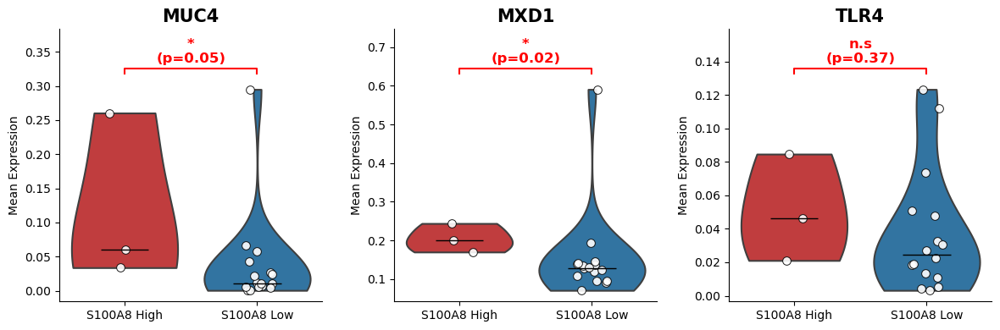

In [21]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import numpy as np
import math

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad"
)

adata = Epithelial.copy()

high_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

low_samples = [
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX27_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11282193_EX0540',
    'UA_Endo11460961_FX1097',
    'UA_Endo11596522_FX9005',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961681_SE03'
]

genes = ["MUC4", "MXD1", "TLR4"]

custom_palette = {
    "High": "#d62728",
    "Low": "#1f77b4"
}

genes = [
    g for g in genes
    if g in adata.var_names
]

adata.obs["S100A8_group"] = "NA"

adata.obs.loc[
    adata.obs["Sample name"].isin(high_samples),
    "S100A8_group"
] = "High"

adata.obs.loc[
    adata.obs["Sample name"].isin(low_samples),
    "S100A8_group"
] = "Low"

adata = adata[
    adata.obs["S100A8_group"].isin(
        ["High", "Low"]
    )
].copy()

plot_list = []

expr_df = adata.to_df()
obs_df = adata.obs

for gene in genes:

    df_gene = expr_df[gene]

    unique_samples = obs_df[
        "Sample name"
    ].unique()

    for sample in unique_samples:

        idx = obs_df.index[
            obs_df["Sample name"] == sample
        ]

        mean_exp = df_gene.loc[idx].mean()

        group_val = obs_df.loc[
            idx,
            "S100A8_group"
        ].iloc[0]

        plot_list.append({
            "Gene": gene,
            "Sample": sample,
            "Group": group_val,
            "MeanExpression": mean_exp
        })

plot_df = pd.DataFrame(plot_list)

fig, axes = plt.subplots(
    1,
    len(genes),
    figsize=(4 * len(genes), 4)
)

if len(genes) == 1:
    axes = [axes]

for i, gene in enumerate(genes):

    ax = axes[i]

    sub_df = plot_df[
        plot_df["Gene"] == gene
    ].copy()

    sns.violinplot(
        data=sub_df,
        x="Group",
        y="MeanExpression",
        order=["High", "Low"],
        palette=custom_palette,
        inner=None,
        cut=0,
        linewidth=1.5,
        ax=ax
    )

    sns.stripplot(
        data=sub_df,
        x="Group",
        y="MeanExpression",
        order=["High", "Low"],
        color="white",
        edgecolor="black",
        linewidth=0.7,
        jitter=0.12,
        size=7,
        alpha=0.9,
        ax=ax
    )

    medians = sub_df.groupby(
        "Group"
    )["MeanExpression"].median()

    for j, group in enumerate(
        ["High", "Low"]
    ):

        median_val = medians[group]

        ax.hlines(
            y=median_val,
            xmin=j - 0.18,
            xmax=j + 0.18,
            colors="black",
            linewidth=1,
            zorder=50
        )

    g1 = sub_df[
        sub_df["Group"] == "High"
    ]["MeanExpression"]

    g2 = sub_df[
        sub_df["Group"] == "Low"
    ]["MeanExpression"]

    stat, p = ranksums(g1, g2)

    p_trunc = (
        math.floor(p * 100) / 100
    )

    sig = (
        "***" if p < 0.001 else
        "**" if p < 0.01 else
        "*" if p <= 0.06 else
        "n.s"
    )

    y_max = sub_df[
        "MeanExpression"
    ].max()

    y_min = sub_df[
        "MeanExpression"
    ].min()

    y_range = (
        y_max - y_min
        if y_max != y_min
        else 1
    )

    y_line = y_max + (
        y_range * 0.08
    )

    y_text = y_line + (
        y_range * 0.04
    )

    ax.plot(
        [0, 0, 1, 1],
        [
            y_line,
            y_line + (
                y_range * 0.025
            ),
            y_line + (
                y_range * 0.025
            ),
            y_line
        ],
        lw=1.5,
        c="red"
    )

    ax.text(
        0.5,
        y_text,
        f"{sig}\n(p={p_trunc:.2f})",
        ha="center",
        va="bottom",
        fontsize=12,
        color="red",
        fontweight="bold"
    )

    ax.set_ylim(
        top=y_text + (
            y_range * 0.18
        )
    )

    ax.set_xticklabels([
        "S100A8 High",
        "S100A8 Low"
    ])

    ax.set_title(
        gene,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("")

    ax.set_ylabel(
        "Mean Expression"
    )

    if ax.get_legend():
        ax.get_legend().remove()

sns.despine()

plt.subplots_adjust(wspace=2.0)

plt.tight_layout()

plt.show()

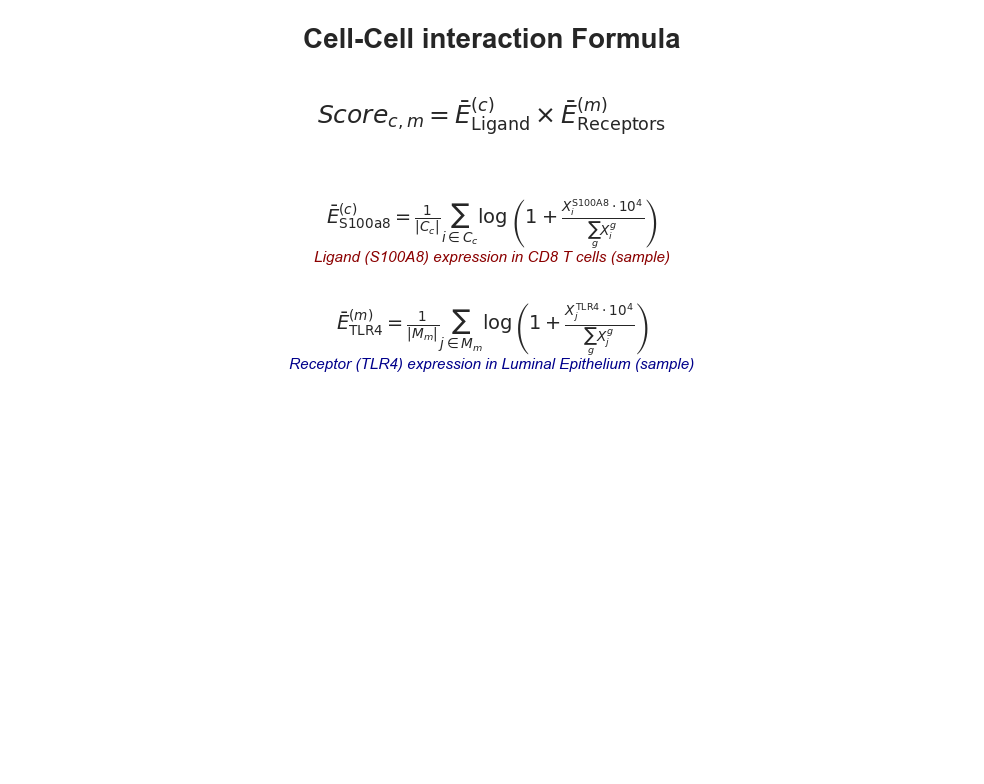

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

ax.text(5, 9.5, 'Cell-Cell interaction Formula', fontsize=20, fontweight='bold', ha='center')

ax.text(5, 8.5, r'$Score_{c,m} = \bar{E}_{\text{Ligand}}^{(c)} \times \bar{E}_{\text{Receptors}}^{(m)}$',
        fontsize=18, ha='center')

y_pos = 7.2
ax.text(5, y_pos, r'$\bar{E}_{\text{S100a8}}^{(c)} = \frac{1}{|C_c|} \sum_{i \in C_c} \log\left(1 + \frac{X_i^{\text{S100A8}} \cdot 10^4}{\sum_g X_i^g}\right)$',
        fontsize=14, ha='center')
ax.text(5, y_pos-0.5, 'Ligand (S100A8) expression in CD8 T cells (sample)',
        fontsize=11, ha='center', style='italic', color='darkred')

y_pos = 5.8
ax.text(5, y_pos, r'$\bar{E}_{\text{TLR4}}^{(m)} = \frac{1}{|M_m|} \sum_{j \in M_m} \log\left(1 + \frac{ X_j^{\text{TLR4}} \cdot 10^4}{\sum_g X_j^g}\right)$',
        fontsize=14, ha='center')
ax.text(5, y_pos-0.5, 'Receptor (TLR4) expression in Luminal Epithelium (sample)',
        fontsize=11, ha='center', style='italic', color='darkblue')

plt.tight_layout()
plt.show()

# S100A8 Group

In [1]:
import scanpy as sc
adata = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad")

In [3]:
import scanpy as sc
import pandas as pd

high_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

low_samples = [
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX27_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11282193_EX0540',
    'UA_Endo11460961_FX1097',
    'UA_Endo11596522_FX9005',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961681_SE03'
]

sample_to_group = {}

for s in high_samples:
    sample_to_group[s] = "S100A8 High"

for s in low_samples:
    sample_to_group[s] = "S100A8 Low"

adata.obs["S100A8 group"] = adata.obs["Sample name"].map(sample_to_group)

excluded_mask = adata.obs["S100A8 group"].isna()

excluded_samples = (
    adata.obs.loc[excluded_mask, "Sample name"]
    .value_counts()
    .sort_index()
)

adata = adata[~excluded_mask].copy()

print("Excluded samples and cell counts:\n")

if len(excluded_samples) == 0:
    print("No excluded samples")
else:
    for sample, count in excluded_samples.items():
        print(f"{sample}: {count} cells")

Excluded samples and cell counts:

FRZFRESH_GX25_ES345: 0 cells
FRZFRESH_GX26_ES345: 2332 cells
FRZFRESH_GX27_ES345: 0 cells
FRZFRESH_GX28_ES345: 1809 cells
HCA_A_RepT_RNA13247830_A70: 0 cells
UA_Endo9426399_FX1146: 0 cells
UA_Endo9426400_FX1146: 2653 cells
UA_Endo11173480_FX0052: 0 cells
UA_Endo11173482_FX9011: 0 cells
UA_Endo11282193_EX0540: 0 cells
UA_Endo11460961_FX1097: 0 cells
UA_Endo11460962_FX1170: 0 cells
UA_Endo11596522_FX9005: 0 cells
UA_Endo12061704_FX1163: 0 cells
UA_Endo12269810_FX1106: 0 cells
UA_Endo12296823_FX1119: 0 cells
UA_Endo12296824_FX9008: 0 cells
UA_Endo12449300_FX9027: 0 cells
UA_Endo12604667_FX1130: 0 cells
UA_Endo12680031_FX1259: 0 cells
UA_Endo12961679_SE02: 0 cells
UA_Endo12961680_SE02: 14 cells
UA_Endo12961681_SE03: 0 cells
UA_Endo12961682_SE03: 472 cells


In [9]:
import scanpy as sc
sc.tl.rank_genes_groups(adata, 'S100A8 group', method="wilcoxon",use_raw =False)
sc.tl.dendrogram(adata, groupby='S100A8 group')
result = adata.uns["rank_genes_groups"]
groups = result["names"].dtype.names
result_df = pd.DataFrame(
    {
        f"{group}_{key}": result[key][group]
        for group in groups
        for key in ["names", "pvals_adj", "logfoldchanges", "scores"]
    }
)

up_dict = {}
down_dict = {}

for group in groups:
    n_col = f"{group}_names"
    p_col = f"{group}_pvals_adj"
    l_col = f"{group}_logfoldchanges"
    s_col = f"{group}_scores"
    degs_sig = result_df[result_df[p_col] < 0.05]
    degs_up = degs_sig[degs_sig[l_col] > 1].sort_values(by=s_col, ascending=False)
    degs_dw = degs_sig[degs_sig[l_col] < -1].sort_values(by=s_col, ascending=True)
    up_dict[group] = degs_up[n_col].reset_index(drop=True)
    down_dict[group] = degs_dw[n_col].reset_index(drop=True)

df_merge_up = pd.concat(up_dict.values(), axis=1)
df_merge_up.columns = list(up_dict.keys())

df_merge_down = pd.concat(down_dict.values(), axis=1)
df_merge_down.columns = list(down_dict.keys())
sc.tl.dendrogram(adata, groupby='S100A8 group')
result = adata.uns["rank_genes_groups"]
groups = result["names"].dtype.names
result_df = pd.DataFrame(
    {
        f"{group}_{key}": result[key][group]
        for group in groups
        for key in ["names", "pvals_adj", "logfoldchanges", "scores"]
    }
)

up_dict = {}
down_dict = {}

for group in groups:
    n_col = f"{group}_names"
    p_col = f"{group}_pvals_adj"
    l_col = f"{group}_logfoldchanges"
    s_col = f"{group}_scores"
    degs_sig = result_df[result_df[p_col] < 0.05]
    degs_up = degs_sig[degs_sig[l_col] > 1].sort_values(by=s_col, ascending=False)
    degs_dw = degs_sig[degs_sig[l_col] < -1].sort_values(by=s_col, ascending=True)
    up_dict[group] = degs_up[n_col].reset_index(drop=True)
    down_dict[group] = degs_dw[n_col].reset_index(drop=True)

df_merge_up = pd.concat(up_dict.values(), axis=1)
df_merge_up.columns = list(up_dict.keys())

df_merge_down = pd.concat(down_dict.values(), axis=1)
df_merge_down.columns = list(down_dict.keys())

from qed.data import readtxt, readseurat, readscanpy
from qed.data import get_enrichment_dataframes
from qed.data import merge_df
from qed.data import query
import inspect

class GeneSet:
    def __init__(self, genes, name, annot=None):
        self.genes = genes
        self.name = name
        self.params = {}
        self.GO = []
        self.annot = annot or {}
dblist = [
    'KEGG_2021_Human',
    'Reactome_2022','MSigDB_Computational',
    'MSigDB_Hallmark_2020',
    'GO_Biological_Process_2023','WikiPathway_2023_Human','WikiPathway_2021_Human','Aging_Perturbations_from_GEO_down','Aging_Perturbations_from_GEO_up'
    'WikiPathway_2024_Human','WikiPathway_2023_Human','WikiPathways_2019_Human']

df_merge_up_100 = df_merge_up.head(20)
df_merge_up_100.to_csv('breast_cancer_DEG_up_leiden.csv', index=False, header=True)
alist = pd.read_csv('breast_cancer_DEG_up_leiden.csv')
geneset_list = []
for col in alist.columns:
    genes = alist[col].dropna().tolist()
    gs = GeneSet(genes=genes, name=col, annot={"Leiden": col})
    geneset_list.append(gs)
aalist = get_enrichment_dataframes(
    geneset_list=geneset_list,
    dblist=dblist,
    annot_colname="Leiden",
    n_jobs=None,
    handle_error=True,
    max_iter=1
)
df = merge_df(aalist)
df['Term'] = df['Term'].str.split(r'\(GO:').str[0].str.strip()
df['Term'] = df['Term'].str.split('R-H').str[0].str.strip()
df['Term'] = df['Term'].str.split('WP').str[0].str.strip()

from typing import List, Tuple, Dict
def heatmap_with_groupwise_ordering(df: pd.DataFrame,
                                     n: int,
                                     group_by: str,
                                     order_by: str = "Adjusted p-value",
                                     cmap: str = 'Blues',
                                     xlabel_rotation: int = 90,
                                     xlabel_fontsize: int = 15,
                                     ylabel_fontsize: int = 15,
                                     figsize: Tuple = (15, 10),
                                     vmin: float = None,
                                     vmax: float = None,
                                     cbar_kws: Dict = None,
                                     linewidths: float = 0.1,
                                     title: str = None,
                                     save_to_file: str = None,
                                     enable_column_order: bool = False,
                                     column_order: list = None,
                                     enable_highlight_columns: bool = False,
                                     highlight_column_names: list = None):

    if not isinstance(df, pd.DataFrame):
        raise TypeError("입력 'df'는 pandas DataFrame이어야 합니다.")
    if group_by not in df.columns:
        raise ValueError(f"'{group_by}' 컬럼이 DataFrame에 존재하지 않습니다.")
    if order_by not in df.columns:
        raise ValueError(f"'{order_by}' 컬럼이 DataFrame에 존재하지 않습니다.")
    if 'Term' not in df.columns:
        raise ValueError("'Term' 컬럼이 DataFrame에 존재하지 않습니다.")

    has_overlapping_genes = 'Overlapping genes' in df.columns
    df_copy = df.copy()
    df_copy[order_by] = pd.to_numeric(df_copy[order_by], errors='coerce')
    df = df_copy

    df['Term_lower'] = df['Term'].str.lower()

    df_filtered_by_order = df[df[order_by].notna()]
    df_ranked_per_group = (
        df_filtered_by_order
        .sort_values(order_by)
        .groupby(group_by)
        .head(n)
        .reset_index(drop=True)
    )
    if df_ranked_per_group.empty:
        print(f"⚠️ 각 그룹에서 상위 {n}개의 Term을 선택할 수 없습니다.")
        return None, None

    all_selected_terms_lower = df_ranked_per_group['Term_lower'].unique()
    overlapping_genes_pivot = pd.DataFrame()
    if has_overlapping_genes:
        overlapping_genes_df = df[df['Term_lower'].isin(all_selected_terms_lower)][['Term_lower', group_by, 'Overlapping genes']]
        overlapping_genes_df['Overlapping genes'] = overlapping_genes_df['Overlapping genes'].apply(
            lambda x: ', '.join(map(str, x)) if isinstance(x, list) else str(x)
        )
        overlapping_genes_df = overlapping_genes_df.groupby(['Term_lower', group_by])['Overlapping genes'].apply(', '.join).reset_index()
        overlapping_genes_df.rename(columns={'Term_lower': 'Term'}, inplace=True)
        overlapping_genes_pivot = overlapping_genes_df.pivot(index='Term', columns=group_by, values='Overlapping genes').fillna('')
        overlapping_genes_pivot.index = overlapping_genes_pivot.index.map(lambda x: x.capitalize())
    aggregated_df = df[df['Term_lower'].isin(all_selected_terms_lower)].groupby(['Term_lower', group_by], as_index=False)[order_by].min()
    aggregated_df.rename(columns={'Term_lower': 'Term'}, inplace=True)
    pivot_df = aggregated_df.pivot(index="Term", columns=group_by, values=order_by).fillna(1).rename_axis(None, axis=1)
    is_pvalue_column = order_by.lower() in ['adjusted p-value', 'p-value']
    pivot_df_for_heatmap = -np.log10(np.maximum(pivot_df, np.finfo(float).eps)) if is_pvalue_column else pivot_df.copy()
    pivot_df_for_heatmap.index = pivot_df_for_heatmap.index.map(lambda x: x.capitalize())
    final_pivot_df = pd.concat([pivot_df_for_heatmap, overlapping_genes_pivot], axis=1)

    if save_to_file:
        try:
            final_pivot_df.to_csv(save_to_file, encoding='utf-8-sig')
            print(f"✅ 히트맵 데이터 저장 완료: '{save_to_file}'")
        except Exception as e:
            print(f"❌ 저장 실패: {e}")

    row_order = []
    seen_terms = set()

    if enable_column_order and column_order:
        group_order_for_plot = [group for group in column_order if group in df[group_by].unique()]
    else:
        group_order_for_plot = df[group_by].unique()

    for group in group_order_for_plot:
        current_group_terms = df_ranked_per_group[df_ranked_per_group[group_by] == group].sort_values(order_by)
        for term_lower_val in current_group_terms['Term_lower']:
            capitalized_term = term_lower_val.capitalize()
            if capitalized_term in pivot_df_for_heatmap.index and capitalized_term not in seen_terms:
                row_order.append(capitalized_term)
                seen_terms.add(capitalized_term)

    clustered_data = final_pivot_df.loc[row_order]
    heatmap_data = clustered_data.select_dtypes(include=[np.number]) 
    if enable_column_order and column_order:
        valid_cols = [c for c in column_order if c in heatmap_data.columns]
        if valid_cols:
            heatmap_data = heatmap_data[valid_cols]
    else:
        try:
        # 모든 열 이름을 float으로 바꿔 보고 성공하면 오름차순 재정렬
            numeric_col_keys = [float(c) for c in heatmap_data.columns]
            sorted_cols = [col for _, col in sorted(zip(numeric_col_keys, heatmap_data.columns))]
            heatmap_data = heatmap_data[sorted_cols]
        except ValueError:
            pass

    if is_pvalue_column:
        p_values_for_annotation = 10 ** (-np.clip(heatmap_data, None, 300))
        annotations = np.where(p_values_for_annotation <= 0.05, '*', '')
        annotations = annotations.astype(object)
    else:
        annotations = False

    highlight_column_indices = []
    if enable_highlight_columns and highlight_column_names:
        highlight_column_indices = [
            list(heatmap_data.columns).index(col)
            for col in highlight_column_names if col in heatmap_data.columns
        ]

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(heatmap_data, cmap=cmap, vmin=vmin, vmax=vmax,
                linewidths=linewidths, annot=annotations, fmt='',
                linecolor='white', ax=ax, cbar_kws=cbar_kws, square=True,
                annot_kws={"size": 12, "color": "white", "weight": "bold"})

    for x in highlight_column_indices:
        ax.vlines(x + 1, *ax.get_ylim(), colors='black', linewidth=2)

    plt.xticks(rotation=xlabel_rotation, fontsize=xlabel_fontsize)
    plt.yticks(fontsize=ylabel_fontsize)
    if title:
        ax.set_title(title, fontsize=18, pad=20)
    plt.grid(False)

    if 'Term_lower' in df.columns:
        df.drop(columns='Term_lower', inplace=True)

    return fig, ax

Processing genesets:  50%|█████     | 1/2 [00:00<00:00,  1.74it/s]

Error processing S100A8 High for WikiPathway_2021_Human: Error analyzing gene list
Error processing S100A8 Low for WikiPathway_2021_Human: Error analyzing gene list
Error processing S100A8 High for MSigDB_Computational: Error analyzing gene list
Error processing S100A8 Low for MSigDB_Computational: Error analyzing gene list
Error processing S100A8 Low for Aging_Perturbations_from_GEO_down: Error analyzing gene list
Error processing S100A8 High for WikiPathway_2023_Human: Error analyzing gene list
Error processing S100A8 Low for Aging_Perturbations_from_GEO_upWikiPathway_2024_Human: Error analyzing gene list
Error processing S100A8 Low for WikiPathway_2023_Human: Error analyzing gene list
Error processing S100A8 High for GO_Biological_Process_2023: Error analyzing gene list
Error processing S100A8 Low for KEGG_2021_Human: Error analyzing gene list
Error processing S100A8 Low for WikiPathways_2019_Human: Error analyzing gene list
Error processing S100A8 High for KEGG_2021_Human: Error an

Processing genesets: 22it [00:01, 12.49it/s]                      


Trying to re-request...
S100A8 High with KEGG_2021_Human completed!
S100A8 High with MSigDB_Computational completed!
S100A8 High with GO_Biological_Process_2023 completed!
S100A8 High with WikiPathway_2021_Human completed!
S100A8 High with Aging_Perturbations_from_GEO_down completed!
Error processing S100A8 High for Aging_Perturbations_from_GEO_upWikiPathway_2024_Human: 'Aging_Perturbations_from_GEO_upWikiPathway_2024_Human'
S100A8 High with Aging_Perturbations_from_GEO_upWikiPathway_2024_Human completed!
S100A8 Low with KEGG_2021_Human completed!
S100A8 Low with MSigDB_Computational completed!
S100A8 Low with MSigDB_Hallmark_2020 completed!
S100A8 Low with GO_Biological_Process_2023 completed!
S100A8 Low with WikiPathway_2023_Human completed!
S100A8 Low with WikiPathway_2021_Human completed!
S100A8 Low with Aging_Perturbations_from_GEO_down completed!
Error processing S100A8 Low for Aging_Perturbations_from_GEO_upWikiPathway_2024_Human: 'Aging_Perturbations_from_GEO_upWikiPathway_2024

In [10]:
import pandas as pd

df.to_csv("/home/Data_Drive_8TB/kykim/1. Oval/deg_sc.csv", index=False)

In [19]:
import pandas as pd

dict_leiden = {
    "S100A8 High": [
        "Negative Regulation Of Epithelial Cell Migration",
        "Regulation Of Arp2/3 Complex-Mediated Actin Nucleation",
        "Negative Regulation Of Exocytosis / Vesicle Fusion",
        "Regulation Of Plasma Membrane Bounded Cell Projection Organization",
        "Negative Regulation Of Actin Nucleation",
        "Negative Regulation Of Leukocyte Proliferation"
    ],
    "S100A8 Low": [
        "Focal adhesion",
        "Angiogenesis",
        "Apical Junction",
        "TGF Smad Signaling Pathway",
        "Extracellular Matrix Organization",
        "Positive Regulation Of Epithelial Cell Differentiation",
        "Inflammatory Response Pathway",
        "Focal Adhesion PI3K Akt mTOR Signaling Pathway"
    ]
}

df_filtered = pd.concat([
    df[(df['Leiden'] == leiden) & (df['Term'].isin(terms))]
    for leiden, terms in dict_leiden.items()
])

df_filtered.reset_index(drop=True, inplace=True)

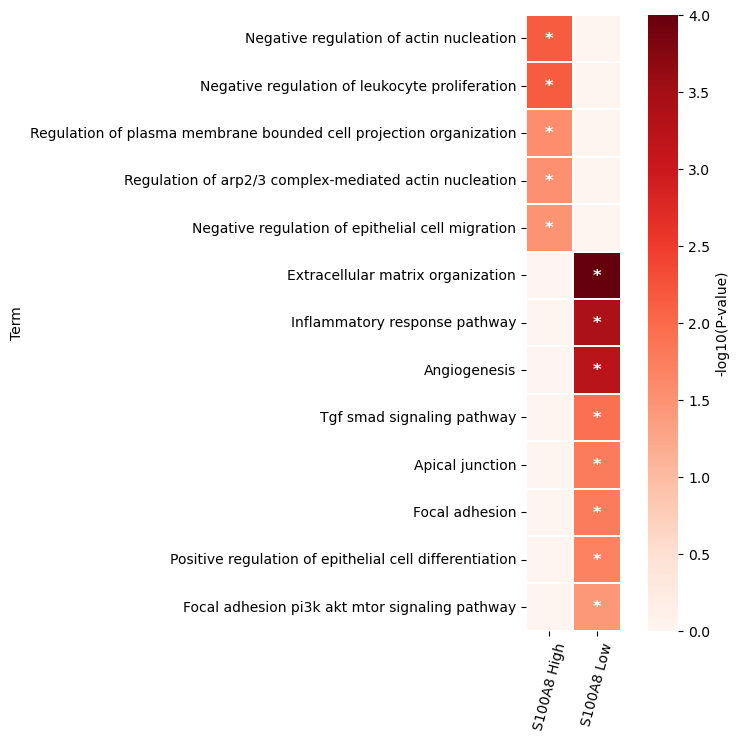

In [20]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



fig, ax = heatmap_with_groupwise_ordering(
    df=df_filtered,
    n=20,
    group_by='Leiden',
    order_by="P-value",
    cmap='Reds',
    xlabel_rotation=75,
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    figsize=(7, 8),
    vmin=0,
    vmax=4,
    cbar_kws={'shrink': 1, 'label': '-log10(P-value)'},
    enable_column_order=True,
)

In [9]:
Lymphoid = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad")

In [10]:
import scanpy as sc

adata_source = sc.read_h5ad("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad")

common_barcodes = Lymphoid.obs_names.intersection(adata_source.obs_names)

Lymphoid = Lymphoid[common_barcodes].copy()
adata_source = adata_source[common_barcodes].copy()

adata_source = adata_source[Lymphoid.obs_names].copy()

Lymphoid._X = adata_source.X.copy()
Lymphoid._var = adata_source.var.copy()
Lymphoid._n_vars = adata_source.n_vars

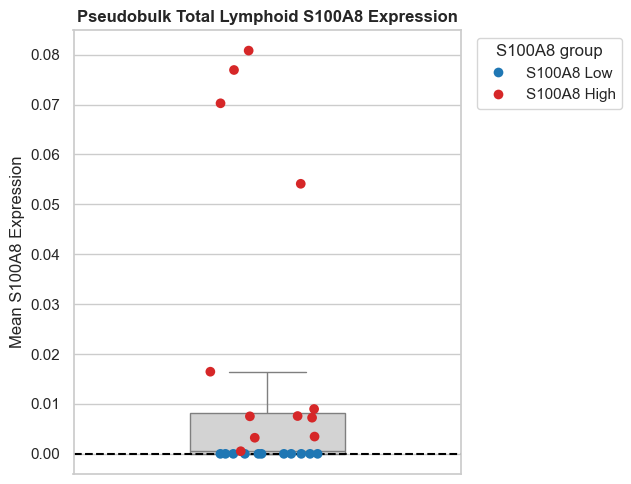

0.75 quantile cutoff = 0
High : ['UA_Endo11173480_FX0052', 'UA_Endo11173482_FX9011', 'UA_Endo11460961_FX1097', 'UA_Endo11460962_FX1170', 'UA_Endo12061704_FX1163', 'UA_Endo12269810_FX1106', 'UA_Endo12296823_FX1119', 'UA_Endo12296824_FX9008', 'UA_Endo12449300_FX9027', 'UA_Endo12604667_FX1130', 'UA_Endo12680031_FX1259', 'UA_Endo12961679_SE02']
Low : ['FRZFRESH_GX25_ES345', 'FRZFRESH_GX26_ES345', 'FRZFRESH_GX27_ES345', 'FRZFRESH_GX28_ES345', 'HCA_A_RepT_RNA13247830_A70', 'UA_Endo9426399_FX1146', 'UA_Endo11282193_EX0540', 'UA_Endo11596522_FX9005', 'UA_Endo12961680_SE02', 'UA_Endo12961681_SE03', 'UA_Endo12961682_SE03']


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

gene = "S100A8"

expr = Lymphoid[:, gene].X

if hasattr(expr, "toarray"):
    expr = expr.toarray().flatten()
else:
    expr = expr.flatten()

plot_df = pd.DataFrame({
    "Sample": Lymphoid.obs["Sample name"].values,
    "Expression": expr
})

plot_df = (
    plot_df.groupby("Sample", as_index=False)
    .agg({
        "Expression": "mean"
    })
)

plot_df = plot_df.rename(
    columns={"Expression": "MeanExpression"}
)

#cutoff = plot_df["MeanExpression"].quantile(0.50)

cutoff = 0

plot_df["Scenecent_group"] = np.where(
    plot_df["MeanExpression"] > cutoff,
    "S100A8 High",
    "S100A8 Low"
)

plt.figure(figsize=(6.5, 5))

ax = sns.boxplot(
    data=plot_df,
    y="MeanExpression",
    width=0.4,
    fliersize=0,
    color="lightgray"
)

sns.stripplot(
    data=plot_df,
    y="MeanExpression",
    hue="Scenecent_group",
    palette={
        "S100A8 Low": "#1f77b4",
        "S100A8 High": "#d62728"
    },
    size=7,
    jitter=0.15,
    ax=ax
)

plt.axhline(
    cutoff,
    linestyle="--",
    linewidth=1.5,
    color="black"
)

plt.ylabel("Mean S100A8 Expression")

plt.title(
    "Pseudobulk Total Lymphoid S100A8 Expression",
    fontweight="bold"
)

handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles[:2],
    labels[:2],
    title="S100A8 group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

high_samples = plot_df[
    plot_df["Scenecent_group"] == "S100A8 High"
]["Sample"].tolist()

low_samples = plot_df[
    plot_df["Scenecent_group"] == "S100A8 Low"
]["Sample"].tolist()

print(f"0.75 quantile cutoff = {cutoff}")

print(f"High : {high_samples}")
print(f"Low : {low_samples}")

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings
import math

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

high_samples = [
'UA_Endo11173480_FX0052', 'UA_Endo11173482_FX9011', 'UA_Endo11460961_FX1097', 'UA_Endo11460962_FX1170', 'UA_Endo12061704_FX1163', 'UA_Endo12269810_FX1106', 'UA_Endo12296823_FX1119', 'UA_Endo12296824_FX9008', 'UA_Endo12449300_FX9027', 'UA_Endo12604667_FX1130', 'UA_Endo12680031_FX1259', 'UA_Endo12961679_SE02'
]

clin_palette = {
    'High': '#d62728',
    'Low': '#1f77b4'
}

label_map = {
    'High': 'S100A8 High',
    'Low': 'S100A8 Low'
}

Epithelial.obs['Each mouse'] = Epithelial.obs['Sample name']

adata_filtered = Epithelial[
    Epithelial.obs['Organism part'] != 'spleen'
].copy()

adata_filtered.obs['S100A8_group'] = np.where(
    adata_filtered.obs['Sample name'].isin(high_samples),
    'High',
    'Low'
)

group_order = ['High', 'Low']

celltype_groups = sorted(
    adata_filtered.obs['celltype_grouped']
    .dropna()
    .unique()
)

def normalize_mouse(df):

    total = df['count'].sum()

    if total > 0:
        df['proportion'] = df['count'] / total
    else:
        df['proportion'] = 0

    return df

mouse_props_list = []

for (mouse, s100_group), grp_df in adata_filtered.obs.groupby(
    ['Each mouse', 'S100A8_group']
):

    count_df = (
        grp_df.groupby('celltype_grouped')
        .size()
        .reset_index(name='count')
    )

    count_df['Each mouse'] = mouse
    count_df['S100A8_group'] = s100_group

    count_df = normalize_mouse(count_df)

    mouse_props_list.append(count_df)

mouse_props = pd.concat(
    mouse_props_list,
    ignore_index=True
)

n_celltypes = len(celltype_groups)

n_cols = 5
n_rows = int(np.ceil(n_celltypes / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(2.85 * n_cols, 3.5 * n_rows),
    sharey=True
)

axes = np.array(axes).flatten()

for i, ct in enumerate(celltype_groups):

    ax = axes[i]

    data_sub = mouse_props[
        mouse_props['celltype_grouped'] == ct
    ]

    sns.boxplot(
        x='S100A8_group',
        y='proportion',
        data=data_sub,
        order=group_order,
        ax=ax,
        boxprops={'facecolor': 'lightgray'},
        width=0.45,
        fliersize=0
    )

    for cond in group_order:

        sub_df = data_sub[
            data_sub['S100A8_group'] == cond
        ]

        sns.stripplot(
            x='S100A8_group',
            y='proportion',
            data=sub_df,
            order=group_order,
            color=clin_palette[cond],
            jitter=0.2,
            size=5,
            ax=ax
        )

    v1 = data_sub[
        data_sub['S100A8_group'] == 'High'
    ]['proportion']

    v2 = data_sub[
        data_sub['S100A8_group'] == 'Low'
    ]['proportion']

    if len(v1) > 0 and len(v2) > 0:

        _, p = ranksums(v1, v2)

        p_trunc = (
            math.floor(p * 100) / 100
        )

        sig = (
            "***" if p < 0.001 else
            "**" if p < 0.01 else
            "*" if p < 0.06 else
            "n.s"
        )

        x1, x2 = 0, 1

        ymax = data_sub['proportion'].max()

        y = ymax * 1.08 if ymax > 0 else 0.05

        ax.plot(
            [x1, x1, x2, x2],
            [y, y + 0.01, y + 0.01, y],
            c='red'
        )

        ax.text(
            (x1 + x2) / 2,
            y + 0.015,
            f"{sig}\n(p={p_trunc:.2f})",
            ha='center',
            color='red',
            fontsize=9,
            fontweight='bold'
        )

    ax.set_xticklabels(
        [label_map[x] for x in group_order],
        rotation=20
    )

    ax.set_title(
        ct,
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel("")
    ax.set_ylabel("Cell proportion")

for j in range(len(celltype_groups), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

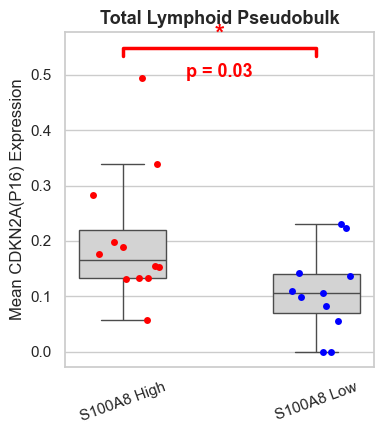

In [12]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ranksums
import warnings

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

high_samples = [
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11460961_FX1097',
    'UA_Endo11460962_FX1170',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296823_FX1119',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961679_SE02'
]

low_samples = [
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX26_ES345',
    'FRZFRESH_GX27_ES345',
    'FRZFRESH_GX28_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11282193_EX0540',
    'UA_Endo11596522_FX9005',
    'UA_Endo12961680_SE02',
    'UA_Endo12961681_SE03',
    'UA_Endo12961682_SE03'
]

clin_palette = {
    'High': '#ff0000',
    'Low': '#0000ff',
}

label_map = {
    'High': 'S100A8 High',
    'Low': 'S100A8 Low'
}

group_order = ['High', 'Low']

gene = "CDKN2A"
sample_col = "Sample name"

expr = Lymphoid[:, gene].X

if hasattr(expr, "toarray"):
    expr = expr.toarray().flatten()
else:
    expr = np.array(expr).flatten()

df = pd.DataFrame({
    "Sample": Lymphoid.obs[sample_col].values,
    "Expression": expr
})

pseudobulk = (
    df.groupby("Sample")["Expression"]
    .mean()
    .reset_index()
)

pseudobulk["Group"] = "Other"

pseudobulk.loc[
    pseudobulk["Sample"].isin(high_samples),
    "Group"
] = "High"

pseudobulk.loc[
    pseudobulk["Sample"].isin(low_samples),
    "Group"
] = "Low"

pseudobulk = pseudobulk[
    pseudobulk["Group"].isin(["High", "Low"])
]

high_vals = pseudobulk.loc[
    pseudobulk["Group"] == "High",
    "Expression"
]

low_vals = pseudobulk.loc[
    pseudobulk["Group"] == "Low",
    "Expression"
]

stat, pval = ranksums(high_vals, low_vals)

fig, ax = plt.subplots(figsize=(4, 4.5))

sns.boxplot(
    x='Group',
    y='Expression',
    data=pseudobulk,
    ax=ax,
    order=group_order,
    boxprops={'facecolor': 'lightgray'},
    fliersize=0,
    width=0.45
)

for cond in pseudobulk['Group'].unique():

    sub_df = pseudobulk[
        pseudobulk['Group'] == cond
    ]

    sns.stripplot(
        x='Group',
        y='Expression',
        data=sub_df,
        color=clin_palette.get(cond, 'black'),
        jitter=0.2,
        size=5,
        ax=ax,
        order=group_order
    )

x1, x2 = 0, 1

y = pseudobulk["Expression"].max() * 1.08
h = pseudobulk["Expression"].max() * 0.03

ax.plot(
    [x1, x1, x2, x2],
    [y, y + h, y + h, y],
    c='red',
    linewidth=2.5
)

ax.text(
    (x1 + x2) / 2,
    y + h * 1.15,
    "*",
    ha='center',
    va='bottom',
    color='red',
    fontsize=18,
    fontweight='bold'
)

ax.text(
    (x1 + x2) / 2,
    y - h * 0.9,
    f"p = {pval:.2f}",
    ha='center',
    va='top',
    color='red',
    fontsize=13,
    fontweight='bold'
)

ax.set_xticklabels(
    [label_map[x] for x in group_order],
    rotation=20
)

ax.set_ylabel(f"Mean {gene}(P16) Expression")
ax.set_xlabel("")

ax.set_title(
    "Total Lymphoid Pseudobulk",
    fontweight='bold',
    fontsize=13
)

plt.tight_layout()
plt.show()

=== CD8 High ∩ Lymphoid High ===
['UA_Endo11460962_FX1170', 'UA_Endo12296823_FX1119', 'UA_Endo12961679_SE02']

=== CD8 Low ∩ Lymphoid Low ===
['FRZFRESH_GX25_ES345', 'FRZFRESH_GX27_ES345', 'HCA_A_RepT_RNA13247830_A70', 'UA_Endo11282193_EX0540', 'UA_Endo11596522_FX9005', 'UA_Endo12961681_SE03', 'UA_Endo9426399_FX1146']


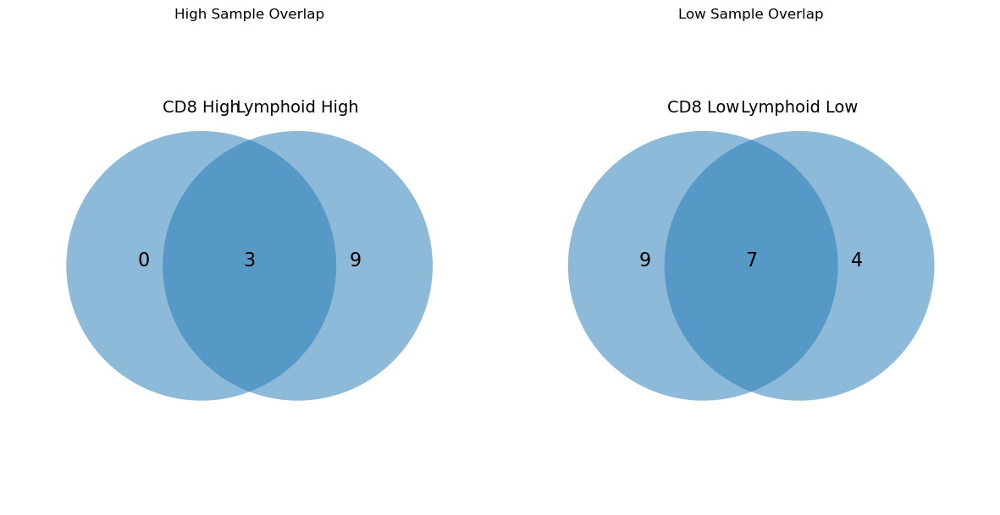

In [101]:
import matplotlib.pyplot as plt

cd8_high = set([
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
])

cd8_low = set([
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX27_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11282193_EX0540',
    'UA_Endo11460961_FX1097',
    'UA_Endo11596522_FX9005',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961681_SE03'
])

lymphoid_high = set([
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11460961_FX1097',
    'UA_Endo11460962_FX1170',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296823_FX1119',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961679_SE02'
])

lymphoid_low = set([
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX26_ES345',
    'FRZFRESH_GX27_ES345',
    'FRZFRESH_GX28_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11282193_EX0540',
    'UA_Endo11596522_FX9005',
    'UA_Endo12961680_SE02',
    'UA_Endo12961681_SE03',
    'UA_Endo12961682_SE03'
])

high_intersection = cd8_high & lymphoid_high
low_intersection = cd8_low & lymphoid_low

print("=== CD8 High ∩ Lymphoid High ===")
print(sorted(high_intersection))

print("\n=== CD8 Low ∩ Lymphoid Low ===")
print(sorted(low_intersection))

fig, axes = plt.subplots(1, 2, figsize=(12,6))

ax = axes[0]

circle1 = plt.Circle((0.4, 0.5), 0.28, alpha=0.5)
circle2 = plt.Circle((0.6, 0.5), 0.28, alpha=0.5)

ax.add_patch(circle1)
ax.add_patch(circle2)

ax.text(
    0.28,
    0.5,
    f"{len(cd8_high - lymphoid_high)}",
    fontsize=16,
    ha='center'
)

ax.text(
    0.72,
    0.5,
    f"{len(lymphoid_high - cd8_high)}",
    fontsize=16,
    ha='center'
)

ax.text(
    0.5,
    0.5,
    f"{len(high_intersection)}",
    fontsize=16,
    ha='center'
)

ax.text(
    0.4,
    0.82,
    "CD8 High",
    fontsize=14,
    ha='center'
)

ax.text(
    0.6,
    0.82,
    "Lymphoid High",
    fontsize=14,
    ha='center'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.axis('off')

ax.set_title("High Sample Overlap")

ax = axes[1]

circle1 = plt.Circle((0.4, 0.5), 0.28, alpha=0.5)
circle2 = plt.Circle((0.6, 0.5), 0.28, alpha=0.5)

ax.add_patch(circle1)
ax.add_patch(circle2)

ax.text(
    0.28,
    0.5,
    f"{len(cd8_low - lymphoid_low)}",
    fontsize=16,
    ha='center'
)

ax.text(
    0.72,
    0.5,
    f"{len(lymphoid_low - cd8_low)}",
    fontsize=16,
    ha='center'
)

ax.text(
    0.5,
    0.5,
    f"{len(low_intersection)}",
    fontsize=16,
    ha='center'
)

ax.text(
    0.4,
    0.82,
    "CD8 Low",
    fontsize=14,
    ha='center'
)

ax.text(
    0.6,
    0.82,
    "Lymphoid Low",
    fontsize=14,
    ha='center'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.axis('off')

ax.set_title("Low Sample Overlap")

plt.tight_layout()
plt.show()

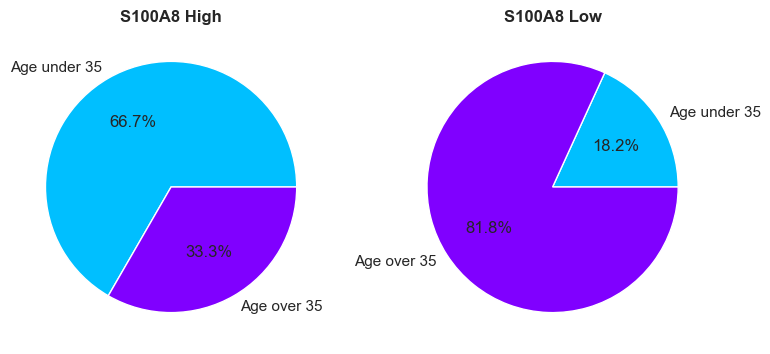

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

high_samples = [
    'UA_Endo11173480_FX0052',
    'UA_Endo11173482_FX9011',
    'UA_Endo11460961_FX1097',
    'UA_Endo11460962_FX1170',
    'UA_Endo12061704_FX1163',
    'UA_Endo12269810_FX1106',
    'UA_Endo12296823_FX1119',
    'UA_Endo12296824_FX9008',
    'UA_Endo12449300_FX9027',
    'UA_Endo12604667_FX1130',
    'UA_Endo12680031_FX1259',
    'UA_Endo12961679_SE02'
]

low_samples = [
    'FRZFRESH_GX25_ES345',
    'FRZFRESH_GX26_ES345',
    'FRZFRESH_GX27_ES345',
    'FRZFRESH_GX28_ES345',
    'HCA_A_RepT_RNA13247830_A70',
    'UA_Endo9426399_FX1146',
    'UA_Endo11282193_EX0540',
    'UA_Endo11596522_FX9005',
    'UA_Endo12961680_SE02',
    'UA_Endo12961681_SE03',
    'UA_Endo12961682_SE03'
]

sample_age = (
    Epithelial.obs[
        ["Sample name", "Age group"]
    ]
    .drop_duplicates()
)

high_age = sample_age[
    sample_age["Sample name"].isin(high_samples)
]

low_age = sample_age[
    sample_age["Sample name"].isin(low_samples)
]

high_counts = (
    high_age["Age group"]
    .value_counts()
    .reindex(["Young", "Aged"], fill_value=0)
)

low_counts = (
    low_age["Age group"]
    .value_counts()
    .reindex(["Young", "Aged"], fill_value=0)
)

label_map = {
    "Young": "Age under 35",
    "Aged": "Age over 35"
}

colors = {
    "Young": "#00bfff",
    "Aged": "#8000ff"
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 4)
)

axes[0].pie(
    high_counts.values,
    labels=[
        label_map[x]
        for x in high_counts.index
    ],
    colors=[
        colors[x]
        for x in high_counts.index
    ],
    autopct="%1.1f%%"
)

axes[0].set_title(
    "S100A8 High",
    fontweight="bold"
)

axes[1].pie(
    low_counts.values,
    labels=[
        label_map[x]
        for x in low_counts.index
    ],
    colors=[
        colors[x]
        for x in low_counts.index
    ],
    autopct="%1.1f%%"
)

axes[1].set_title(
    "S100A8 Low",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [34]:
import scanpy as sc
import pandas as pd

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Lymphoid.h5ad"
)

target_samples = [
    'UA_Endo11460962_FX1170',
    'UA_Endo12296823_FX1119',
    'UA_Endo12961679_SE02'
]

obs = Epithelial.obs.copy()

sample_col = "Sample name"
age_col = "Age"

filtered = obs[
    obs[sample_col].isin(target_samples) &
    obs[age_col].notna()
]

print(filtered.groupby(sample_col)[age_col].mean())
print("Overall mean age:", filtered[age_col].mean())

Sample name
FRZFRESH_GX25_ES345            NaN
FRZFRESH_GX26_ES345            NaN
FRZFRESH_GX27_ES345            NaN
FRZFRESH_GX28_ES345            NaN
HCA_A_RepT_RNA13247830_A70     NaN
UA_Endo9426399_FX1146          NaN
UA_Endo11173480_FX0052         NaN
UA_Endo11173482_FX9011         NaN
UA_Endo11282193_EX0540         NaN
UA_Endo11460961_FX1097         NaN
UA_Endo11460962_FX1170        34.0
UA_Endo11596522_FX9005         NaN
UA_Endo12061704_FX1163         NaN
UA_Endo12269810_FX1106         NaN
UA_Endo12296823_FX1119        30.0
UA_Endo12296824_FX9008         NaN
UA_Endo12449300_FX9027         NaN
UA_Endo12604667_FX1130         NaN
UA_Endo12680031_FX1259         NaN
UA_Endo12961679_SE02          38.0
UA_Endo12961680_SE02           NaN
UA_Endo12961681_SE03           NaN
UA_Endo12961682_SE03           NaN
Name: Age, dtype: float64
Overall mean age: 31.098181818181818


# Tgfb activation

In [85]:
import scanpy as sc
import pandas as pd

adata = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/after_QC_Before_HVG_raw.h5ad"
)

Epithelial = sc.read_h5ad(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/h5ad/Epithelial.h5ad"
)

epi_cells = Epithelial.obs_names[
    Epithelial.obs["subtype"] == "Luminal Epithelium"
]

adata = adata[epi_cells].copy()

adata.obs["subtype"] = "Luminal Epithelium"

print(adata.obs["subtype"].value_counts())

subtype
Luminal Epithelium    22262
Name: count, dtype: int64


In [86]:
adata.write("/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/AUCell/lymph_epi.h5ad")

In [35]:
from mygene import MyGeneInfo
import pandas as pd

TF = [
    'Tgfb1', 'Acvr1', 'Rhoa', 'Smurf2', 'Smurf1', 'Hipk2', 'Tgfbr1',
    'Ppp1ca', 'Cdk9', 'Ski', 'Rab31', 'Apc', 'Bmp2', 'Ncor2', 'Id1',
    'Id3', 'Id2', 'Bmpr1a', 'Bcar3', 'Bmpr2', 'Serpine1',
    'Ppp1r15a', 'Arid4b', 'Cdh1', 'Map3k7', 'Skil', 'Sptbn1',
    'Smad3', 'Wwtr1', 'Tgif1', 'Lefty1', 'Nog', 'Ifngr2', 'Smad1',
    'Klf10', 'Smad7', 'Smad6', 'Ppm1a', 'Fkbp1a', 'Tjp1', 'Xiap',
    'Eng', 'Trim33', 'Cdkn1c', 'Hdac1', 'Furin', 'Ctnnb1',
    'Slc20a1', 'Thbs1', 'Ltbp2', 'Fnta', 'Pmepa1', 'Junb'
]

mg = MyGeneInfo()

df_mouse_query = mg.querymany(
    TF,
    scopes="symbol",
    fields=["homologene", "symbol"],
    species="mouse",
    as_dataframe=True,
)

exploded = df_mouse_query["homologene.genes"].dropna().explode()

human_df = pd.DataFrame(
    exploded.tolist(),
    index=exploded.index,
    columns=["tax_id", "human_entrez"]
)

human_df = human_df[human_df["tax_id"] == 9606]
human_df = human_df[~human_df.index.duplicated(keep="first")]

mouse_to_human_entrez = (
    human_df["human_entrez"]
    .astype(str)
    .to_dict()
)

entrez_ids = list(set(mouse_to_human_entrez.values()))

df_entrez_to_symbol = mg.querymany(
    entrez_ids,
    scopes="entrezgene",
    fields="symbol",
    species="human",
    as_dataframe=True,
)

df_entrez_to_symbol = df_entrez_to_symbol.dropna(subset=["symbol"])

entrez_to_symbol = (
    df_entrez_to_symbol["symbol"]
    .to_dict()
)

mouse_to_human_symbol = {
    k: entrez_to_symbol[v]
    for k, v in mouse_to_human_entrez.items()
    if v in entrez_to_symbol
}

TF_human = [
    mouse_to_human_symbol[g]
    for g in TF
    if g in mouse_to_human_symbol
]

print(TF_human)

querying 1-53...done.
Finished.
done.ing 1-51...
Finished.
['TGFB1', 'ACVR1', 'RHOA', 'SMURF2', 'SMURF1', 'HIPK2', 'TGFBR1', 'PPP1CA', 'CDK9', 'SKI', 'RAB31', 'APC', 'BMP2', 'NCOR2', 'ID1', 'ID3', 'ID2', 'BMPR1A', 'BCAR3', 'BMPR2', 'SERPINE1', 'PPP1R15A', 'ARID4B', 'CDH1', 'SKIL', 'SPTBN1', 'SMAD3', 'WWTR1', 'TGIF1', 'LEFTY1', 'NOG', 'IFNGR2', 'SMAD1', 'KLF10', 'SMAD7', 'SMAD6', 'PPM1A', 'FKBP1A', 'TJP1', 'XIAP', 'ENG', 'TRIM33', 'HDAC1', 'FURIN', 'CTNNB1', 'SLC20A1', 'THBS1', 'LTBP2', 'FNTA', 'PMEPA1', 'JUNB']


In [88]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

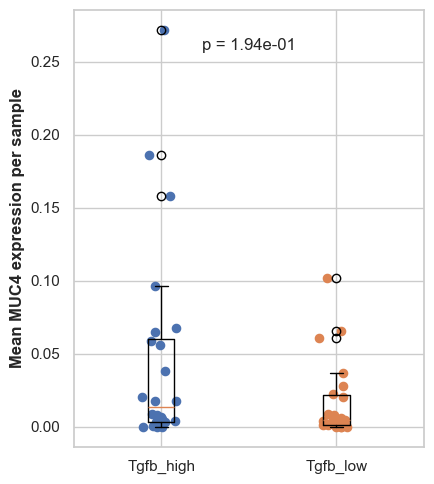

In [95]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ranksums

tgfb = pd.read_csv(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/AUCell/Tgfb.csv"
)

high_barcodes = set(tgfb["barcode"])

adata.obs["Tgfb_group"] = np.where(
    adata.obs_names.isin(high_barcodes),
    "Tgfb_high",
    "Tgfb_low"
)

muc4_expr = adata[:, "MUC4"].X

if not isinstance(muc4_expr, np.ndarray):
    muc4_expr = muc4_expr.toarray()

adata.obs["MUC4_expr"] = muc4_expr.flatten()

sample_mean = (
    adata.obs
    .groupby(["Sample name", "Tgfb_group"])["MUC4_expr"]
    .mean()
    .reset_index()
)

sample_mean = sample_mean.dropna(subset=["MUC4_expr"])

high_values = sample_mean.loc[
    sample_mean["Tgfb_group"] == "Tgfb_high",
    "MUC4_expr"
].dropna()

low_values = sample_mean.loc[
    sample_mean["Tgfb_group"] == "Tgfb_low",
    "MUC4_expr"
].dropna()

stat, pval = ranksums(high_values, low_values)

plt.figure(figsize=(4.5, 5))

plt.boxplot(
    [high_values, low_values],
    labels=["Tgfb_high", "Tgfb_low"]
)

x1 = np.random.normal(1, 0.04, size=len(high_values))
x2 = np.random.normal(2, 0.04, size=len(low_values))

plt.scatter(x1, high_values, s=35)
plt.scatter(x2, low_values, s=35)

plt.ylabel("Mean MUC4 expression per sample", fontweight="bold")

plt.text(
    1.5,
    sample_mean["MUC4_expr"].max() * 0.95,
    f"p = {pval:.2e}",
    ha="center"
)

plt.tight_layout()
plt.show()

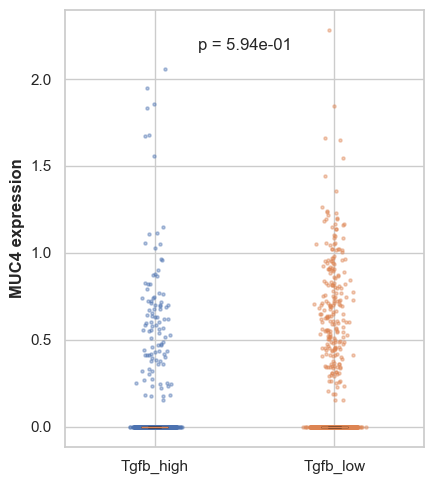

In [99]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ranksums

tgfb = pd.read_csv(
    "/home/Data_Drive_8TB_3/kykim/Uterus/Human/scRNA/AUCell/Tgfb.csv"
)

high_barcodes = set(tgfb["barcode"])

adata.obs["Tgfb_group"] = np.where(
    adata.obs_names.isin(high_barcodes),
    "Tgfb_high",
    "Tgfb_low"
)

muc4_expr = adata[:, "MUC4"].X

if not isinstance(muc4_expr, np.ndarray):
    muc4_expr = muc4_expr.toarray()

adata.obs["MUC4_expr"] = muc4_expr.flatten()

plot_df = adata.obs[["Tgfb_group", "MUC4_expr"]].copy()

plot_df = plot_df.dropna(subset=["MUC4_expr"])

plot_df = plot_df[
    plot_df["MUC4_expr"] > -1
]

high_values = plot_df.loc[
    plot_df["Tgfb_group"] == "Tgfb_high",
    "MUC4_expr"
]

low_values = plot_df.loc[
    plot_df["Tgfb_group"] == "Tgfb_low",
    "MUC4_expr"
]

stat, pval = ranksums(high_values, low_values)

plt.figure(figsize=(4.5, 5))

plt.boxplot(
    [high_values, low_values],
    labels=["Tgfb_high", "Tgfb_low"],
    patch_artist=True,
    showfliers=False
)

x1 = np.random.normal(1, 0.04, size=len(high_values))
x2 = np.random.normal(2, 0.04, size=len(low_values))

plt.scatter(x1, high_values, s=5, alpha=0.4)
plt.scatter(x2, low_values, s=5, alpha=0.4)

plt.ylabel("MUC4 expression", fontweight="bold")

plt.text(
    1.5,
    plot_df["MUC4_expr"].max() * 0.95,
    f"p = {pval:.2e}",
    ha="center"
)

plt.tight_layout()
plt.show()